# Wastewater effluent quality and mineral prediction

**Sneha Deepika Vemanapalli — explained step-by-step research notebook**

This notebook preserves the original learning sequence. Data inspection comes first. BOD, COD, TSS, total nitrogen, total phosphorus, pH, lithium, cobalt, nickel, and manganese then have their own sections. Each section shows the data preparation, model comparison, selection, validation predictions, final fitting, test results, diagnostic plots, and saved files separately.

Each step explains **what we do, why we do it, and which output to examine**. Shared calculation and plotting functions are defined once to remove duplicated implementation. The repeated sequence of steps for different targets is intentional: each target is a separate experiment.

The first part preserves the original primary experiment. Supplementary checks from the revised report are collected at the end and clearly labeled. The report's figures are displayed again together so they are easy to locate.

**Run in order:** put the supplied workbook beside this notebook or in `data/`, then restart the kernel and run all cells. If several workbook versions are present, set `WASTEWATER_DATA` to the intended file. Results are written to `research_outputs/` and `stepwise_outputs/`. The workbook is not edited.

**Consistent colors:** training is blue, validation is gold, and testing is green in partition plots. Prediction and residual plots use fixed colors for WWTP-01 through WWTP-05. Black dashed lines mark equality or zero residual. All report figures use these same conventions.

## 1 Import libraries and define the experiment

These imports support loading, inspecting, fitting, evaluating, and plotting. The candidate settings retain the original experiment. Importing a library does not train a model. Dataset discovery accepts the supplied filename without requiring a hard-coded personal computer path.

In [1083]:
from pathlib import Path
import os
import json
import hashlib
import platform
import sys
import io
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
# matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



In [1084]:
SEED = 42


if os.environ.get('WASTEWATER_DATA'):
    DATA_PATH = Path(os.environ['WASTEWATER_DATA'])
else:
    candidates = sorted(set(p.resolve() for root in [Path('.'), Path('data'), Path('upload')]
                            for p in root.glob('Wastewater_Effluent_and_Critical_Minerals_ML_Project*.xlsx')))
    if len(candidates) != 1:
        raise FileNotFoundError('Expected one project workbook. Set WASTEWATER_DATA to its path.')
    DATA_PATH = candidates[0]
OUT = Path(os.environ.get('WASTEWATER_OUTPUT', 'research_outputs'))
for folder in ['', 'tables', 'figures', 'models']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 120, 'savefig.dpi': 220})


In [1085]:
TARGETS = [
    ('pH', 'effluent_ph', 'pH units'),
    ('BOD', 'effluent_bod_mg_l', 'mg/L'),
    ('COD', 'effluent_cod_mg_l', 'mg/L'),
    ('TSS', 'effluent_tss_mg_l', 'mg/L'),
    ('Total nitrogen', 'effluent_total_nitrogen_mg_l', 'mg/L'),
    ('Total phosphorus', 'effluent_total_phosphorus_mg_l', 'mg/L'),
    ('Lithium', 'effluent_lithium_ug_l', 'µg/L'),
    ('Cobalt', 'effluent_cobalt_ug_l', 'µg/L'),
    ('Nickel', 'effluent_nickel_ug_l', 'µg/L'),
    ('Manganese', 'effluent_manganese_ug_l', 'µg/L')]

CAT = ['plant_id', 'wastewater_source', 'treatment_process', 'season']


In [1086]:
MODELS = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, solver='lsqr'),
    'Lasso': Lasso(alpha=0.1, max_iter=10000),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.05,
                                                 max_depth=3, random_state=SEED),
    'SVR': SVR(kernel='rbf', C=10.0, epsilon=0.1),
    'KNN': KNeighborsRegressor(n_neighbors=10, weights='distance')}

In [1087]:
def save_table(table, name):
    table.to_csv(OUT / 'tables' / f'{name}.csv', index=False)
    return table


In [1088]:
def show_table(table):
    """Console display also captured in the executed notebook."""
    print(table.to_string(index=False, float_format=lambda v: f'{v:.4f}'))


In [1089]:
def save_figure(fig, name):
    fig.tight_layout()
    raster = io.BytesIO()
    fig.savefig(raster, format='png', bbox_inches='tight')
    png_path = OUT / 'figures' / f'{name}.png'
    staged_path = png_path.with_suffix('.png.tmp')
    staged_path.write_bytes(raster.getvalue())
    staged_path.replace(png_path)
    # Read the exported raster once so truncated output cannot pass unnoticed.
    plt.imread(OUT / 'figures' / f'{name}.png')
    vector = io.BytesIO()
    fig.savefig(vector, format='pdf', bbox_inches='tight')
    pdf_path = OUT / 'figures' / f'{name}.pdf'
    staged_path = pdf_path.with_suffix('.pdf.tmp')
    staged_path.write_bytes(vector.getvalue())
    staged_path.replace(pdf_path)
    if 'ipykernel' in sys.modules:
        from IPython.display import display
        display(fig)
    else:
        plt.show()  # The execution verifier captures figures in a plain Python process.
    plt.close(fig)


In [1090]:
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if hasattr(value, 'to_string') else value)

STEP_OUT = Path('stepwise_outputs')
STEP_OUT.mkdir(exist_ok=True)
TRAIN_COLOR, VALIDATION_COLOR, TEST_COLOR = '#39749b', '#dfaa4b', '#68977e'
PLANT_COLORS = dict(zip(['WWTP-01','WWTP-02','WWTP-03','WWTP-04','WWTP-05'],
                       ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']))
results = {}
print('Workbook:', DATA_PATH.name)
print('Primary candidates:', ', '.join(MODELS))

Workbook: Wastewater_Effluent_and_Critical_Minerals_ML_Project.xlsx
Primary candidates: Mean baseline, Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting, SVR, KNN


## 2 Load and inspect the data

We inspect the original observations before modeling. Descriptive checks use the supplied data, but learned imputation and scaling will be fitted inside training pipelines. We retain unusual observations unless there is evidence that they are invalid.

### 2.1 Load the shared dataset

**Why this step?** Each row must represent the expected plant and date. Loading the shared data and dictionary keeps the column definitions available.

**Output to examine:** Dataset dimensions, the first rows, and target-specific availability.

In [1091]:
data = pd.read_excel(DATA_PATH, sheet_name='Shared Dataset')

dictionary = pd.read_excel(DATA_PATH, sheet_name='Data Dictionary')

data['observation_date'] = pd.to_datetime(data['observation_date'], errors='raise')

data = data.sort_values(['observation_date', 'plant_id']).reset_index(drop=True)



In [1092]:
NUM = [c for c in data if c.startswith('influent_')]
FEATURES = NUM + CAT

assert data.shape == (850, 36), 'Dataset version differs from the audited workbook.'
assert len(FEATURES) == 17
assert not any(c.startswith('effluent_') for c in FEATURES)
assert not data['record_id'].duplicated().any()
assert not data.duplicated(['observation_date', 'plant_id']).any()
assert not data.duplicated().any()
assert data[NUM].apply(lambda c: np.isfinite(c.dropna()).all()).all()

dates = pd.DatetimeIndex(data['observation_date'].unique()).sort_values()
VALID_START = dates[int(len(dates) * .6)]
TEST_START = dates[int(len(dates) * .8)]

assert dates.to_series().diff().dropna().eq(pd.Timedelta(days=1)).all()

missing = save_table(pd.DataFrame({'Column': data.columns, 'Missing': data.isna().sum().values,
                                  'Missing percent': data.isna().mean().values * 100}), 'missingness')
save_table(data.describe(include='number').T.reset_index(names='Column'), 'numeric_summary')



,Column,count,mean,std,min,25%,50%,75%,max
0,rainfall_mm,844.0,2.728791,5.029317,0.00,0.0000,0.000,3.7250,25.90
1,air_temperature_c,844.0,14.547749,9.242940,-8.00,7.0000,15.150,22.2000,34.80
2,influent_flow_m3_day,847.0,15498.643447,3993.474854,8798.00,12114.5000,14650.000,18867.0000,26281.00
3,influent_temperature_c,845.0,19.975030,4.769463,8.60,16.3000,20.200,23.7000,29.00
4,influent_ph,849.0,7.101355,0.278780,6.20,6.9200,7.100,7.2800,8.30
5,influent_bod_mg_l,849.0,264.619435,43.040568,126.70,234.8000,262.500,294.4000,402.70
6,influent_cod_mg_l,849.0,594.687515,105.732178,276.80,515.8000,587.900,665.2000,920.00
7,influent_tss_mg_l,850.0,210.586588,38.140161,85.00,184.1250,210.000,235.1750,317.80
8,influent_total_nitrogen_mg_l,848.0,42.013915,7.244238,22.60,36.9000,42.100,47.0250,63.90
9,influent_total_phosphorus_mg_l,845.0,6.774698,1.202259,3.37,5.9500,6.810,7.5600,11.17


In [1093]:
availability = save_table(pd.DataFrame([
    {'Target': label, 'Unit': unit, 'Missing': int(data[col].isna().sum()),
     **{name: int((mask & data[col].notna()).sum()) for name, mask in [
         ('Train', data.observation_date < VALID_START),
         ('Validation', data.observation_date.between(VALID_START, TEST_START, inclusive='left')),
         ('Test', data.observation_date >= TEST_START)]}}
    for label, col, unit in TARGETS]), 'target_availability')

audit = {'rows': len(data), 'columns': len(data.columns), 'dates': len(dates),
         'plants': data.plant_id.nunique(), 'missing_cells': int(data.isna().sum().sum()),
         'duplicate_rows': int(data.duplicated().sum()),
         'loads_above_100': int(data.plant_load_pct.gt(100).sum()),
         'minimum_air_temperature': float(data.air_temperature_c.min()),
         'bod_values_equal_46': int(data.effluent_bod_mg_l.eq(46).sum())}
print(json.dumps(audit, indent=2))


{
  "rows": 850,
  "columns": 36,
  "dates": 170,
  "plants": 5,
  "missing_cells": 95,
  "duplicate_rows": 0,
  "loads_above_100": 2,
  "minimum_air_temperature": -8.0,
  "bod_values_equal_46": 87
}


In [1094]:
display(availability)

,Target,Unit,Missing,Train,Validation,Test
0,pH,pH units,1,509,170,170
1,BOD,mg/L,3,508,169,170
2,COD,mg/L,6,505,170,169
3,TSS,mg/L,2,509,169,170
4,Total nitrogen,mg/L,0,510,170,170
5,Total phosphorus,mg/L,3,508,170,169
6,Lithium,µg/L,0,510,170,170
7,Cobalt,µg/L,6,505,170,169
8,Nickel,µg/L,5,506,169,170
9,Manganese,µg/L,0,510,170,170


In [1095]:
display(data.head())

,record_id,observation_date,plant_id,wastewater_source,treatment_process,season,rainfall_mm,air_temperature_c,influent_flow_m3_day,influent_temperature_c,...,effluent_ph,effluent_bod_mg_l,effluent_cod_mg_l,effluent_tss_mg_l,effluent_total_nitrogen_mg_l,effluent_total_phosphorus_mg_l,effluent_lithium_ug_l,effluent_cobalt_ug_l,effluent_nickel_ug_l,effluent_manganese_ug_l
0,WQ-0001,2024-01-01,WWTP-01,Municipal,Activated Sludge,Winter,0.0,1.0,14366.0,12.8,...,7.19,18.60,60.71,14.13,16.04,1.77,32.45,4.73,17.19,14.01
1,WQ-0002,2024-01-01,WWTP-02,Mixed Municipal-Industrial,Membrane Bioreactor,Winter,0.0,-1.4,19051.0,11.2,...,7.19,26.79,92.25,15.38,15.91,1.17,34.84,4.98,14.54,34.78
2,WQ-0003,2024-01-01,WWTP-03,Municipal,Trickling Filter,Winter,0.0,0.1,10440.0,10.6,...,7.34,21.22,64.43,14.33,10.96,1.26,28.57,2.64,6.27,10.21
3,WQ-0004,2024-01-01,WWTP-04,Industrial,Activated Sludge,Winter,0.0,-1.0,19115.0,11.9,...,7.07,46.00,145.00,29.55,17.94,2.79,45.46,9.08,29.38,36.47
4,WQ-0005,2024-01-01,WWTP-05,Mixed Municipal-Industrial,Sequencing Batch Reactor,Winter,0.0,6.2,12012.0,13.5,...,7.05,20.02,82.23,13.25,14.94,1.39,50.52,6.42,22.70,26.48


### 2.2 Inspect column types and numeric ranges

 Date, categorical, and numeric columns need different handling. Summary ranges can reveal coding or unit problems.

**Output to examine:** Column types, numeric summary statistics, and the data dictionary.

In [1096]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   record_id                       850 non-null    object        
 1   observation_date                850 non-null    datetime64[ns]
 2   plant_id                        850 non-null    object        
 3   wastewater_source               850 non-null    object        
 4   treatment_process               850 non-null    object        
 5   season                          850 non-null    object        
 6   rainfall_mm                     844 non-null    float64       
 7   air_temperature_c               844 non-null    float64       
 8   influent_flow_m3_day            847 non-null    float64       
 9   influent_temperature_c          845 non-null    float64       
 10  influent_ph                     849 non-null    float64       
 11  influe

In [1097]:
display(data.dtypes.rename('Data type').rename_axis('Column').reset_index())


,Column,Data type
0,record_id,object
1,observation_date,datetime64[ns]
2,plant_id,object
3,wastewater_source,object
4,treatment_process,object
5,season,object
6,rainfall_mm,float64
7,air_temperature_c,float64
8,influent_flow_m3_day,float64
9,influent_temperature_c,float64


In [1098]:
display(data.describe().T.round(3))


,count,mean,min,25%,50%,75%,max,std
observation_date,850,2024-03-25 12:00:00,2024-01-01 00:00:00,2024-02-12 00:00:00,2024-03-25 12:00:00,2024-05-07 00:00:00,2024-06-18 00:00:00,NaN
rainfall_mm,844.0,2.728791,0.0,0.0,0.0,3.725,25.9,5.029317
air_temperature_c,844.0,14.547749,-8.0,7.0,15.15,22.2,34.8,9.24294
influent_flow_m3_day,847.0,15498.643447,8798.0,12114.5,14650.0,18867.0,26281.0,3993.474854
influent_temperature_c,845.0,19.97503,8.6,16.3,20.2,23.7,29.0,4.769463
influent_ph,849.0,7.101355,6.2,6.92,7.1,7.28,8.3,0.27878
influent_bod_mg_l,849.0,264.619435,126.7,234.8,262.5,294.4,402.7,43.040568
influent_cod_mg_l,849.0,594.687515,276.8,515.8,587.9,665.2,920.0,105.732178
influent_tss_mg_l,850.0,210.586588,85.0,184.125,210.0,235.175,317.8,38.140161
influent_total_nitrogen_mg_l,848.0,42.013915,22.6,36.9,42.1,47.025,63.9,7.244238


In [1099]:
display(dictionary[['Column','Role','Description','Unit/type']])

,Column,Role,Description,Unit/type
0,record_id,Neither,Unique row identifier,Text
1,observation_date,Neither,Date of plant observation,Date
2,plant_id,Neither,Fictional treatment plant identifier,Text
3,wastewater_source,Input,Dominant wastewater source,Category
4,treatment_process,Input,Secondary treatment process,Category
5,season,Input,Season of observation,Category
6,rainfall_mm,Input,Daily rainfall,mm
7,air_temperature_c,Input,Mean daily air temperature,degrees C
8,influent_flow_m3_day,Input,Daily influent flow,m3/day
9,influent_temperature_c,Input,Influent wastewater temperature,degrees C


### 2.3 Inspect missing values once

**Why this step?** We need to distinguish missing predictors from missing targets. Missingness in one target must not remove rows useful for another target.

**Output to examine:** One complete column-level missingness table, affected-row count, and missingness by plant.

In [1100]:
display(missing.sort_values('Missing', ascending=False))


print('Rows containing at least one missing cell:', int(data.isna().any(axis=1).sum()))


,Column,Missing,Missing percent
18,solids_retention_time_day,7,0.823529
28,effluent_cod_mg_l,6,0.705882
7,air_temperature_c,6,0.705882
6,rainfall_mm,6,0.705882
24,influent_nickel_ug_l,6,0.705882
33,effluent_cobalt_ug_l,6,0.705882
34,effluent_nickel_ug_l,5,0.588235
9,influent_temperature_c,5,0.588235
15,influent_total_phosphorus_mg_l,5,0.588235
21,plant_load_pct,4,0.470588


Rows containing at least one missing cell: 88


In [1101]:
missing_by_plant = data.isna().groupby(data['plant_id']).sum()

display(missing_by_plant.loc[:, missing_by_plant.sum().gt(0)])

print('Missing targets will be excluded separately inside each target section.')

,rainfall_mm,air_temperature_c,influent_flow_m3_day,influent_temperature_c,influent_ph,influent_bod_mg_l,influent_cod_mg_l,influent_total_nitrogen_mg_l,influent_total_phosphorus_mg_l,influent_conductivity_us_cm,...,influent_lithium_ug_l,influent_cobalt_ug_l,influent_nickel_ug_l,effluent_ph,effluent_bod_mg_l,effluent_cod_mg_l,effluent_tss_mg_l,effluent_total_phosphorus_mg_l,effluent_cobalt_ug_l,effluent_nickel_ug_l
plant_id,,,,,,,,,,,,,,,,,,,,,
WWTP-01,2,0,0,0,0,0,0,1,2,2,...,1,2,1,0,1,1,2,0,2,1
WWTP-02,1,2,0,2,0,1,0,1,1,1,...,0,0,2,0,2,2,0,0,1,1
WWTP-03,1,1,1,1,0,0,0,0,0,1,...,0,0,1,0,0,1,0,1,0,1
WWTP-04,2,1,2,0,1,0,1,0,0,0,...,1,1,0,0,0,2,0,1,0,1
WWTP-05,0,2,0,2,0,0,0,0,2,0,...,1,1,2,1,0,0,0,1,3,1


Missing targets will be excluded separately inside each target section.


### 2.4 Check duplicates and plant context

**Why this step?** Repeated records can distort evaluation. Plant profiles show which source and treatment characteristics overlap.

**Output to examine:** Duplicate counts, date coverage, observations per plant, and unique plant profiles.

In [1102]:
display(pd.DataFrame({
    'Check':['Duplicate rows','Duplicate record IDs','Duplicate plant-date pairs'],
    'Count':[int(data.duplicated().sum()), int(data.record_id.duplicated().sum()),
             int(data.duplicated(['plant_id','observation_date']).sum())]}))

print('Dates:', data.observation_date.min().date(), 'to', data.observation_date.max().date())


,Check,Count
0,Duplicate rows,0
1,Duplicate record IDs,0
2,Duplicate plant-date pairs,0


Dates: 2024-01-01 to 2024-06-18


In [1103]:
display(data.groupby('plant_id').size().rename('Observations').reset_index())


,plant_id,Observations
0,WWTP-01,170
1,WWTP-02,170
2,WWTP-03,170
3,WWTP-04,170
4,WWTP-05,170


In [1104]:
display(data[['plant_id','wastewater_source','treatment_process']].drop_duplicates())

,plant_id,wastewater_source,treatment_process
0,WWTP-01,Municipal,Activated Sludge
1,WWTP-02,Mixed Municipal-Industrial,Membrane Bioreactor
2,WWTP-03,Municipal,Trickling Filter
3,WWTP-04,Industrial,Activated Sludge
4,WWTP-05,Mixed Municipal-Industrial,Sequencing Batch Reactor


### 2.5 Review unusual observations

**Why this step?** An unusual value is not automatically an error. We flag these rows and keep the original values because the generator and operating definitions are unavailable.

**Output to examine:** Loads above 100%, minimum air temperature, and the repeated BOD value of 46 mg/L.

In [1105]:
display(data.loc[data.plant_load_pct.gt(100),
                 ['record_id','plant_id','observation_date','plant_load_pct']])
print('Minimum air temperature:', data.air_temperature_c.min(), '°C')
print('Effluent BOD observations equal to 46 mg/L:', int(data.effluent_bod_mg_l.eq(46).sum()))


,record_id,plant_id,observation_date,plant_load_pct
383,WQ-0384,WWTP-04,2024-03-17,101.1
596,WQ-0597,WWTP-02,2024-04-29,100.6


Minimum air temperature: -8.0 °C
Effluent BOD observations equal to 46 mg/L: 87


In [1106]:
display(data.loc[data.effluent_bod_mg_l.eq(46)].groupby('plant_id').size()
        .rename('BOD observations equal to 46').reset_index())

,plant_id,BOD observations equal to 46
0,WWTP-02,8
1,WWTP-04,78
2,WWTP-05,1


### 2.6 Represent target distributions and temporal coverage

**Why this step?** Plots show the measurement ranges and seasonal coverage. Each target has its own units and scale. These plots do not select algorithms.

**Output to examine:** Target histograms and season/partition plots. These also support report Figures A1 and 1.

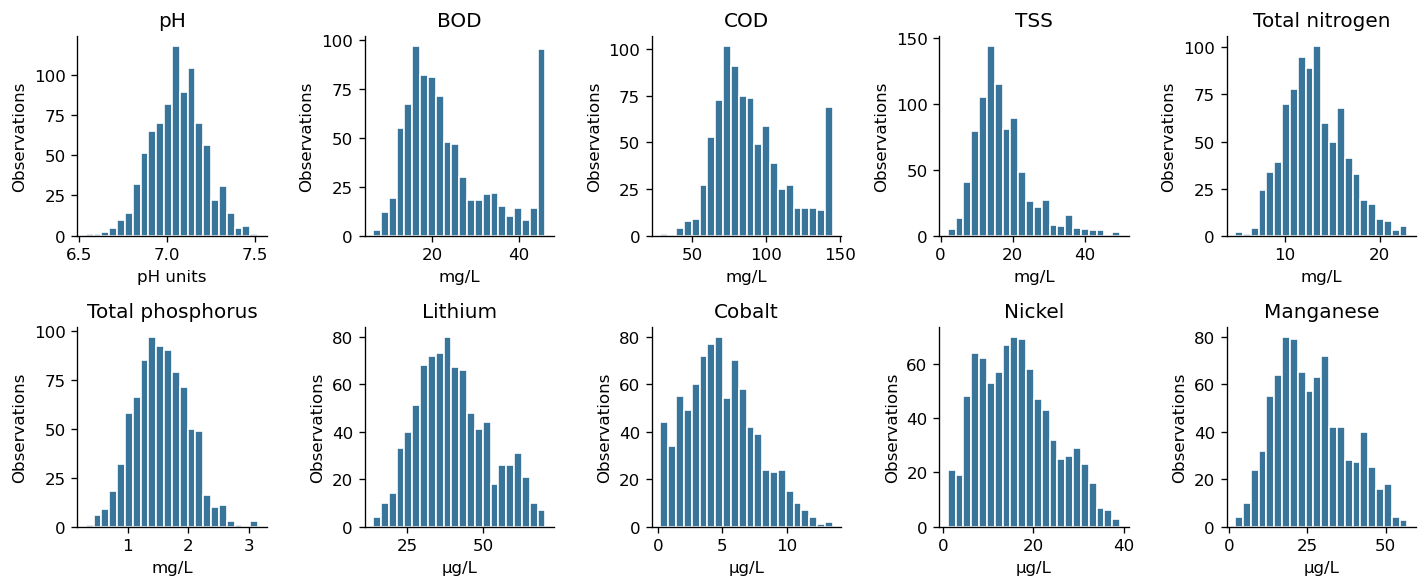

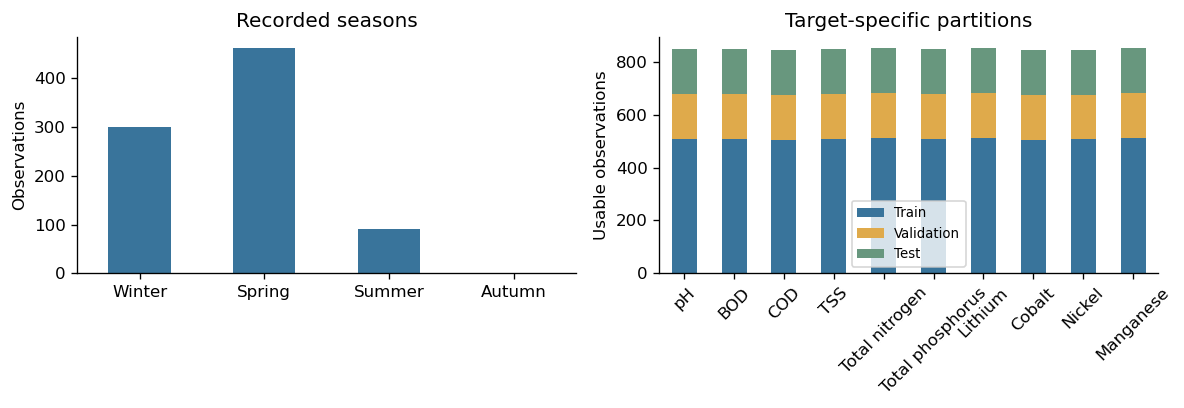

In [1107]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, (label, col, unit) in zip(axes.flat, TARGETS):
    ax.hist(data[col].dropna(), bins=22, color='#39749b', edgecolor='white')
    ax.set(title=label, xlabel=unit, ylabel='Observations')
save_figure(fig, 'figure_01_target_distributions')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
data.season.value_counts().reindex(['Winter', 'Spring', 'Summer', 'Autumn'], fill_value=0).plot.bar(ax=axes[0], color='#39749b', rot=0)
axes[0].set(ylabel='Observations', title='Recorded seasons', xlabel='')
availability.set_index('Target')[['Train','Validation','Test']].plot.bar(stacked=True, ax=axes[1], rot=45,
    color=['#39749b','#dfaa4b','#68977e'])
axes[1].set(ylabel='Usable observations', xlabel='', title='Target-specific partitions')
axes[1].legend(fontsize=8)
save_figure(fig, 'figure_02_coverage_and_splits')

## 3 Define predictors and shared methods

The same 17 predictor columns are used for the primary experiments. Record identifiers and all effluent outcomes are excluded. The seven weather/operation fields remain outside this original specification; exclusion does not demonstrate that they lack predictive value.

In [1108]:
display(pd.DataFrame({'Numeric influent input': NUM}))


,Numeric influent input
0,influent_flow_m3_day
1,influent_temperature_c
2,influent_ph
3,influent_bod_mg_l
4,influent_cod_mg_l
5,influent_tss_mg_l
6,influent_total_nitrogen_mg_l
7,influent_total_phosphorus_mg_l
8,influent_conductivity_us_cm
9,influent_lithium_ug_l


In [1109]:
display(pd.DataFrame({'Categorical context': CAT}))


,Categorical context
0,plant_id
1,wastewater_source
2,treatment_process
3,season


In [1110]:
print('Input count:', len(FEATURES))
print('Training ends:', (VALID_START-pd.Timedelta(days=1)).date())
print('Validation:', VALID_START.date(), 'to', (TEST_START-pd.Timedelta(days=1)).date())
print('Test begins:', TEST_START.date())
assert not any(column.startswith('effluent_') for column in FEATURES)

Input count: 17
Training ends: 2024-04-11
Validation: 2024-04-12 to 2024-05-15
Test begins: 2024-05-16


### 3.1 Shared preprocessing and metric definitions

Numeric predictors use median imputation and standardization. Categorical predictors use mode imputation and one-hot encoding. A fresh pipeline is fitted for each candidate. The metric function is defined once so that BOD, COD, and the remaining targets use exactly the same formulas. MAE is the primary selection metric. R² is not accuracy. The date-block interval helper is used only in the supplementary section.

In [1111]:
def make_pipeline(estimator, features=None):
    """All learned preprocessing belongs inside each independently fitted pipeline."""
    features = FEATURES if features is None else features
    numeric = [c for c in features if c in NUM]
    categorical = [c for c in features if c in CAT]
    transforms = []
    if numeric:
        transforms.append(('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                               ('scaler', StandardScaler())]), numeric))
    if categorical:
        transforms.append(('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
             ('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical))
    return Pipeline([('preprocessing', ColumnTransformer(transforms)), ('model', clone(estimator))])



In [1112]:
def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    assert actual.shape == predicted.shape and len(actual) > 1
    assert np.isfinite(actual).all() and np.isfinite(predicted).all()
    residual = actual - predicted
    centered = actual - actual.mean()
    sad, ssd = np.abs(centered).sum(), np.square(centered).sum()
    mse = mean_squared_error(actual, predicted)
    return {'MAE': mean_absolute_error(actual, predicted), 'MSE': mse, 'RMSE': np.sqrt(mse),
            'R2': r2_score(actual, predicted) if ssd else np.nan,
            'RAE': np.abs(residual).sum()/sad if sad else np.nan,
            'RRSE': np.sqrt(np.square(residual).sum()/ssd) if ssd else np.nan}



In [1113]:
def target_frames(column, gap_days=0):
    """Gap=1 omits the final fitting date before each evaluation boundary."""
    frame = data.loc[data[column].notna()].copy()
    d = frame.observation_date
    train = frame.loc[d < VALID_START - pd.Timedelta(days=gap_days)]
    validation = frame.loc[d.between(VALID_START, TEST_START, inclusive='left')]
    development = frame.loc[d < TEST_START - pd.Timedelta(days=gap_days)]
    test = frame.loc[d >= TEST_START]
    assert train.observation_date.max() < validation.observation_date.min()
    assert development.observation_date.max() < test.observation_date.min()
    assert set(development.index).isdisjoint(test.index)
    return train, validation, development, test


In [1114]:
def date_block_interval(predictions, reference, block=7, repeats=2000):
    """Paired circular moving-date-block bootstrap, retaining plants within dates.

    This describes sampling variability conditional on fixed fitted models.
    It excludes algorithm selection and training uncertainty.
    """
    p = predictions.copy()
    p['difference'] = np.abs(p.actual - p[reference]) - np.abs(p.actual - p.predicted)
    by_date = p.groupby('observation_date')['difference'].agg(['sum','count'])
    sums, counts = by_date['sum'].to_numpy(), by_date['count'].to_numpy()
    n = len(by_date)
    rng = np.random.default_rng(SEED)
    starts = rng.integers(0, n, size=(repeats, int(np.ceil(n/block))))
    indices = ((starts[..., None] + np.arange(block)) % n).reshape(repeats, -1)[:, :n]
    sampled = sums[indices].sum(axis=1) / counts[indices].sum(axis=1)
    return float(p.difference.mean()), *np.quantile(sampled, [.025, .975]).tolist()

### 3.2 Shared comparison and plotting functions

These functions remove repeated implementation, while every target below still has visible step-by-step code and outputs. `compare_candidates` fits each candidate once on training data and caches its training and validation predictions. Plotting functions consume cached results and never refit models. Validation diagnostics and test diagnostics are different outputs, so both are retained.

In [1115]:
def compare_candidates(label, X_train, y_train, X_validation, y_validation):
    fitted, cached, rows = {}, {}, []
    for name, estimator in MODELS.items():
        pipe = make_pipeline(estimator).fit(X_train, y_train)
        fitted[name], cached[name] = pipe, {}
        for split, X_part, y_part in [('Train',X_train,y_train),
                                      ('Validation',X_validation,y_validation)]:
            pred = pipe.predict(X_part)
            cached[name][split] = pred
            rows.append({'Target':label,'Model':name,'Split':split,**metrics(y_part,pred)})
    return {'fitted':fitted,'predictions':cached,'metrics':pd.DataFrame(rows)}



In [1116]:
def plot_comparison(table, label, unit, filename):
    fig,axes=plt.subplots(3,2,figsize=(9.2,9.5))
    for ax, metric in zip(axes.flat,['MAE','MSE','RMSE','R2','RAE','RRSE']):
        values=table.pivot(index='Model',columns='Split',values=metric).reindex(list(MODELS))
        values[['Train','Validation']].plot.barh(ax=ax,color=[TRAIN_COLOR,VALIDATION_COLOR],
                                               width=.8,legend=False)
        ax.set(title=metric,ylabel='',xlabel=unit if metric in ['MAE','RMSE']
               else f'({unit})²' if metric=='MSE' else 'dimensionless')
        ax.tick_params(axis='both',labelsize=11)
        ax.grid(axis='x',alpha=.2)
    axes[0,0].legend(fontsize=8)
    fig.suptitle(f'{label}: training and validation comparison',y=1.02)
    save_figure(fig,filename)



In [1117]:
def error_frame(frame, actual, predicted):
    table=frame[['record_id','observation_date','plant_id']].copy()
    table['actual']=np.asarray(actual)
    table['predicted']=np.asarray(predicted)
    table['residual']=table.actual-table.predicted
    table['absolute_error']=table.residual.abs()
    return table



In [1118]:
def plant_summary(table):
    return table.groupby('plant_id').agg(n=('actual','size'),
        MAE=('absolute_error','mean'),Mean_residual=('residual','mean')).reset_index()



In [1119]:
def plot_diagnostics(table, label, unit, selected, split, filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4))
    for plant,group in table.groupby('plant_id'):
        color=PLANT_COLORS[plant]
        axes[0].scatter(group.actual,group.predicted,s=24,alpha=.7,color=color,label=plant)
        axes[1].scatter(group.predicted,group.residual,s=24,alpha=.7,color=color,label=plant)
    lo=min(table.actual.min(),table.predicted.min())
    hi=max(table.actual.max(),table.predicted.max())
    axes[0].plot([lo,hi],[lo,hi],'--',color='black',lw=1)
    axes[1].axhline(0,ls='--',color='black',lw=1)
    axes[0].set(xlabel=f'Observed ({unit})',ylabel=f'Predicted ({unit})',title='Observed versus predicted')
    axes[1].set(xlabel=f'Predicted ({unit})',ylabel=f'Observed − predicted ({unit})',title='Residuals')
    axes[0].legend(fontsize=8)
    for ax in axes:ax.grid(alpha=.15)
    fig.suptitle(f'{label} — {split} — {selected}')
    save_figure(fig,filename)



In [1120]:
def save_target_results(slug, label, unit, column, comparison, selected, ranking,
                        train, validation, development, test, final, baseline,
                        validation_errors, test_predictions, test_table):
    folder=STEP_OUT/slug
    folder.mkdir(exist_ok=True)
    comparison['metrics'].to_csv(folder/'train_validation_metrics.csv',index=False)
    ranking.to_csv(folder/'validation_ranking.csv',index=False)
    validation_errors.to_csv(folder/'validation_predictions.csv',index=False)
    test_predictions.to_csv(folder/'test_predictions.csv',index=False)
    test_table.to_csv(folder/'test_metrics.csv',index=False)
    plant_summary(test_predictions).to_csv(folder/'test_errors_by_plant.csv',index=False)
    joblib.dump(final,folder/'selected_pipeline.joblib')
    results[label]={'slug':slug,'column':column,'unit':unit,'comparison':comparison,
        'selected':selected,'ranking':ranking,'train':train,'validation':validation,
        'development':development,'test':test,'final':final,'baseline':baseline,
        'validation_errors':validation_errors,'test_predictions':test_predictions,
        'test_metrics':test_table}
    
    print('Saved:',folder.resolve())
    print('Files:',', '.join(sorted(path.name for path in folder.iterdir())))

## 4 BOD prediction

**Target:** `effluent_bod_mg_l`. **Unit:** mg/L. This section contains the complete BOD experiment in the same order as the original notebook. All figures and tables below concern BOD; the test period is reserved until the algorithm is selected.

### 4.1 Prepare the BOD data

**Why this step?** We predict BOD, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1121]:
bod_target = 'effluent_bod_mg_l'
bod_known = data[bod_target].notna()
bod_frame = data.loc[bod_known].copy()
bod_X = bod_frame[FEATURES].copy()
bod_y = bod_frame[bod_target].copy()
bod_dates = bod_frame['observation_date'].copy()
assert bod_X.index.equals(bod_y.index)
print('Missing target rows excluded:', int((~bod_known).sum()))
print('X shape:', bod_X.shape, '| y shape:', bod_y.shape)
display(bod_frame[['record_id','observation_date','plant_id']+NUM[:3]+[bod_target]].head())

Missing target rows excluded: 3
X shape: (847, 17) | y shape: (847,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_bod_mg_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,18.60
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,26.79
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,21.22
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,46.00
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,20.02


### 4.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,508,2024-01-01,2024-04-11
1,Validation,169,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


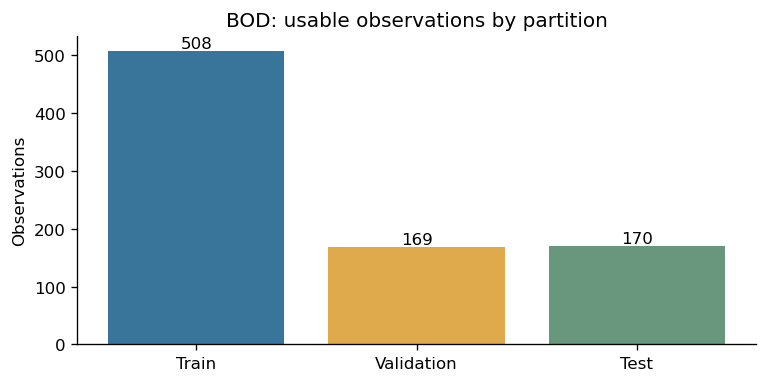

In [1122]:
bod_train_mask = bod_dates < VALID_START
bod_validation_mask = bod_dates.between(VALID_START, TEST_START, inclusive='left')
bod_test_mask = bod_dates >= TEST_START
bod_train = bod_frame.loc[bod_train_mask].copy()
bod_validation = bod_frame.loc[bod_validation_mask].copy()
bod_test = bod_frame.loc[bod_test_mask].copy()

assert len(bod_train)+len(bod_validation)+len(bod_test)==len(bod_frame)
assert bod_train.observation_date.max() < bod_validation.observation_date.min()
assert bod_validation.observation_date.max() < bod_test.observation_date.min()

bod_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',bod_train),('Validation',bod_validation),('Test',bod_test)]])

display(bod_split_summary)
fig,ax=plt.subplots(figsize=(6.5,3.3))

ax.bar(bod_split_summary['Split'], bod_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='BOD: usable observations by partition',ylabel='Observations')

for i,n in enumerate(bod_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
    
save_figure(fig,'bod_split_counts')

### 4.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1123]:
display(bod_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1124]:
bod_comparison = compare_candidates('BOD', bod_train[FEATURES], bod_train[bod_target], bod_validation[FEATURES], bod_validation[bod_target])

display(bod_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,BOD,Mean baseline,Train,8.5697,112.2754,10.5960,0.0000,1.0000,1.0000
1,BOD,Mean baseline,Validation,9.2821,128.7872,11.3484,-0.0032,0.9822,1.0016
2,BOD,Linear Regression,Train,5.1846,47.6536,6.9032,0.5756,0.6050,0.6515
3,BOD,Linear Regression,Validation,6.0365,72.7639,8.5302,0.4332,0.6388,0.7529
4,BOD,Ridge,Train,5.1881,47.6567,6.9034,0.5755,0.6054,0.6515
5,BOD,Ridge,Validation,6.0463,72.8260,8.5338,0.4327,0.6398,0.7532
6,BOD,Lasso,Train,5.2702,48.2029,6.9428,0.5707,0.6150,0.6552
7,BOD,Lasso,Validation,6.1010,71.0913,8.4316,0.4462,0.6456,0.7442
8,BOD,Decision Tree,Train,3.4242,22.9048,4.7859,0.7960,0.3996,0.4517
9,BOD,Decision Tree,Validation,7.5074,100.0251,10.0013,0.2208,0.7944,0.8827


### 4.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

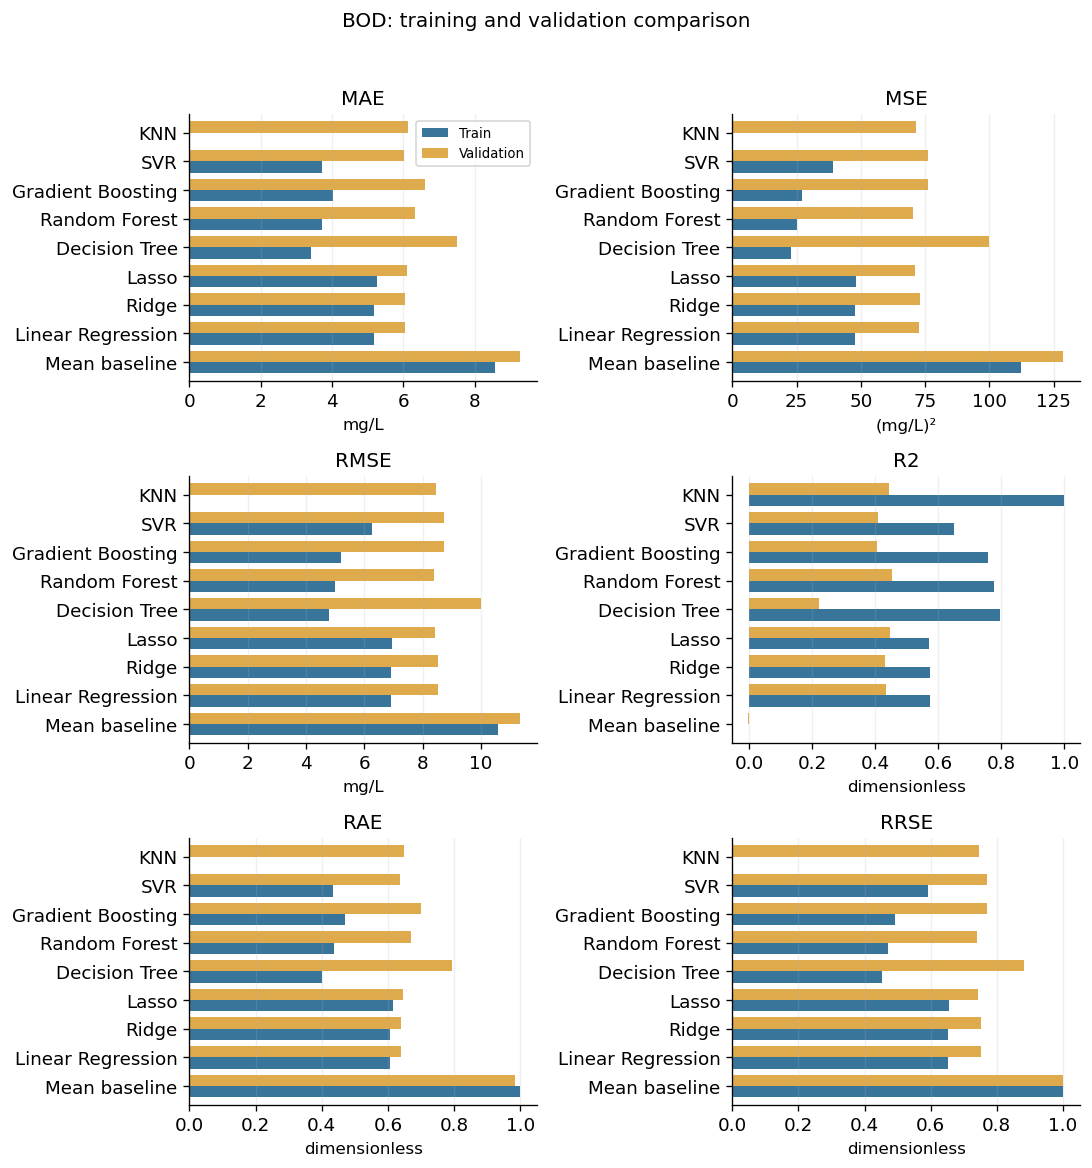

In [1125]:
plot_comparison(bod_comparison['metrics'],'BOD','mg/L','comparison_bod')

### 4.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1126]:
bod_validation_ranking = (bod_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
bod_best_name = bod_validation_ranking.loc[0,'Model']
bod_best_training_pipeline = bod_comparison['fitted'][bod_best_name]
display(bod_validation_ranking[['Model','MAE']].round(4))


print('Selected algorithm:',bod_best_name)
print('Validation MAE gap to runner-up:', float(bod_validation_ranking.loc[1,'MAE']-bod_validation_ranking.loc[0,'MAE']),'mg/L')


bod_mae_gaps=bod_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
bod_mae_gaps['Validation minus train']=bod_mae_gaps.Validation-bod_mae_gaps.Train
display(bod_mae_gaps.round(4))

,Model,MAE
0,SVR,6.0147
1,Linear Regression,6.0365
2,Ridge,6.0463
3,Lasso,6.1010
4,KNN,6.1401
5,Random Forest,6.3256
6,Gradient Boosting,6.6086
7,Decision Tree,7.5074
8,Mean baseline,9.2821


Selected algorithm: SVR
Validation MAE gap to runner-up: 0.02184994306057142 mg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,3.4242,7.5074,4.0831
Gradient Boosting,4.0375,6.6086,2.5711
KNN,0.0000,6.1401,6.1401
Lasso,5.2702,6.1010,0.8308
Linear Regression,5.1846,6.0365,0.8519
Mean baseline,8.5697,9.2821,0.7123
Random Forest,3.7329,6.3256,2.5927
Ridge,5.1881,6.0463,0.8583
SVR,3.7135,6.0147,2.3012


### 4.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,7.84,16.0554,-8.2154,8.2154
511,WQ-0512,2024-04-12,WWTP-02,13.31,17.5899,-4.2799,4.2799
512,WQ-0513,2024-04-12,WWTP-03,20.37,21.6154,-1.2454,1.2454
513,WQ-0514,2024-04-12,WWTP-04,24.39,41.0928,-16.7028,16.7028
514,WQ-0515,2024-04-12,WWTP-05,17.06,14.6610,2.3990,2.3990
515,WQ-0516,2024-04-13,WWTP-01,20.39,19.5935,0.7965,0.7965
516,WQ-0517,2024-04-13,WWTP-02,13.12,17.9701,-4.8501,4.8501
517,WQ-0518,2024-04-13,WWTP-03,16.54,17.5896,-1.0496,1.0496
518,WQ-0519,2024-04-13,WWTP-04,32.41,41.9247,-9.5147,9.5147
519,WQ-0520,2024-04-13,WWTP-05,43.16,23.1345,20.0255,20.0255


,plant_id,n,MAE,Mean_residual
0,WWTP-01,33,3.6340,0.9149
1,WWTP-02,34,9.8153,3.4305
2,WWTP-03,34,3.5291,0.7314
3,WWTP-04,34,7.3327,-0.6933
4,WWTP-05,34,5.6923,3.2678


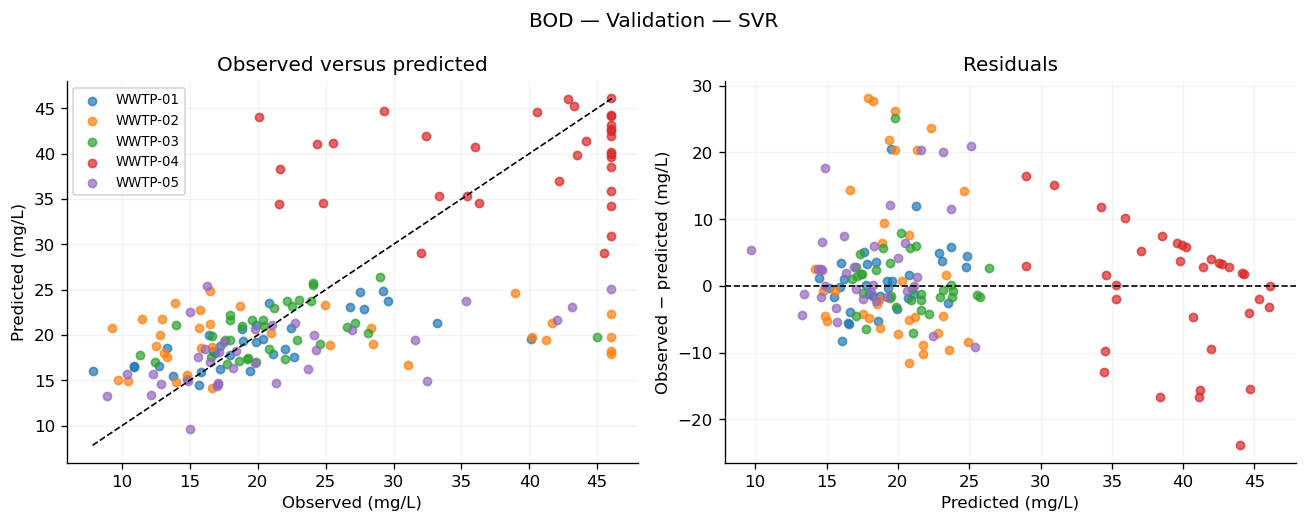

In [1127]:
bod_validation_pred = bod_comparison['predictions'][bod_best_name]['Validation']
bod_validation_errors = error_frame(bod_validation,bod_validation[bod_target],bod_validation_pred)

display(bod_validation_errors.head(10).round(4))

display(plant_summary(bod_validation_errors).round(4))

plot_diagnostics(bod_validation_errors,'BOD','mg/L',bod_best_name,'Validation','bod_validation_diagnostics')

### 4.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1128]:
bod_development = pd.concat([bod_train,bod_validation]).sort_values(['observation_date','plant_id'])

assert set(bod_development.index).isdisjoint(bod_test.index)

assert bod_development.observation_date.max() < bod_test.observation_date.min()

bod_final_pipeline = make_pipeline(MODELS[bod_best_name]).fit(bod_development[FEATURES],bod_development[bod_target])

bod_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(bod_development[FEATURES],bod_development[bod_target])


print('Final selected algorithm:',bod_best_name)

print('Development observations:',len(bod_development),'| test observations:',len(bod_test))

print('Last fitting date:',bod_development.observation_date.max().date())

print('First test date:',bod_test.observation_date.min().date())

Final selected algorithm: SVR
Development observations: 677 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 4.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1129]:
bod_test_pred = bod_final_pipeline.predict(bod_test[FEATURES])
bod_baseline_pred = bod_mean_baseline.predict(bod_test[FEATURES])
bod_test_predictions = error_frame(bod_test,bod_test[bod_target],bod_test_pred)
bod_test_predictions['mean_baseline'] = bod_baseline_pred
bod_test_metrics = pd.DataFrame([
    {'Target':'BOD','Unit':'mg/L','Model':bod_best_name, **metrics(bod_test[bod_target],bod_test_pred)},
    {'Target':'BOD','Unit':'mg/L','Model':'Mean baseline', **metrics(bod_test[bod_target],bod_baseline_pred)}])

bod_mae_reduction = 100*(1-bod_test_metrics.loc[0,'MAE']/bod_test_metrics.loc[1,'MAE'])



In [1130]:
display(bod_test_predictions.head(10).round(4))



,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,30.94,23.4392,7.5008,7.5008,24.4272
681,WQ-0682,2024-05-16,WWTP-02,21.42,19.3017,2.1183,2.1183,24.4272
682,WQ-0683,2024-05-16,WWTP-03,15.47,21.5297,-6.0597,6.0597,24.4272
683,WQ-0684,2024-05-16,WWTP-04,46.00,44.7604,1.2396,1.2396,24.4272
684,WQ-0685,2024-05-16,WWTP-05,18.11,19.7049,-1.5949,1.5949,24.4272
685,WQ-0686,2024-05-17,WWTP-01,21.68,19.8167,1.8633,1.8633,24.4272
686,WQ-0687,2024-05-17,WWTP-02,31.00,23.0762,7.9238,7.9238,24.4272
687,WQ-0688,2024-05-17,WWTP-03,19.46,21.4046,-1.9446,1.9446,24.4272
688,WQ-0689,2024-05-17,WWTP-04,46.00,39.6350,6.3650,6.3650,24.4272
689,WQ-0690,2024-05-17,WWTP-05,16.12,21.9025,-5.7825,5.7825,24.4272


In [1131]:
display(bod_test_metrics.round(4))


,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,BOD,mg/L,SVR,5.6671,61.7933,7.8609,0.3948,0.6888,0.7779
1,BOD,mg/L,Mean baseline,8.2257,102.1054,10.1047,-0.0000,0.9997,1.0000


In [1132]:
print('Test MAE:',round(bod_test_metrics.loc[0,'MAE'],4),'mg/L')
print('MAE reduction relative to the fitted mean:',round(bod_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

Test MAE: 5.6671 mg/L
MAE reduction relative to the fitted mean: 31.1 %
R² describes relative squared error, not percentage accuracy.


In [1133]:
print('Test MAE:',round(bod_test_metrics.loc[0,'MAE'],4),'mg/L')
print('MAE reduction relative to the fitted mean:',round(bod_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

Test MAE: 5.6671 mg/L
MAE reduction relative to the fitted mean: 31.1 %
R² describes relative squared error, not percentage accuracy.


### 4.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

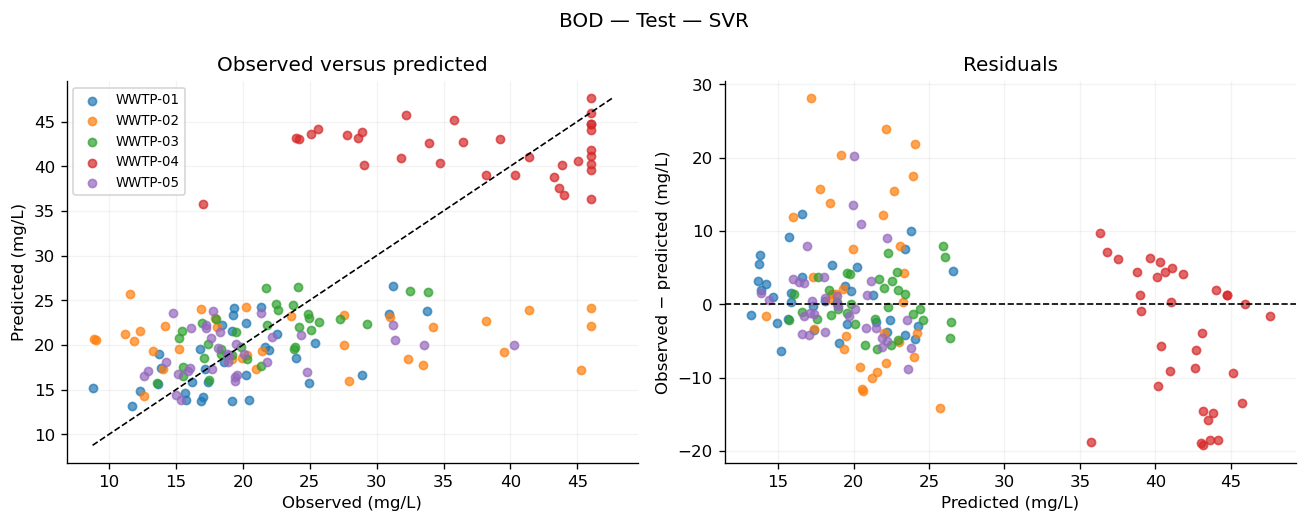

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,3.8577,1.2519
1,WWTP-02,34,9.3802,2.9870
2,WWTP-03,34,2.9484,0.2027
3,WWTP-04,34,8.0027,-4.2971
4,WWTP-05,34,4.1466,0.7811


In [1134]:
plot_diagnostics(bod_test_predictions,'BOD','mg/L',bod_best_name,'Test','bod_test_diagnostics')


display(plant_summary(bod_test_predictions).round(4))

### 4.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved BOD pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1135]:
save_target_results('bod','BOD','mg/L',bod_target,
    bod_comparison,bod_best_name,bod_validation_ranking,
    bod_train,bod_validation,bod_development,bod_test,
    bod_final_pipeline,bod_mean_baseline,bod_validation_errors,
    bod_test_predictions,bod_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/bod
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 5 COD prediction

**Target:** `effluent_cod_mg_l`. **Unit:** mg/L. This section contains the complete COD experiment in the same order as the original notebook. All figures and tables below concern COD; the test period is reserved until the algorithm is selected.

### 5.1 Prepare the COD data

**Why this step?** We predict COD, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1136]:
cod_target = 'effluent_cod_mg_l'
cod_known = data[cod_target].notna()
cod_frame = data.loc[cod_known].copy()
cod_X = cod_frame[FEATURES].copy()
cod_y = cod_frame[cod_target].copy()
cod_dates = cod_frame['observation_date'].copy()


In [1137]:
assert cod_X.index.equals(cod_y.index)
print('Missing target rows excluded:', int((~cod_known).sum()))

print('X shape:', cod_X.shape, '| y shape:', cod_y.shape)

display(cod_frame[['record_id','observation_date','plant_id']+NUM[:3]+[cod_target]].head())

Missing target rows excluded: 6
X shape: (844, 17) | y shape: (844,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_cod_mg_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,60.71
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,92.25
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,64.43
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,145.00
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,82.23


### 5.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,505,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,169,2024-05-16,2024-06-18


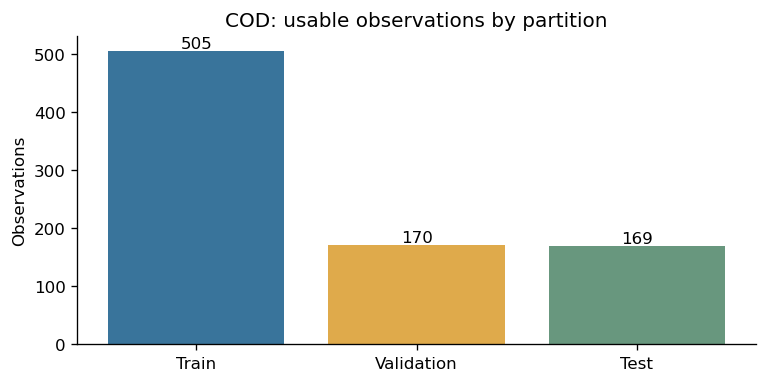

In [1138]:
cod_train_mask = cod_dates < VALID_START
cod_validation_mask = cod_dates.between(VALID_START, TEST_START, inclusive='left')
cod_test_mask = cod_dates >= TEST_START
cod_train = cod_frame.loc[cod_train_mask].copy()
cod_validation = cod_frame.loc[cod_validation_mask].copy()
cod_test = cod_frame.loc[cod_test_mask].copy()

assert len(cod_train)+len(cod_validation)+len(cod_test)==len(cod_frame)
assert cod_train.observation_date.max() < cod_validation.observation_date.min()
assert cod_validation.observation_date.max() < cod_test.observation_date.min()

cod_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',cod_train),('Validation',cod_validation),('Test',cod_test)]])

display(cod_split_summary)

fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(cod_split_summary['Split'], cod_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='COD: usable observations by partition',ylabel='Observations')
for i,n in enumerate(cod_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'cod_split_counts')

### 5.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1139]:
display(cod_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,0
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1140]:
cod_comparison = compare_candidates('COD',
    cod_train[FEATURES], cod_train[cod_target],
    cod_validation[FEATURES], cod_validation[cod_target])
display(cod_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,COD,Mean baseline,Train,20.1908,642.7550,25.3526,0.0000,1.0000,1.0000
1,COD,Mean baseline,Validation,21.1161,680.8365,26.0928,-0.0019,0.9907,1.0010
2,COD,Linear Regression,Train,9.7401,173.5424,13.1735,0.7300,0.4824,0.5196
3,COD,Linear Regression,Validation,10.9075,220.3093,14.8428,0.6758,0.5117,0.5694
4,COD,Ridge,Train,9.7450,173.5636,13.1744,0.7300,0.4826,0.5196
5,COD,Ridge,Validation,10.9199,220.8562,14.8612,0.6750,0.5123,0.5701
6,COD,Lasso,Train,9.7881,174.1333,13.1960,0.7291,0.4848,0.5205
7,COD,Lasso,Validation,10.9222,220.6739,14.8551,0.6753,0.5124,0.5699
8,COD,Decision Tree,Train,6.3375,77.8394,8.8227,0.8789,0.3139,0.3480
9,COD,Decision Tree,Validation,12.0133,270.2073,16.4380,0.6024,0.5636,0.6306


### 5.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

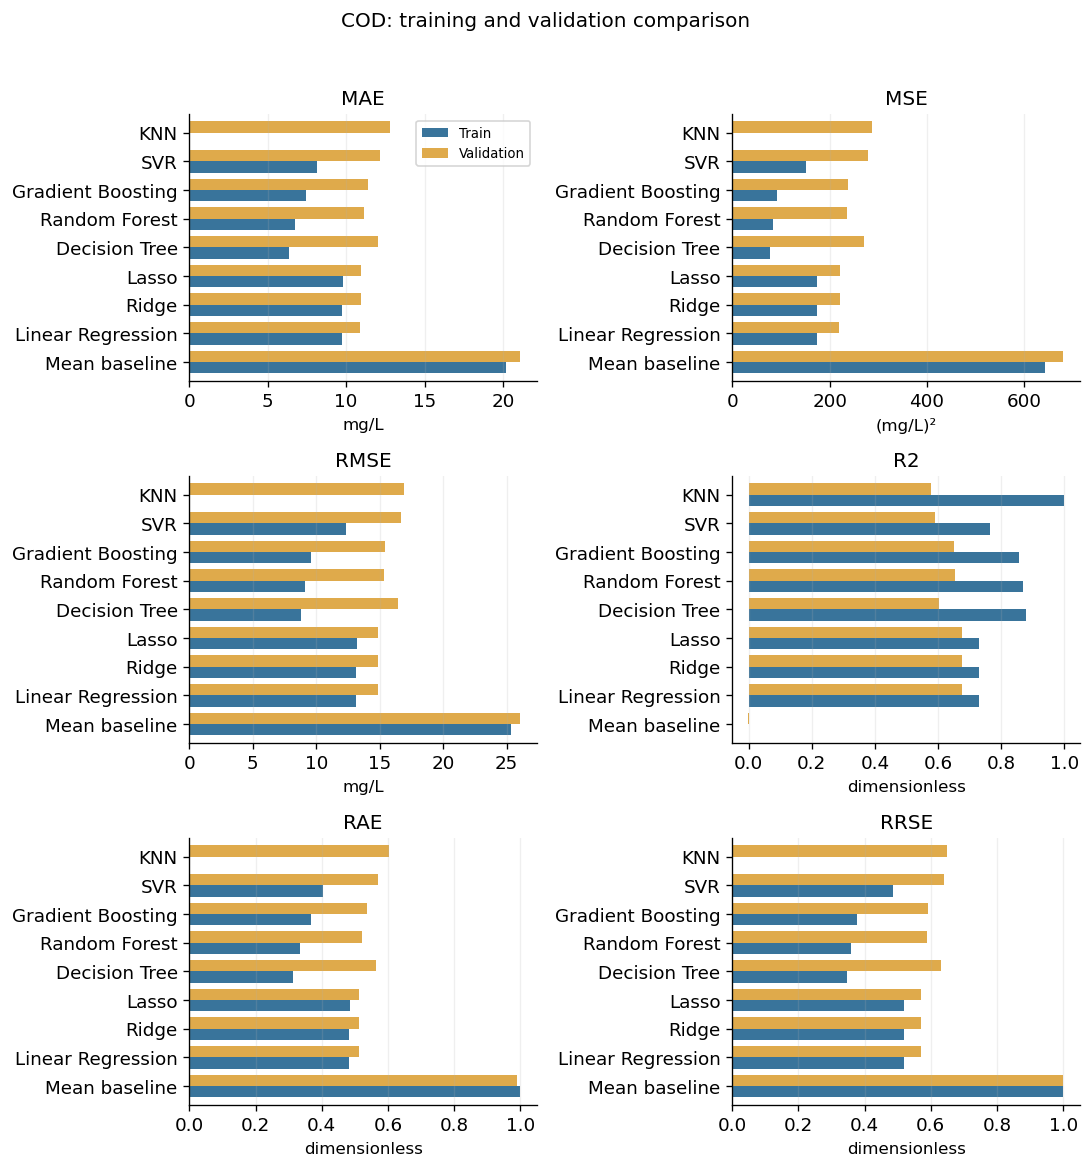

In [1141]:
plot_comparison(cod_comparison['metrics'],'COD','mg/L','comparison_cod')

### 5.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1142]:
cod_validation_ranking = (cod_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
cod_best_name = cod_validation_ranking.loc[0,'Model']
cod_best_training_pipeline = cod_comparison['fitted'][cod_best_name]
display(cod_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Linear Regression,10.9075
1,Ridge,10.9199
2,Lasso,10.9222
3,Random Forest,11.1283
4,Gradient Boosting,11.4194
5,Decision Tree,12.0133
6,SVR,12.1289
7,KNN,12.8223
8,Mean baseline,21.1161


In [1143]:
print('Selected algorithm:',cod_best_name)
print('Validation MAE gap to runner-up:',
      float(cod_validation_ranking.loc[1,'MAE']-cod_validation_ranking.loc[0,'MAE']),'mg/L')


cod_mae_gaps=cod_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
cod_mae_gaps['Validation minus train']=cod_mae_gaps.Validation-cod_mae_gaps.Train

display(cod_mae_gaps.round(4))

Selected algorithm: Linear Regression
Validation MAE gap to runner-up: 0.012401062461268708 mg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,6.3375,12.0133,5.6757
Gradient Boosting,7.4343,11.4194,3.9851
KNN,0.0000,12.8223,12.8223
Lasso,9.7881,10.9222,1.1341
Linear Regression,9.7401,10.9075,1.1674
Mean baseline,20.1908,21.1161,0.9253
Random Forest,6.7645,11.1283,4.3638
Ridge,9.7450,10.9199,1.1749
SVR,8.1601,12.1289,3.9688


### 5.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1144]:
cod_validation_pred = cod_comparison['predictions'][cod_best_name]['Validation']
cod_validation_errors = error_frame(cod_validation,cod_validation[cod_target],cod_validation_pred)
display(cod_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,46.77,58.6939,-11.9239,11.9239
511,WQ-0512,2024-04-12,WWTP-02,64.10,76.2392,-12.1392,12.1392
512,WQ-0513,2024-04-12,WWTP-03,88.69,84.7336,3.9564,3.9564
513,WQ-0514,2024-04-12,WWTP-04,83.46,107.1673,-23.7073,23.7073
514,WQ-0515,2024-04-12,WWTP-05,87.78,86.5051,1.2749,1.2749
515,WQ-0516,2024-04-13,WWTP-01,71.78,69.9641,1.8159,1.8159
516,WQ-0517,2024-04-13,WWTP-02,71.86,91.5722,-19.7122,19.7122
517,WQ-0518,2024-04-13,WWTP-03,82.50,79.3580,3.1420,3.1420
518,WQ-0519,2024-04-13,WWTP-04,132.73,140.3799,-7.6499,7.6499
519,WQ-0520,2024-04-13,WWTP-05,121.83,90.5261,31.3039,31.3039


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,6.3292,-0.4036
1,WWTP-02,34,17.3158,4.2003
2,WWTP-03,34,7.4507,1.4284
3,WWTP-04,34,14.1558,0.1648
4,WWTP-05,34,9.2861,3.0733


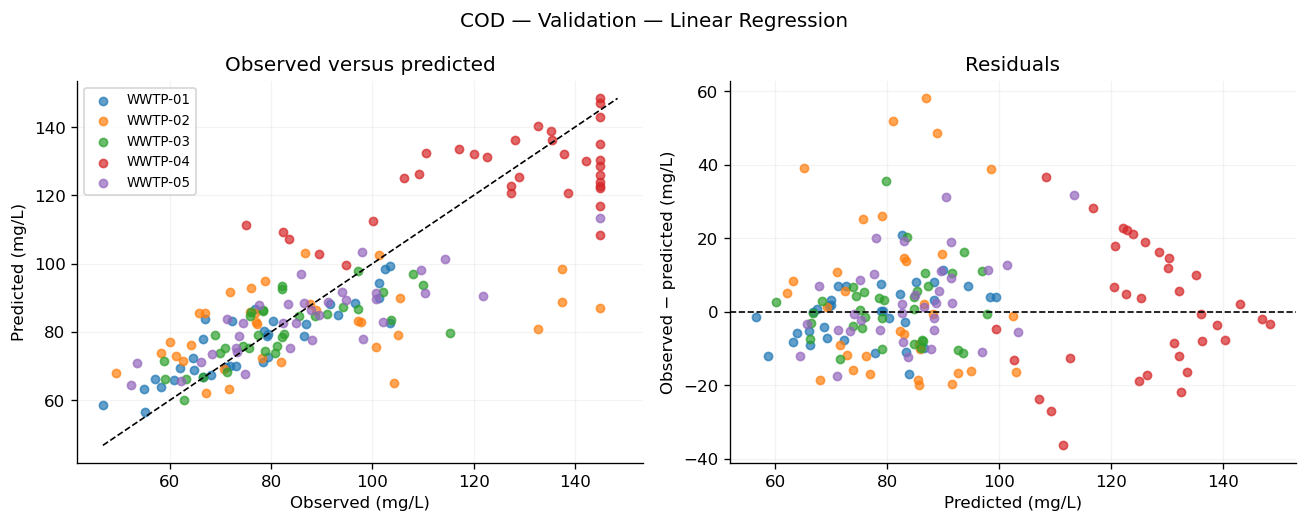

In [1145]:
display(plant_summary(cod_validation_errors).round(4))
plot_diagnostics(cod_validation_errors,'COD','mg/L',cod_best_name,
                 'Validation','cod_validation_diagnostics')

### 5.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1146]:
cod_development = pd.concat([cod_train,cod_validation]).sort_values(['observation_date','plant_id'])

assert set(cod_development.index).isdisjoint(cod_test.index)

assert cod_development.observation_date.max() < cod_test.observation_date.min()

cod_final_pipeline = make_pipeline(MODELS[cod_best_name]).fit(
    cod_development[FEATURES],cod_development[cod_target])

cod_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    cod_development[FEATURES],cod_development[cod_target])

print('Final selected algorithm:',cod_best_name)

print('Development observations:',len(cod_development),'| test observations:',len(cod_test))

print('Last fitting date:',cod_development.observation_date.max().date())

print('First test date:',cod_test.observation_date.min().date())

Final selected algorithm: Linear Regression
Development observations: 675 | test observations: 169
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 5.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1147]:
cod_test_pred = cod_final_pipeline.predict(cod_test[FEATURES])

cod_baseline_pred = cod_mean_baseline.predict(cod_test[FEATURES])

cod_test_predictions = error_frame(cod_test,cod_test[cod_target],cod_test_pred)

cod_test_predictions['mean_baseline'] = cod_baseline_pred

cod_test_metrics = pd.DataFrame([
    {'Target':'COD','Unit':'mg/L','Model':cod_best_name,
      **metrics(cod_test[cod_target],cod_test_pred)},
    {'Target':'COD','Unit':'mg/L','Model':'Mean baseline',
      **metrics(cod_test[cod_target],cod_baseline_pred)}])

cod_mae_reduction = 100*(1-cod_test_metrics.loc[0,'MAE']/cod_test_metrics.loc[1,'MAE'])

display(cod_test_predictions.head(10).round(4))



,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,95.05,87.6647,7.3853,7.3853,90.722
681,WQ-0682,2024-05-16,WWTP-02,71.84,88.5710,-16.7310,16.7310,90.722
682,WQ-0683,2024-05-16,WWTP-03,79.59,81.9212,-2.3312,2.3312,90.722
683,WQ-0684,2024-05-16,WWTP-04,145.00,137.2702,7.7298,7.7298,90.722
684,WQ-0685,2024-05-16,WWTP-05,82.65,92.4916,-9.8416,9.8416,90.722
685,WQ-0686,2024-05-17,WWTP-01,67.77,76.9408,-9.1708,9.1708,90.722
686,WQ-0687,2024-05-17,WWTP-02,105.23,89.1208,16.1092,16.1092,90.722
687,WQ-0688,2024-05-17,WWTP-03,67.50,77.1645,-9.6645,9.6645,90.722
688,WQ-0689,2024-05-17,WWTP-04,145.00,138.8425,6.1575,6.1575,90.722
689,WQ-0690,2024-05-17,WWTP-05,77.36,87.0522,-9.6922,9.6922,90.722


In [1148]:
display(cod_test_metrics.round(4))

print('Test MAE:',round(cod_test_metrics.loc[0,'MAE'],4),'mg/L')

print('MAE reduction relative to the fitted mean:',round(cod_mae_reduction,2),'%')

print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,COD,mg/L,Linear Regression,10.1650,171.2757,13.0872,0.6711,0.5543,0.5735
1,COD,mg/L,Mean baseline,18.3274,520.8062,22.8212,-0.0000,0.9993,1.0000


Test MAE: 10.165 mg/L
MAE reduction relative to the fitted mean: 44.54 %
R² describes relative squared error, not percentage accuracy.


### 5.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

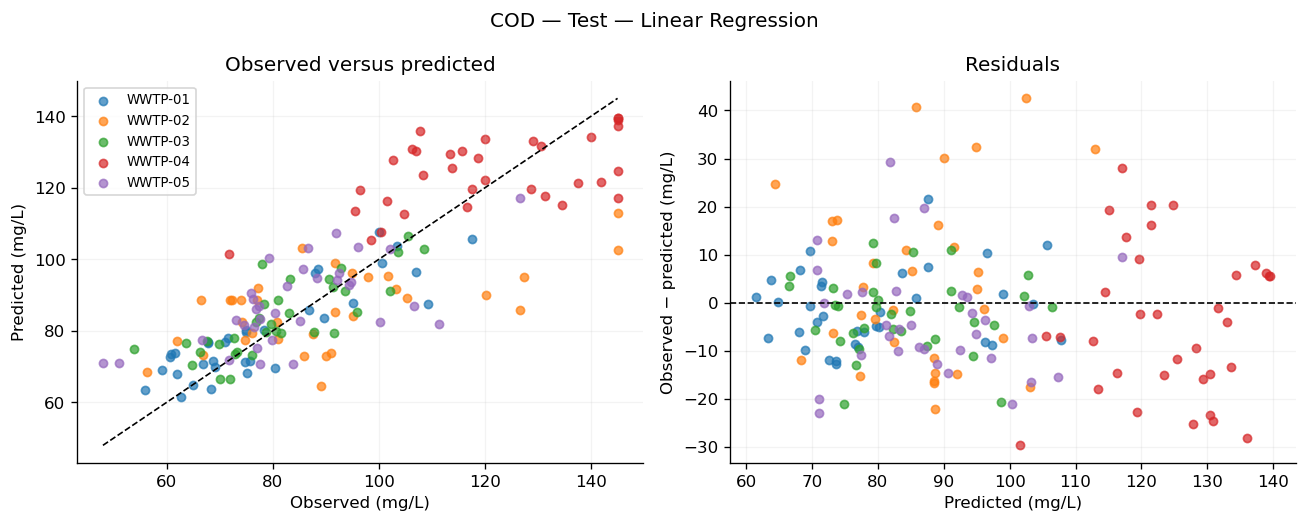

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,6.6553,-1.2706
1,WWTP-02,33,14.7700,4.3507
2,WWTP-03,34,6.2603,-2.3557
3,WWTP-04,34,13.4922,-4.1091
4,WWTP-05,34,9.7827,-3.5997


In [1149]:
plot_diagnostics(cod_test_predictions,'COD','mg/L',cod_best_name, 'Test','cod_test_diagnostics')
display(plant_summary(cod_test_predictions).round(4))

### 5.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved COD pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1150]:
save_target_results('cod','COD','mg/L',cod_target,
    cod_comparison,cod_best_name,cod_validation_ranking,
    cod_train,cod_validation,cod_development,cod_test,
    cod_final_pipeline,cod_mean_baseline,cod_validation_errors,
    cod_test_predictions,cod_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/cod
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 6 TSS prediction

**Target:** `effluent_tss_mg_l`. **Unit:** mg/L. This section contains the complete TSS experiment in the same order as the original notebook. All figures and tables below concern TSS; the test period is reserved until the algorithm is selected.

### 6.1 Prepare the TSS data

**Why this step?** We predict TSS, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1151]:
tss_target = 'effluent_tss_mg_l'
tss_known = data[tss_target].notna()
tss_frame = data.loc[tss_known].copy()
tss_X = tss_frame[FEATURES].copy()
tss_y = tss_frame[tss_target].copy()
tss_dates = tss_frame['observation_date'].copy()
assert tss_X.index.equals(tss_y.index)

print('Missing target rows excluded:', int((~tss_known).sum()))

print('X shape:', tss_X.shape, '| y shape:', tss_y.shape)

display(tss_frame[['record_id','observation_date','plant_id']+NUM[:3]+[tss_target]].head())

Missing target rows excluded: 2
X shape: (848, 17) | y shape: (848,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_tss_mg_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,14.13
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,15.38
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,14.33
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,29.55
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,13.25


### 6.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,509,2024-01-01,2024-04-11
1,Validation,169,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


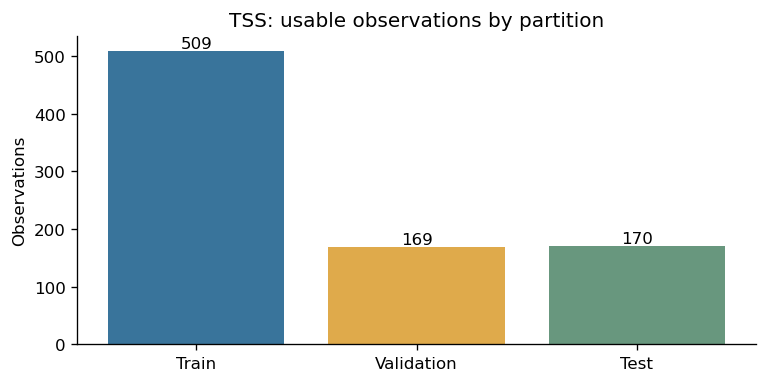

In [1152]:
tss_train_mask = tss_dates < VALID_START
tss_validation_mask = tss_dates.between(VALID_START, TEST_START, inclusive='left')
tss_test_mask = tss_dates >= TEST_START
tss_train = tss_frame.loc[tss_train_mask].copy()
tss_validation = tss_frame.loc[tss_validation_mask].copy()
tss_test = tss_frame.loc[tss_test_mask].copy()
assert len(tss_train)+len(tss_validation)+len(tss_test)==len(tss_frame)
assert tss_train.observation_date.max() < tss_validation.observation_date.min()
assert tss_validation.observation_date.max() < tss_test.observation_date.min()
tss_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',tss_train),('Validation',tss_validation),('Test',tss_test)]])
display(tss_split_summary)
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(tss_split_summary['Split'], tss_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='TSS: usable observations by partition',ylabel='Observations')
for i,n in enumerate(tss_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'tss_split_counts')

### 6.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1153]:
display(tss_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1154]:
tss_comparison = compare_candidates('TSS',
    tss_train[FEATURES], tss_train[tss_target],
    tss_validation[FEATURES], tss_validation[tss_target])
display(tss_comparison['metrics'].round(4))




,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,TSS,Mean baseline,Train,5.7409,59.6769,7.7251,0.0000,1.0000,1.0000
1,TSS,Mean baseline,Validation,5.8908,63.1238,7.9451,-0.0005,1.0076,1.0002
2,TSS,Linear Regression,Train,3.7847,25.0204,5.0020,0.5807,0.6593,0.6475
3,TSS,Linear Regression,Validation,4.3130,32.8370,5.7304,0.4795,0.7377,0.7214
4,TSS,Ridge,Train,3.7842,25.0215,5.0021,0.5807,0.6592,0.6475
5,TSS,Ridge,Validation,4.3122,32.8679,5.7331,0.4791,0.7376,0.7218
6,TSS,Lasso,Train,3.8110,25.4729,5.0471,0.5732,0.6638,0.6533
7,TSS,Lasso,Validation,4.2059,32.0774,5.6637,0.4916,0.7194,0.7130
8,TSS,Decision Tree,Train,2.4147,10.7275,3.2753,0.8202,0.4206,0.4240
9,TSS,Decision Tree,Validation,5.4517,52.2329,7.2272,0.1721,0.9325,0.9099


In [1155]:
tss_mae_gaps=tss_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
tss_mae_gaps['Validation minus train']=tss_mae_gaps.Validation-tss_mae_gaps.Train
display(tss_mae_gaps.round(4))

Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,2.4147,5.4517,3.0370
Gradient Boosting,2.8912,4.2541,1.3629
KNN,0.0000,4.5816,4.5816
Lasso,3.8110,4.2059,0.3949
Linear Regression,3.7847,4.3130,0.5283
Mean baseline,5.7409,5.8908,0.1500
Random Forest,2.5814,4.3616,1.7802
Ridge,3.7842,4.3122,0.5280
SVR,2.5293,4.3760,1.8467


### 6.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

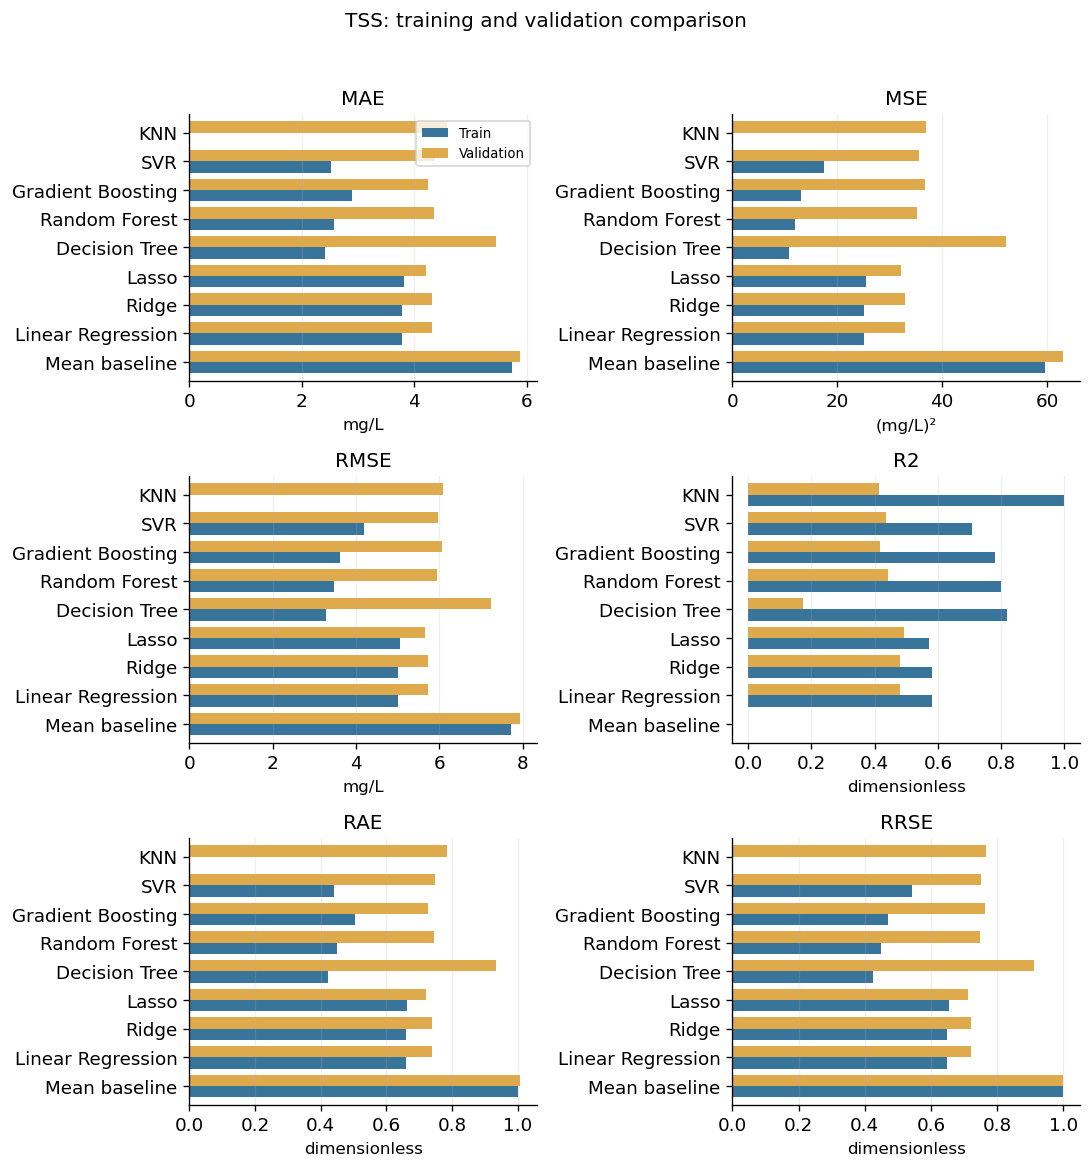

In [1156]:
plot_comparison(tss_comparison['metrics'],'TSS','mg/L','comparison_tss')

### 6.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1157]:
tss_validation_ranking = (tss_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
tss_best_name = tss_validation_ranking.loc[0,'Model']
tss_best_training_pipeline = tss_comparison['fitted'][tss_best_name]
display(tss_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Lasso,4.2059
1,Gradient Boosting,4.2541
2,Ridge,4.3122
3,Linear Regression,4.3130
4,Random Forest,4.3616
5,SVR,4.3760
6,KNN,4.5816
7,Decision Tree,5.4517
8,Mean baseline,5.8908


In [1158]:
print('Selected algorithm:',tss_best_name)
print('Validation MAE gap to runner-up:',
      float(tss_validation_ranking.loc[1,'MAE']-tss_validation_ranking.loc[0,'MAE']),'mg/L')


Selected algorithm: Lasso
Validation MAE gap to runner-up: 0.04819859886749445 mg/L


### 6.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1159]:
tss_validation_pred = tss_comparison['predictions'][tss_best_name]['Validation']
tss_validation_errors = error_frame(tss_validation,tss_validation[tss_target],tss_validation_pred)
display(tss_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,17.95,19.0176,-1.0676,1.0676
511,WQ-0512,2024-04-12,WWTP-02,17.32,15.2789,2.0411,2.0411
512,WQ-0513,2024-04-12,WWTP-03,10.16,12.5265,-2.3665,2.3665
513,WQ-0514,2024-04-12,WWTP-04,14.84,21.1141,-6.2741,6.2741
514,WQ-0515,2024-04-12,WWTP-05,13.00,10.0873,2.9127,2.9127
515,WQ-0516,2024-04-13,WWTP-01,12.59,15.7486,-3.1586,3.1586
516,WQ-0517,2024-04-13,WWTP-02,10.38,14.2404,-3.8604,3.8604
517,WQ-0518,2024-04-13,WWTP-03,7.68,13.3670,-5.6870,5.6870
518,WQ-0519,2024-04-13,WWTP-04,20.70,25.5421,-4.8421,4.8421
519,WQ-0520,2024-04-13,WWTP-05,21.81,16.4584,5.3516,5.3516


,plant_id,n,MAE,Mean_residual
0,WWTP-01,33,3.5185,-0.9747
1,WWTP-02,34,5.2665,1.0880
2,WWTP-03,34,2.7732,-0.2694
3,WWTP-04,34,5.7035,-0.5604
4,WWTP-05,34,3.7476,0.0240


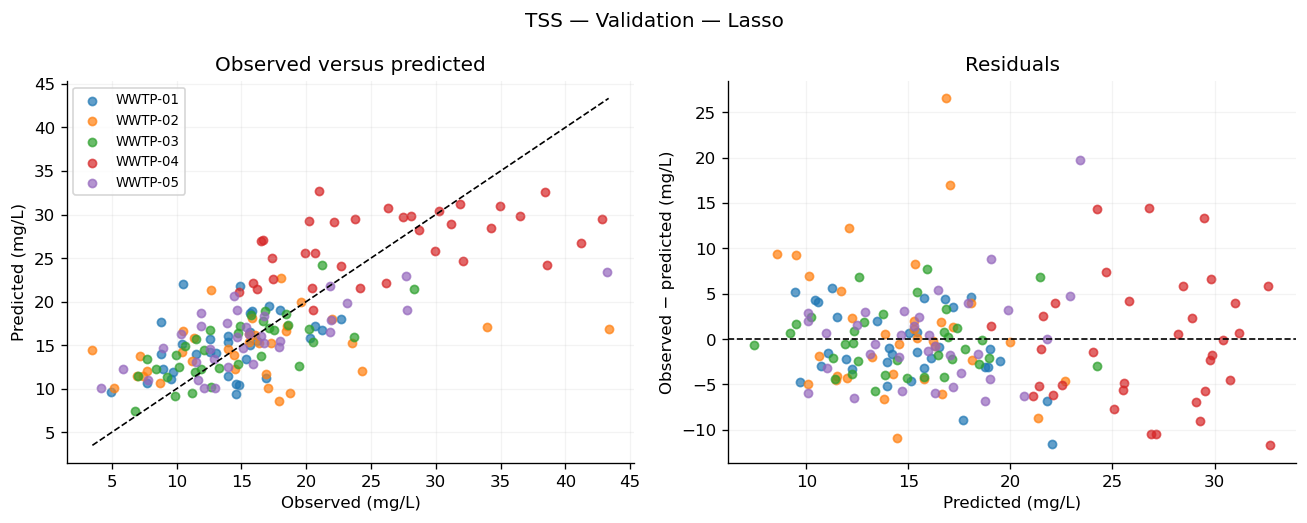

In [1160]:
display(plant_summary(tss_validation_errors).round(4))
plot_diagnostics(tss_validation_errors,'TSS','mg/L',tss_best_name,
                 'Validation','tss_validation_diagnostics')

### 6.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1161]:
tss_development = pd.concat([tss_train,tss_validation]).sort_values(['observation_date','plant_id'])

assert set(tss_development.index).isdisjoint(tss_test.index)

assert tss_development.observation_date.max() < tss_test.observation_date.min()

tss_final_pipeline = make_pipeline(MODELS[tss_best_name]).fit(
    tss_development[FEATURES],tss_development[tss_target])

tss_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    tss_development[FEATURES],tss_development[tss_target])

print('Final selected algorithm:',tss_best_name)

print('Development observations:',len(tss_development),'| test observations:',len(tss_test))

print('Last fitting date:',tss_development.observation_date.max().date())

print('First test date:',tss_test.observation_date.min().date())

Final selected algorithm: Lasso
Development observations: 678 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 6.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1162]:
tss_test_pred = tss_final_pipeline.predict(tss_test[FEATURES])
tss_baseline_pred = tss_mean_baseline.predict(tss_test[FEATURES])
tss_test_predictions = error_frame(tss_test,tss_test[tss_target],tss_test_pred)
tss_test_predictions['mean_baseline'] = tss_baseline_pred
tss_test_metrics = pd.DataFrame([
    {'Target':'TSS','Unit':'mg/L','Model':tss_best_name,
      **metrics(tss_test[tss_target],tss_test_pred)},
    {'Target':'TSS','Unit':'mg/L','Model':'Mean baseline',
      **metrics(tss_test[tss_target],tss_baseline_pred)}])
tss_mae_reduction = 100*(1-tss_test_metrics.loc[0,'MAE']/tss_test_metrics.loc[1,'MAE'])
display(tss_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,19.66,18.6006,1.0594,1.0594,17.3971
681,WQ-0682,2024-05-16,WWTP-02,18.07,16.9545,1.1155,1.1155,17.3971
682,WQ-0683,2024-05-16,WWTP-03,14.76,18.3837,-3.6237,3.6237,17.3971
683,WQ-0684,2024-05-16,WWTP-04,23.01,27.3424,-4.3324,4.3324,17.3971
684,WQ-0685,2024-05-16,WWTP-05,12.93,17.5413,-4.6113,4.6113,17.3971
685,WQ-0686,2024-05-17,WWTP-01,14.44,15.7593,-1.3193,1.3193,17.3971
686,WQ-0687,2024-05-17,WWTP-02,10.13,11.6999,-1.5699,1.5699,17.3971
687,WQ-0688,2024-05-17,WWTP-03,3.88,8.7856,-4.9056,4.9056,17.3971
688,WQ-0689,2024-05-17,WWTP-04,19.67,20.8913,-1.2213,1.2213,17.3971
689,WQ-0690,2024-05-17,WWTP-05,7.62,12.0205,-4.4005,4.4005,17.3971


In [1163]:
display(tss_test_metrics.round(4))


print('Test MAE:',round(tss_test_metrics.loc[0,'MAE'],4),'mg/L')

print('MAE reduction relative to the fitted mean:',round(tss_mae_reduction,2),'%')

print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,TSS,mg/L,Lasso,3.9190,24.5139,4.9512,0.4459,0.7453,0.7443
1,TSS,mg/L,Mean baseline,5.3245,44.4862,6.6698,-0.0055,1.0127,1.0027


Test MAE: 3.919 mg/L
MAE reduction relative to the fitted mean: 26.4 %
R² describes relative squared error, not percentage accuracy.


### 6.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

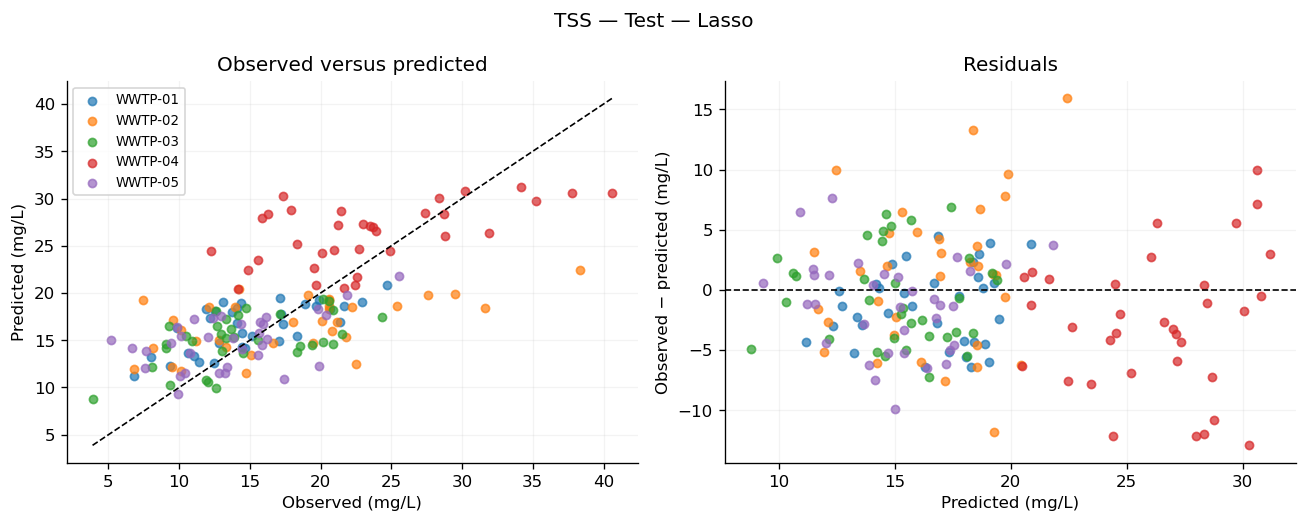

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,2.8371,-1.3387
1,WWTP-02,34,5.0256,1.1583
2,WWTP-03,34,3.4339,-0.5382
3,WWTP-04,34,5.0459,-2.7856
4,WWTP-05,34,3.2524,-1.2517


In [1164]:
plot_diagnostics(tss_test_predictions,'TSS','mg/L',tss_best_name,
                 'Test','tss_test_diagnostics')
display(plant_summary(tss_test_predictions).round(4))

### 6.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved TSS pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1165]:
save_target_results('tss','TSS','mg/L',tss_target,
    tss_comparison,tss_best_name,tss_validation_ranking,
    tss_train,tss_validation,tss_development,tss_test,
    tss_final_pipeline,tss_mean_baseline,tss_validation_errors,
    tss_test_predictions,tss_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/tss
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 7 Total nitrogen prediction

**Target:** `effluent_total_nitrogen_mg_l`. **Unit:** mg/L. This section contains the complete Total nitrogen experiment in the same order as the original notebook. All figures and tables below concern Total nitrogen; the test period is reserved until the algorithm is selected.

### 7.1 Prepare the Total nitrogen data

**Why this step?** We predict Total nitrogen, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1166]:
tn_target = 'effluent_total_nitrogen_mg_l'
tn_known = data[tn_target].notna()
tn_frame = data.loc[tn_known].copy()
tn_X = tn_frame[FEATURES].copy()
tn_y = tn_frame[tn_target].copy()
tn_dates = tn_frame['observation_date'].copy()

assert tn_X.index.equals(tn_y.index)

print('Missing target rows excluded:', int((~tn_known).sum()))

print('X shape:', tn_X.shape, '| y shape:', tn_y.shape)

display(tn_frame[['record_id','observation_date','plant_id']+NUM[:3]+[tn_target]].head())

Missing target rows excluded: 0
X shape: (850, 17) | y shape: (850,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_total_nitrogen_mg_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,16.04
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,15.91
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,10.96
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,17.94
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,14.94


### 7.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,510,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


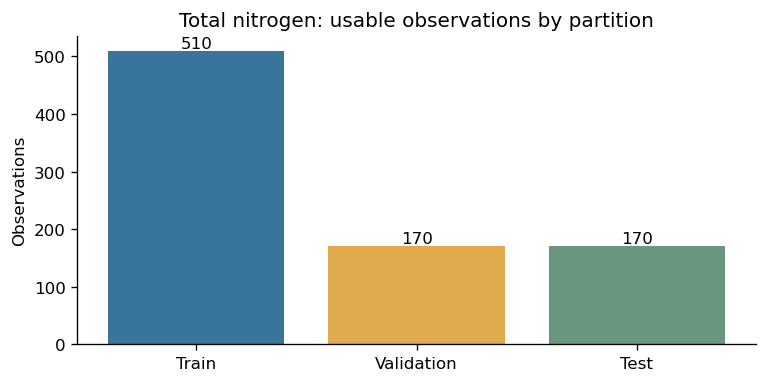

In [1167]:
tn_train_mask = tn_dates < VALID_START
tn_validation_mask = tn_dates.between(VALID_START, TEST_START, inclusive='left')
tn_test_mask = tn_dates >= TEST_START
tn_train = tn_frame.loc[tn_train_mask].copy()
tn_validation = tn_frame.loc[tn_validation_mask].copy()
tn_test = tn_frame.loc[tn_test_mask].copy()

assert len(tn_train)+len(tn_validation)+len(tn_test)==len(tn_frame)
assert tn_train.observation_date.max() < tn_validation.observation_date.min()
assert tn_validation.observation_date.max() < tn_test.observation_date.min()

tn_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    
    for name,frame in [('Train',tn_train),('Validation',tn_validation),('Test',tn_test)]])

display(tn_split_summary)

fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(tn_split_summary['Split'], tn_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Total nitrogen: usable observations by partition',ylabel='Observations')
for i,n in enumerate(tn_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'tn_split_counts')

### 7.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1168]:
display(tn_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1169]:
tn_comparison = compare_candidates('Total nitrogen',
    tn_train[FEATURES], tn_train[tn_target],
    tn_validation[FEATURES], tn_validation[tn_target])
display(tn_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Total nitrogen,Mean baseline,Train,2.4844,9.9494,3.1543,0.0000,1.0000,1.0000
1,Total nitrogen,Mean baseline,Validation,2.4830,9.6056,3.0993,-0.0268,1.0099,1.0133
2,Total nitrogen,Linear Regression,Train,1.3540,2.8971,1.7021,0.7088,0.5450,0.5396
3,Total nitrogen,Linear Regression,Validation,1.4606,3.4590,1.8599,0.6303,0.5941,0.6081
4,Total nitrogen,Ridge,Train,1.3533,2.8972,1.7021,0.7088,0.5447,0.5396
5,Total nitrogen,Ridge,Validation,1.4614,3.4607,1.8603,0.6301,0.5944,0.6082
6,Total nitrogen,Lasso,Train,1.3841,3.0621,1.7499,0.6922,0.5571,0.5548
7,Total nitrogen,Lasso,Validation,1.4931,3.6214,1.9030,0.6129,0.6073,0.6222
8,Total nitrogen,Decision Tree,Train,0.8423,1.1319,1.0639,0.8862,0.3390,0.3373
9,Total nitrogen,Decision Tree,Validation,1.7382,4.8536,2.2031,0.4812,0.7070,0.7203


In [1170]:
tn_comparison = compare_candidates('Total nitrogen',
    tn_train[FEATURES], tn_train[tn_target],
    tn_validation[FEATURES], tn_validation[tn_target])
display(tn_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Total nitrogen,Mean baseline,Train,2.4844,9.9494,3.1543,0.0000,1.0000,1.0000
1,Total nitrogen,Mean baseline,Validation,2.4830,9.6056,3.0993,-0.0268,1.0099,1.0133
2,Total nitrogen,Linear Regression,Train,1.3540,2.8971,1.7021,0.7088,0.5450,0.5396
3,Total nitrogen,Linear Regression,Validation,1.4606,3.4590,1.8599,0.6303,0.5941,0.6081
4,Total nitrogen,Ridge,Train,1.3533,2.8972,1.7021,0.7088,0.5447,0.5396
5,Total nitrogen,Ridge,Validation,1.4614,3.4607,1.8603,0.6301,0.5944,0.6082
6,Total nitrogen,Lasso,Train,1.3841,3.0621,1.7499,0.6922,0.5571,0.5548
7,Total nitrogen,Lasso,Validation,1.4931,3.6214,1.9030,0.6129,0.6073,0.6222
8,Total nitrogen,Decision Tree,Train,0.8423,1.1319,1.0639,0.8862,0.3390,0.3373
9,Total nitrogen,Decision Tree,Validation,1.7382,4.8536,2.2031,0.4812,0.7070,0.7203


### 7.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

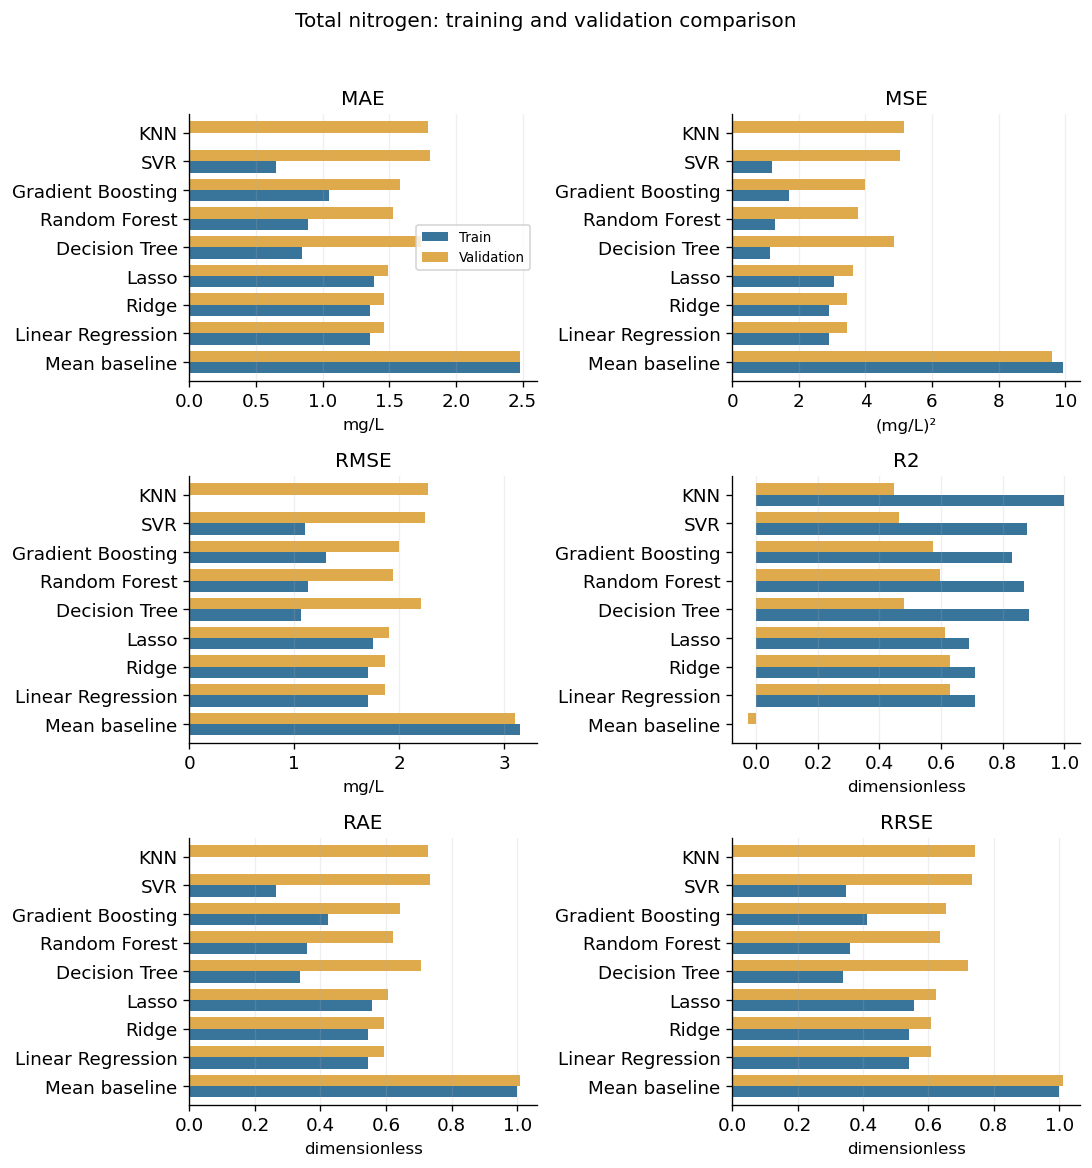

In [1171]:
plot_comparison(tn_comparison['metrics'],'Total nitrogen','mg/L','comparison_total_nitrogen')

### 7.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1172]:
tn_validation_ranking = (tn_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
tn_best_name = tn_validation_ranking.loc[0,'Model']
tn_best_training_pipeline = tn_comparison['fitted'][tn_best_name]
display(tn_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Linear Regression,1.4606
1,Ridge,1.4614
2,Lasso,1.4931
3,Random Forest,1.5250
4,Gradient Boosting,1.5791
5,Decision Tree,1.7382
6,KNN,1.7935
7,SVR,1.8078
8,Mean baseline,2.4830


In [1173]:
print('Selected algorithm:',tn_best_name)
print('Validation MAE gap to runner-up:',
      float(tn_validation_ranking.loc[1,'MAE']-tn_validation_ranking.loc[0,'MAE']),'mg/L')
tn_mae_gaps=tn_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
tn_mae_gaps['Validation minus train']=tn_mae_gaps.Validation-tn_mae_gaps.Train
display(tn_mae_gaps.round(4))

Selected algorithm: Linear Regression
Validation MAE gap to runner-up: 0.0007903297684366262 mg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,0.8423,1.7382,0.8960
Gradient Boosting,1.0476,1.5791,0.5314
KNN,0.0000,1.7935,1.7935
Lasso,1.3841,1.4931,0.1091
Linear Regression,1.3540,1.4606,0.1066
Mean baseline,2.4844,2.4830,-0.0015
Random Forest,0.8920,1.5250,0.6330
Ridge,1.3533,1.4614,0.1081
SVR,0.6538,1.8078,1.1539


### 7.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1174]:
tn_validation_pred = tn_comparison['predictions'][tn_best_name]['Validation']
tn_validation_errors = error_frame(tn_validation,tn_validation[tn_target],tn_validation_pred)
display(tn_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,9.92,9.4388,0.4812,0.4812
511,WQ-0512,2024-04-12,WWTP-02,16.49,14.0192,2.4708,2.4708
512,WQ-0513,2024-04-12,WWTP-03,13.96,13.6661,0.2939,0.2939
513,WQ-0514,2024-04-12,WWTP-04,16.22,15.4983,0.7217,0.7217
514,WQ-0515,2024-04-12,WWTP-05,14.96,14.2480,0.7120,0.7120
515,WQ-0516,2024-04-13,WWTP-01,12.62,13.8813,-1.2613,1.2613
516,WQ-0517,2024-04-13,WWTP-02,7.51,10.2296,-2.7196,2.7196
517,WQ-0518,2024-04-13,WWTP-03,13.57,12.6035,0.9665,0.9665
518,WQ-0519,2024-04-13,WWTP-04,12.76,12.1159,0.6441,0.6441
519,WQ-0520,2024-04-13,WWTP-05,11.62,9.7618,1.8582,1.8582


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,1.3573,0.3049
1,WWTP-02,34,1.7669,0.3950
2,WWTP-03,34,1.4226,0.2459
3,WWTP-04,34,1.5125,-0.1978
4,WWTP-05,34,1.2440,0.1303


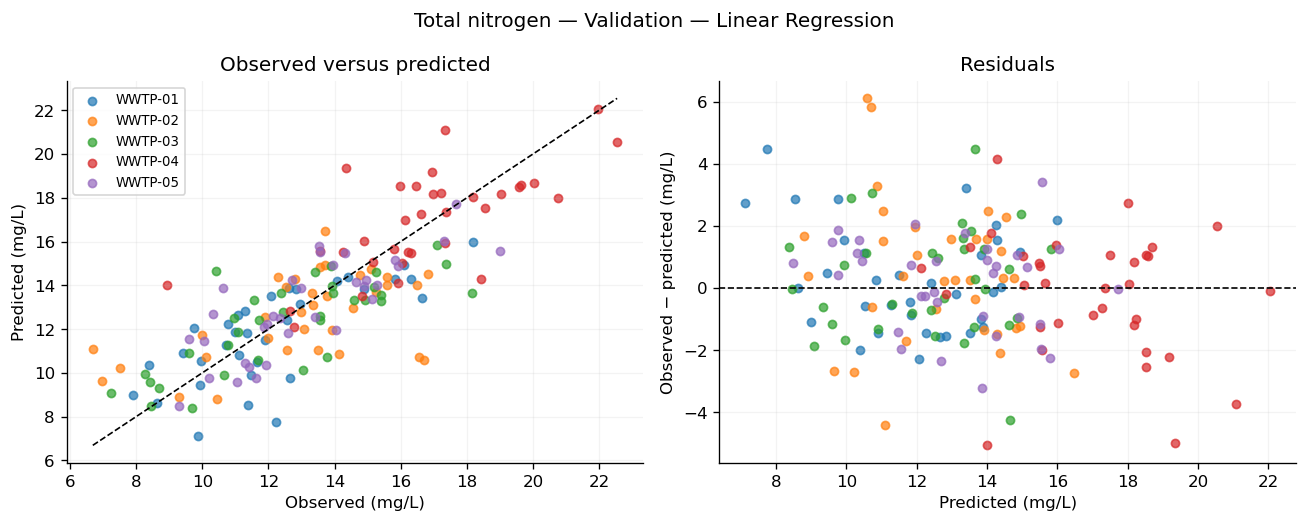

In [1175]:
display(plant_summary(tn_validation_errors).round(4))
plot_diagnostics(tn_validation_errors,'Total nitrogen','mg/L',tn_best_name,
                 'Validation','tn_validation_diagnostics')

### 7.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1176]:
tn_development = pd.concat([tn_train,tn_validation]).sort_values(['observation_date','plant_id'])

assert set(tn_development.index).isdisjoint(tn_test.index)

assert tn_development.observation_date.max() < tn_test.observation_date.min()

tn_final_pipeline = make_pipeline(MODELS[tn_best_name]).fit(
    tn_development[FEATURES],tn_development[tn_target])

tn_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    tn_development[FEATURES],tn_development[tn_target])

print('Final selected algorithm:',tn_best_name)

print('Development observations:',len(tn_development),'| test observations:',len(tn_test))

print('Last fitting date:',tn_development.observation_date.max().date())

print('First test date:',tn_test.observation_date.min().date())

Final selected algorithm: Linear Regression
Development observations: 680 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 7.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1177]:
tn_test_pred = tn_final_pipeline.predict(tn_test[FEATURES])

tn_baseline_pred = tn_mean_baseline.predict(tn_test[FEATURES])

tn_test_predictions = error_frame(tn_test,tn_test[tn_target],tn_test_pred)

tn_test_predictions['mean_baseline'] = tn_baseline_pred

tn_test_metrics = pd.DataFrame([
    {'Target':'Total nitrogen','Unit':'mg/L','Model':tn_best_name,
      **metrics(tn_test[tn_target],tn_test_pred)},
    
    {'Target':'Total nitrogen','Unit':'mg/L','Model':'Mean baseline',
      **metrics(tn_test[tn_target],tn_baseline_pred)}])

tn_mae_reduction = 100*(1-tn_test_metrics.loc[0,'MAE']/tn_test_metrics.loc[1,'MAE'])

display(tn_test_predictions.head(10).round(4))



,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,18.18,16.9227,1.2573,1.2573,13.1297
681,WQ-0682,2024-05-16,WWTP-02,11.48,15.8371,-4.3571,4.3571,13.1297
682,WQ-0683,2024-05-16,WWTP-03,13.96,14.6064,-0.6464,0.6464,13.1297
683,WQ-0684,2024-05-16,WWTP-04,17.15,15.5078,1.6422,1.6422,13.1297
684,WQ-0685,2024-05-16,WWTP-05,12.82,12.3764,0.4436,0.4436,13.1297
685,WQ-0686,2024-05-17,WWTP-01,9.86,10.2075,-0.3475,0.3475,13.1297
686,WQ-0687,2024-05-17,WWTP-02,14.02,12.4796,1.5404,1.5404,13.1297
687,WQ-0688,2024-05-17,WWTP-03,7.57,9.6542,-2.0842,2.0842,13.1297
688,WQ-0689,2024-05-17,WWTP-04,18.56,17.5604,0.9996,0.9996,13.1297
689,WQ-0690,2024-05-17,WWTP-05,11.43,10.6735,0.7565,0.7565,13.1297


In [1178]:
display(tn_test_metrics.round(4))
print('Test MAE:',round(tn_test_metrics.loc[0,'MAE'],4),'mg/L')
print('MAE reduction relative to the fitted mean:',round(tn_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Total nitrogen,mg/L,Linear Regression,1.3781,2.9499,1.7175,0.6826,0.5573,0.5633
1,Total nitrogen,mg/L,Mean baseline,2.4656,9.3009,3.0497,-0.0006,0.9970,1.0003


Test MAE: 1.3781 mg/L
MAE reduction relative to the fitted mean: 44.11 %
R² describes relative squared error, not percentage accuracy.


### 7.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

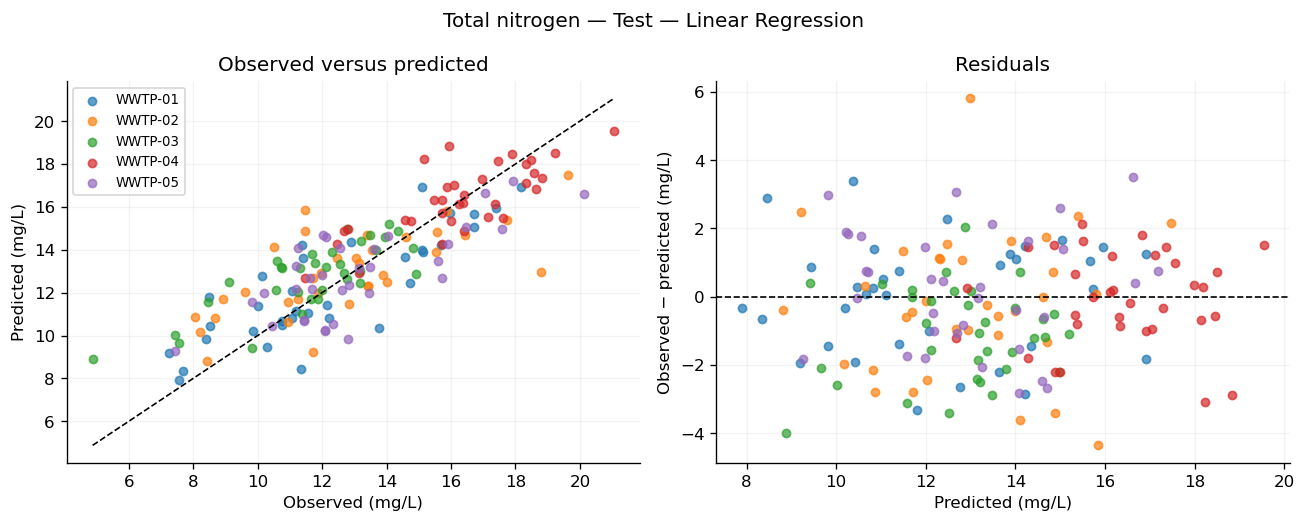

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,1.3672,-0.0053
1,WWTP-02,34,1.5940,-0.2134
2,WWTP-03,34,1.3730,-1.0918
3,WWTP-04,34,1.1014,-0.0701
4,WWTP-05,34,1.4552,0.1978


In [1179]:
plot_diagnostics(tn_test_predictions,'Total nitrogen','mg/L',tn_best_name,
                 'Test','tn_test_diagnostics')
display(plant_summary(tn_test_predictions).round(4))

### 7.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Total nitrogen pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1180]:
save_target_results('tn','Total nitrogen','mg/L',tn_target,
    tn_comparison,tn_best_name,tn_validation_ranking,
    tn_train,tn_validation,tn_development,tn_test,
    tn_final_pipeline,tn_mean_baseline,tn_validation_errors,
    tn_test_predictions,tn_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/tn
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 8 Total phosphorus prediction

**Target:** `effluent_total_phosphorus_mg_l`. **Unit:** mg/L. This section contains the complete Total phosphorus experiment in the same order as the original notebook. All figures and tables below concern Total phosphorus; the test period is reserved until the algorithm is selected.

### 8.1 Prepare the Total phosphorus data

**Why this step?** We predict Total phosphorus, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1181]:
tp_target = 'effluent_total_phosphorus_mg_l'
tp_known = data[tp_target].notna()
tp_frame = data.loc[tp_known].copy()
tp_X = tp_frame[FEATURES].copy()
tp_y = tp_frame[tp_target].copy()
tp_dates = tp_frame['observation_date'].copy()

assert tp_X.index.equals(tp_y.index)

print('Missing target rows excluded:', int((~tp_known).sum()))

print('X shape:', tp_X.shape, '| y shape:', tp_y.shape)

display(tp_frame[['record_id','observation_date','plant_id']+NUM[:3]+[tp_target]].head())

Missing target rows excluded: 3
X shape: (847, 17) | y shape: (847,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_total_phosphorus_mg_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,1.77
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,1.17
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,1.26
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,2.79
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,1.39


### 8.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,508,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,169,2024-05-16,2024-06-18


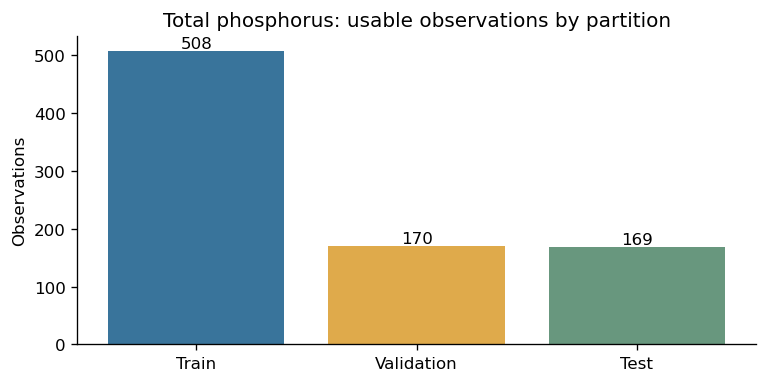

In [1182]:
tp_train_mask = tp_dates < VALID_START
tp_validation_mask = tp_dates.between(VALID_START, TEST_START, inclusive='left')
tp_test_mask = tp_dates >= TEST_START
tp_train = tp_frame.loc[tp_train_mask].copy()
tp_validation = tp_frame.loc[tp_validation_mask].copy()
tp_test = tp_frame.loc[tp_test_mask].copy()

assert len(tp_train)+len(tp_validation)+len(tp_test)==len(tp_frame)

assert tp_train.observation_date.max() < tp_validation.observation_date.min()

assert tp_validation.observation_date.max() < tp_test.observation_date.min()

tp_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    
    for name,frame in [('Train',tp_train),('Validation',tp_validation),('Test',tp_test)]])

display(tp_split_summary)

fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(tp_split_summary['Split'], tp_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Total phosphorus: usable observations by partition',ylabel='Observations')
for i,n in enumerate(tp_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'tp_split_counts')

### 8.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1183]:
display(tp_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1184]:
tp_comparison = compare_candidates('Total phosphorus',
    tp_train[FEATURES], tp_train[tp_target],
    tp_validation[FEATURES], tp_validation[tp_target])
display(tp_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Total phosphorus,Mean baseline,Train,0.3531,0.1964,0.4432,0.0000,1.0000,1.0000
1,Total phosphorus,Mean baseline,Validation,0.3768,0.2139,0.4625,-0.0014,1.0009,1.0007
2,Total phosphorus,Linear Regression,Train,0.2062,0.0698,0.2642,0.6447,0.5840,0.5960
3,Total phosphorus,Linear Regression,Validation,0.2307,0.0917,0.3027,0.5709,0.6128,0.6550
4,Total phosphorus,Ridge,Train,0.2062,0.0698,0.2642,0.6447,0.5839,0.5960
5,Total phosphorus,Ridge,Validation,0.2306,0.0916,0.3026,0.5712,0.6126,0.6548
6,Total phosphorus,Lasso,Train,0.2393,0.0934,0.3056,0.5246,0.6777,0.6895
7,Total phosphorus,Lasso,Validation,0.2685,0.1091,0.3303,0.4892,0.7134,0.7147
8,Total phosphorus,Decision Tree,Train,0.1447,0.0340,0.1845,0.8268,0.4099,0.4162
9,Total phosphorus,Decision Tree,Validation,0.2633,0.1118,0.3344,0.4767,0.6994,0.7234


### 8.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

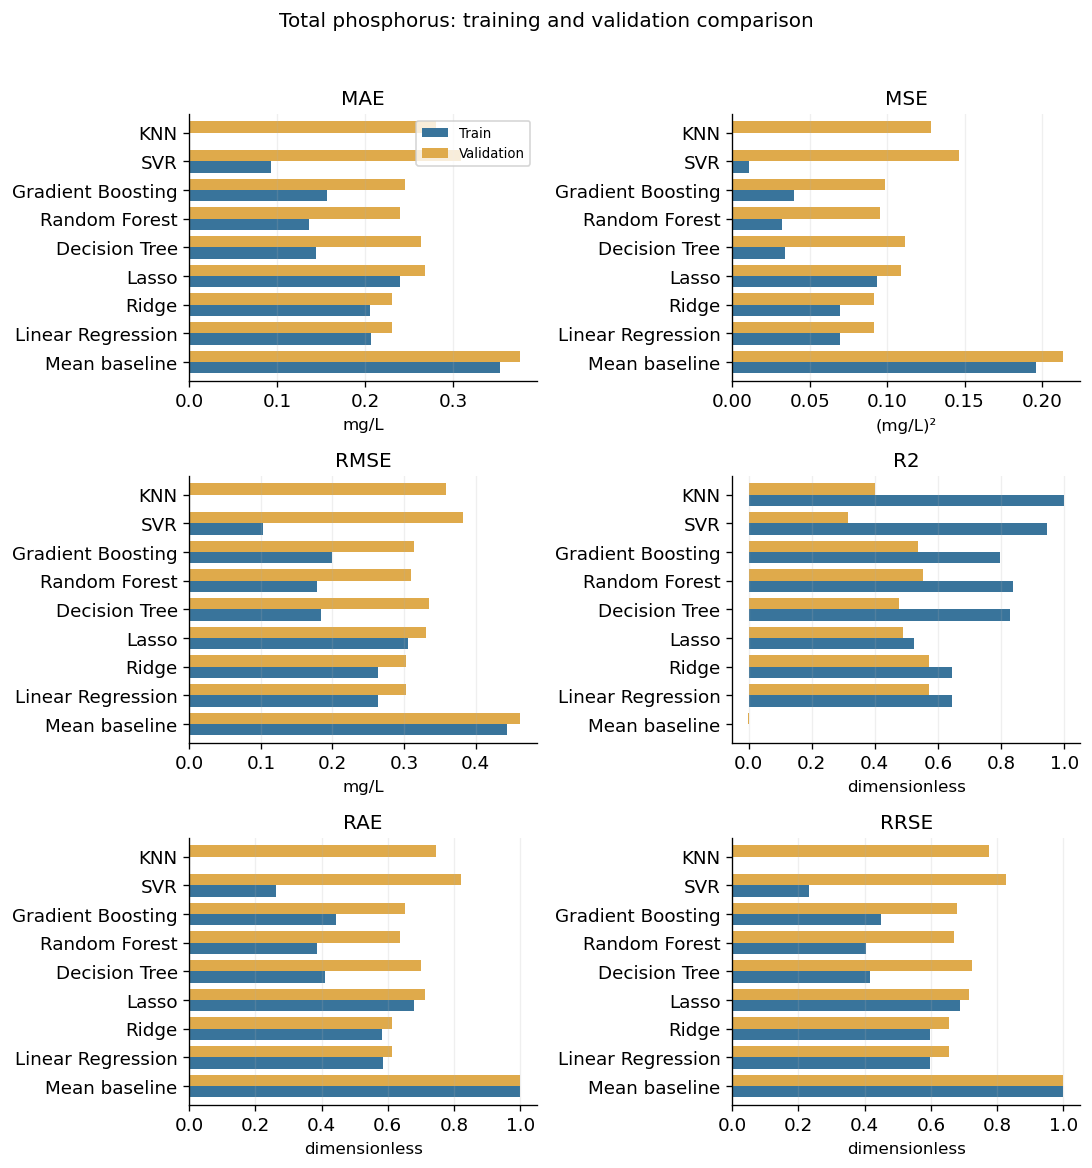

In [1185]:
plot_comparison(tp_comparison['metrics'],'Total phosphorus','mg/L','comparison_total_phosphorus')

### 8.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1186]:
tp_validation_ranking = (tp_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
tp_best_name = tp_validation_ranking.loc[0,'Model']
tp_best_training_pipeline = tp_comparison['fitted'][tp_best_name]
display(tp_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Ridge,0.2306
1,Linear Regression,0.2307
2,Random Forest,0.2395
3,Gradient Boosting,0.2458
4,Decision Tree,0.2633
5,Lasso,0.2685
6,KNN,0.2805
7,SVR,0.3095
8,Mean baseline,0.3768


In [1187]:
print('Selected algorithm:',tp_best_name)
print('Validation MAE gap to runner-up:',
      float(tp_validation_ranking.loc[1,'MAE']-tp_validation_ranking.loc[0,'MAE']),'mg/L')
tp_mae_gaps=tp_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
tp_mae_gaps['Validation minus train']=tp_mae_gaps.Validation-tp_mae_gaps.Train
display(tp_mae_gaps.round(4))

Selected algorithm: Ridge
Validation MAE gap to runner-up: 7.924935461006699e-05 mg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,0.1447,0.2633,0.1185
Gradient Boosting,0.1570,0.2458,0.0888
KNN,0.0000,0.2805,0.2805
Lasso,0.2393,0.2685,0.0292
Linear Regression,0.2062,0.2307,0.0245
Mean baseline,0.3531,0.3768,0.0237
Random Forest,0.1361,0.2395,0.1033
Ridge,0.2062,0.2306,0.0244
SVR,0.0925,0.3095,0.2170


### 8.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1188]:
tp_validation_pred = tp_comparison['predictions'][tp_best_name]['Validation']
tp_validation_errors = error_frame(tp_validation,tp_validation[tp_target],tp_validation_pred)
display(tp_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,1.60,1.6267,-0.0267,0.0267
511,WQ-0512,2024-04-12,WWTP-02,1.71,1.6752,0.0348,0.0348
512,WQ-0513,2024-04-12,WWTP-03,1.00,1.7059,-0.7059,0.7059
513,WQ-0514,2024-04-12,WWTP-04,1.40,1.9798,-0.5798,0.5798
514,WQ-0515,2024-04-12,WWTP-05,0.96,1.2925,-0.3325,0.3325
515,WQ-0516,2024-04-13,WWTP-01,1.94,1.6943,0.2457,0.2457
516,WQ-0517,2024-04-13,WWTP-02,0.89,1.2778,-0.3878,0.3878
517,WQ-0518,2024-04-13,WWTP-03,1.38,1.2448,0.1352,0.1352
518,WQ-0519,2024-04-13,WWTP-04,1.06,1.5362,-0.4762,0.4762
519,WQ-0520,2024-04-13,WWTP-05,1.46,1.2482,0.2118,0.2118


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.2101,0.0090
1,WWTP-02,34,0.2049,-0.0083
2,WWTP-03,34,0.2627,0.0712
3,WWTP-04,34,0.2558,-0.0291
4,WWTP-05,34,0.2196,0.0336


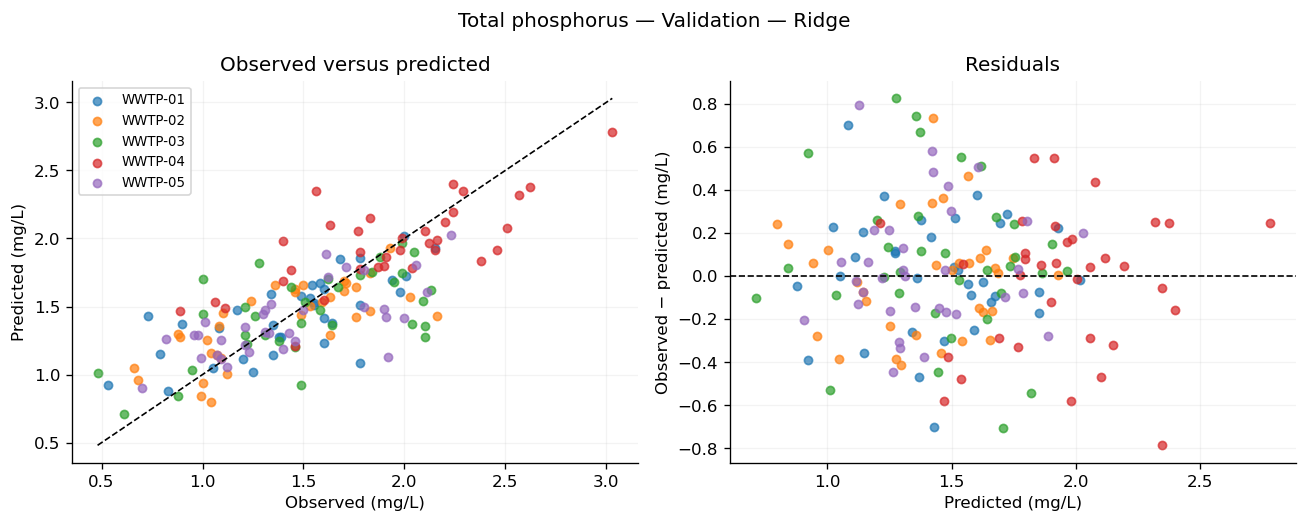

In [1189]:
display(plant_summary(tp_validation_errors).round(4))
plot_diagnostics(tp_validation_errors,'Total phosphorus','mg/L',tp_best_name,
                 'Validation','tp_validation_diagnostics')

### 8.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1190]:
tp_development = pd.concat([tp_train,tp_validation]).sort_values(['observation_date','plant_id'])

assert set(tp_development.index).isdisjoint(tp_test.index)

assert tp_development.observation_date.max() < tp_test.observation_date.min()

tp_final_pipeline = make_pipeline(MODELS[tp_best_name]).fit(
    tp_development[FEATURES],tp_development[tp_target])

tp_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    tp_development[FEATURES],tp_development[tp_target])

print('Final selected algorithm:',tp_best_name)

print('Development observations:',len(tp_development),'| test observations:',len(tp_test))

print('Last fitting date:',tp_development.observation_date.max().date())

print('First test date:',tp_test.observation_date.min().date())

Final selected algorithm: Ridge
Development observations: 678 | test observations: 169
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 8.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1191]:
tp_test_pred = tp_final_pipeline.predict(tp_test[FEATURES])
tp_baseline_pred = tp_mean_baseline.predict(tp_test[FEATURES])
tp_test_predictions = error_frame(tp_test,tp_test[tp_target],tp_test_pred)
tp_test_predictions['mean_baseline'] = tp_baseline_pred
tp_test_metrics = pd.DataFrame([
    {'Target':'Total phosphorus','Unit':'mg/L','Model':tp_best_name,
      **metrics(tp_test[tp_target],tp_test_pred)},
    {'Target':'Total phosphorus','Unit':'mg/L','Model':'Mean baseline',
      **metrics(tp_test[tp_target],tp_baseline_pred)}])

tp_mae_reduction = 100*(1-tp_test_metrics.loc[0,'MAE']/tp_test_metrics.loc[1,'MAE'])

display(tp_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,1.52,1.4299,0.0901,0.0901,1.5523
681,WQ-0682,2024-05-16,WWTP-02,1.66,1.7033,-0.0433,0.0433,1.5523
682,WQ-0683,2024-05-16,WWTP-03,1.37,1.7753,-0.4053,0.4053,1.5523
683,WQ-0684,2024-05-16,WWTP-04,2.29,2.3707,-0.0807,0.0807,1.5523
684,WQ-0685,2024-05-16,WWTP-05,1.16,1.4548,-0.2948,0.2948,1.5523
685,WQ-0686,2024-05-17,WWTP-01,1.61,1.4809,0.1291,0.1291,1.5523
686,WQ-0687,2024-05-17,WWTP-02,2.14,1.6580,0.4820,0.4820,1.5523
687,WQ-0688,2024-05-17,WWTP-03,1.33,1.0538,0.2762,0.2762,1.5523
688,WQ-0689,2024-05-17,WWTP-04,1.72,1.9405,-0.2205,0.2205,1.5523
689,WQ-0690,2024-05-17,WWTP-05,1.97,1.5198,0.4502,0.4502,1.5523


In [1192]:
display(tp_test_metrics.round(4))
print('Test MAE:',round(tp_test_metrics.loc[0,'MAE'],4),'mg/L')
print('MAE reduction relative to the fitted mean:',round(tp_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Total phosphorus,mg/L,Ridge,0.2390,0.0843,0.2903,0.4992,0.7078,0.7077
1,Total phosphorus,mg/L,Mean baseline,0.3382,0.1692,0.4113,-0.0056,1.0016,1.0028


Test MAE: 0.239 mg/L
MAE reduction relative to the fitted mean: 29.33 %
R² describes relative squared error, not percentage accuracy.


### 8.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

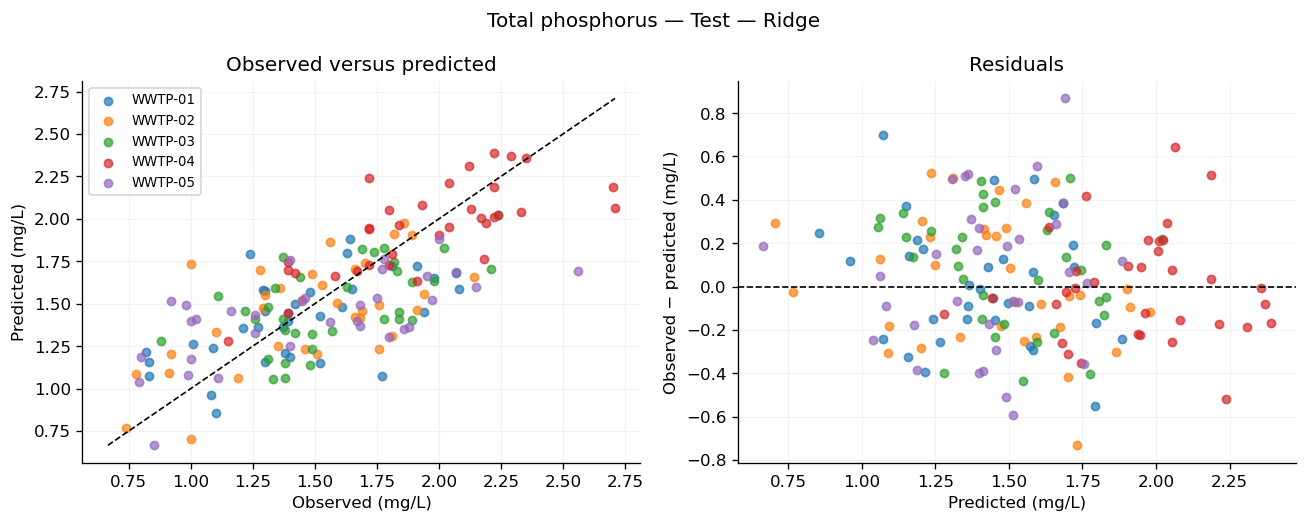

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.2281,0.0208
1,WWTP-02,34,0.2436,0.0201
2,WWTP-03,34,0.2372,0.0869
3,WWTP-04,34,0.1959,0.0001
4,WWTP-05,33,0.2917,0.0599


In [1193]:
plot_diagnostics(tp_test_predictions,'Total phosphorus','mg/L',tp_best_name,
                 'Test','tp_test_diagnostics')
display(plant_summary(tp_test_predictions).round(4))

### 8.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Total phosphorus pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1194]:
save_target_results('tp','Total phosphorus','mg/L',tp_target,
    tp_comparison,tp_best_name,tp_validation_ranking,
    tp_train,tp_validation,tp_development,tp_test,
    tp_final_pipeline,tp_mean_baseline,tp_validation_errors,
    tp_test_predictions,tp_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/tp
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 9 pH prediction

**Target:** `effluent_ph`. **Unit:** pH units. This section contains the complete pH experiment in the same order as the original notebook. All figures and tables below concern pH; the test period is reserved until the algorithm is selected.

### 9.1 Prepare the pH data

**Why this step?** We predict pH, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1195]:
ph_target = 'effluent_ph'
ph_known = data[ph_target].notna()
ph_frame = data.loc[ph_known].copy()
ph_X = ph_frame[FEATURES].copy()
ph_y = ph_frame[ph_target].copy()
ph_dates = ph_frame['observation_date'].copy()

assert ph_X.index.equals(ph_y.index)

print('Missing target rows excluded:', int((~ph_known).sum()))

print('X shape:', ph_X.shape, '| y shape:', ph_y.shape)

display(ph_frame[['record_id','observation_date','plant_id']+NUM[:3]+[ph_target]].head())

Missing target rows excluded: 1
X shape: (849, 17) | y shape: (849,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_ph
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,7.19
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,7.19
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,7.34
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,7.07
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,7.05


### 9.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

,Split,Rows,First date,Last date
0,Train,509,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


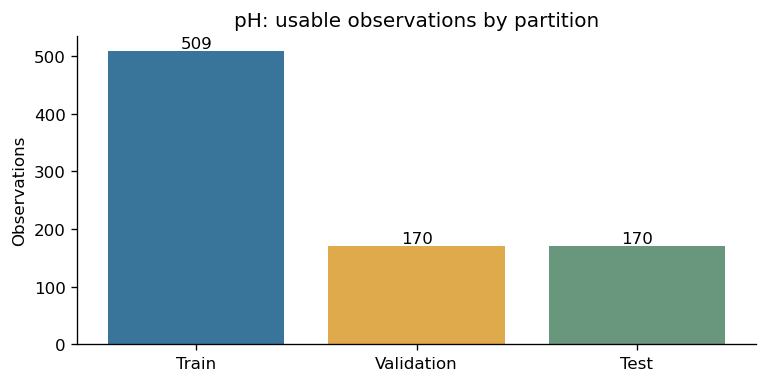

In [1196]:
ph_train_mask = ph_dates < VALID_START
ph_validation_mask = ph_dates.between(VALID_START, TEST_START, inclusive='left')
ph_test_mask = ph_dates >= TEST_START
ph_train = ph_frame.loc[ph_train_mask].copy()
ph_validation = ph_frame.loc[ph_validation_mask].copy()
ph_test = ph_frame.loc[ph_test_mask].copy()

assert len(ph_train)+len(ph_validation)+len(ph_test)==len(ph_frame)
assert ph_train.observation_date.max() < ph_validation.observation_date.min()
assert ph_validation.observation_date.max() < ph_test.observation_date.min()

ph_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',ph_train),('Validation',ph_validation),('Test',ph_test)]])

display(ph_split_summary)

fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(ph_split_summary['Split'], ph_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='pH: usable observations by partition',ylabel='Observations')
for i,n in enumerate(ph_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'ph_split_counts')

### 9.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1197]:
display(ph_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1198]:
ph_comparison = compare_candidates('pH',
    ph_train[FEATURES], ph_train[ph_target],
    ph_validation[FEATURES], ph_validation[ph_target])
display(ph_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,pH,Mean baseline,Train,0.1190,0.0228,0.1509,0.0000,1.0000,1.0000
1,pH,Mean baseline,Validation,0.1191,0.0215,0.1466,-0.0132,1.0063,1.0066
2,pH,Linear Regression,Train,0.1024,0.0163,0.1275,0.2859,0.8606,0.8450
3,pH,Linear Regression,Validation,0.1026,0.0167,0.1291,0.2142,0.8671,0.8865
4,pH,Ridge,Train,0.1024,0.0163,0.1275,0.2859,0.8607,0.8450
5,pH,Ridge,Validation,0.1026,0.0166,0.1290,0.2155,0.8664,0.8857
6,pH,Lasso,Train,0.1190,0.0228,0.1509,0.0000,1.0000,1.0000
7,pH,Lasso,Validation,0.1191,0.0215,0.1466,-0.0132,1.0063,1.0066
8,pH,Decision Tree,Train,0.0823,0.0105,0.1025,0.5390,0.6917,0.6790
9,pH,Decision Tree,Validation,0.1217,0.0229,0.1513,-0.0789,1.0281,1.0387


### 9.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

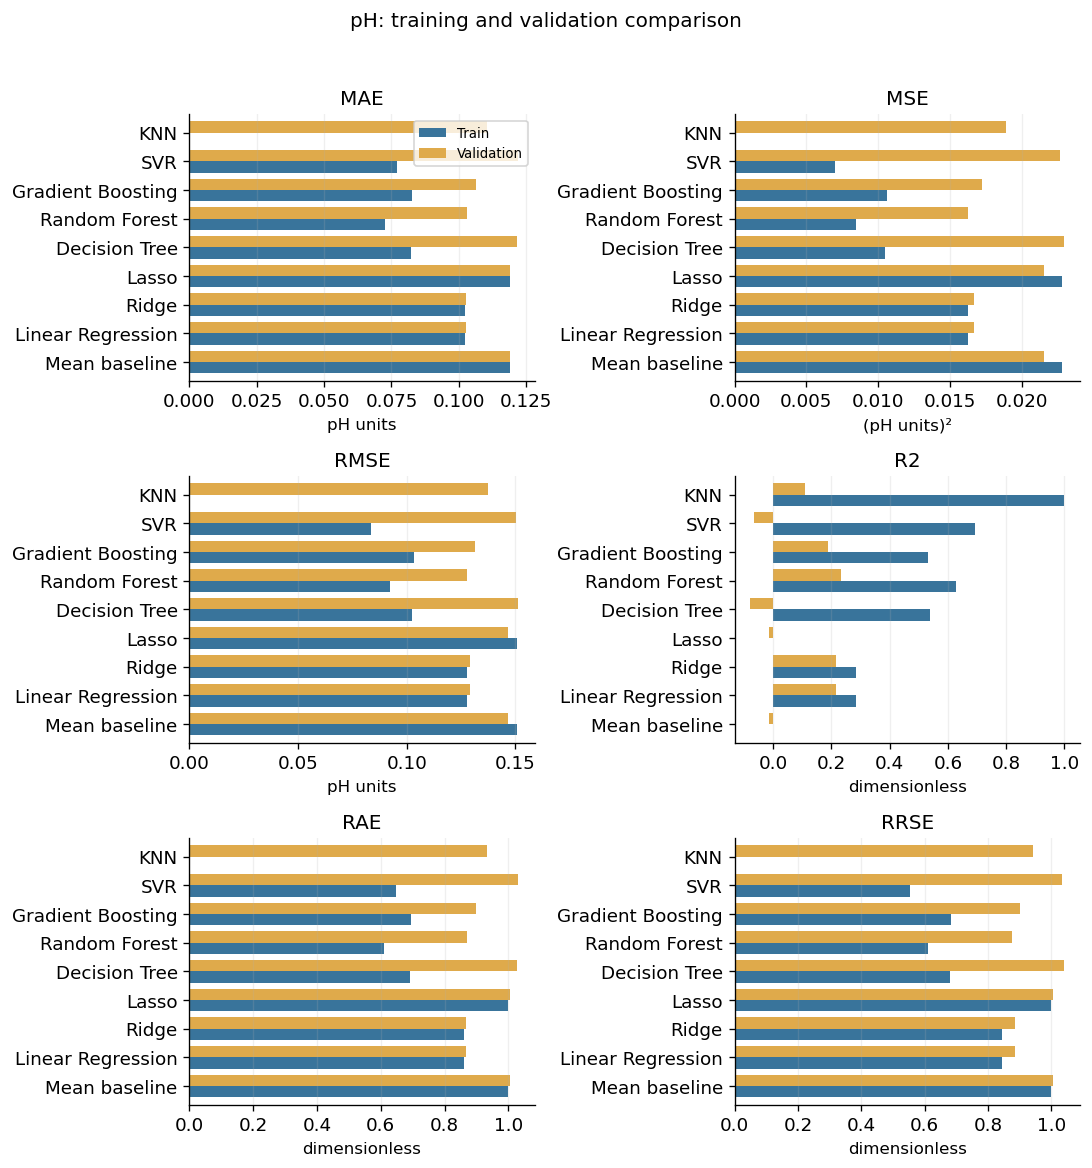

In [1199]:
plot_comparison(ph_comparison['metrics'],'pH','pH units','comparison_ph')

### 9.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1200]:
ph_validation_ranking = (ph_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
ph_best_name = ph_validation_ranking.loc[0,'Model']
ph_best_training_pipeline = ph_comparison['fitted'][ph_best_name]
display(ph_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Ridge,0.1026
1,Linear Regression,0.1026
2,Random Forest,0.1032
3,Gradient Boosting,0.1064
4,KNN,0.1104
5,Mean baseline,0.1191
6,Lasso,0.1191
7,Decision Tree,0.1217
8,SVR,0.1221


In [1201]:
print('Selected algorithm:',ph_best_name)
print('Validation MAE gap to runner-up:',
      float(ph_validation_ranking.loc[1,'MAE']-ph_validation_ranking.loc[0,'MAE']),'pH units')
ph_mae_gaps=ph_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
ph_mae_gaps['Validation minus train']=ph_mae_gaps.Validation-ph_mae_gaps.Train
display(ph_mae_gaps.round(4))

Selected algorithm: Ridge
Validation MAE gap to runner-up: 8.589321329681432e-05 pH units


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,0.0823,0.1217,0.0394
Gradient Boosting,0.0826,0.1064,0.0238
KNN,0.0000,0.1104,0.1104
Lasso,0.1190,0.1191,0.0001
Linear Regression,0.1024,0.1026,0.0002
Mean baseline,0.1190,0.1191,0.0001
Random Forest,0.0726,0.1032,0.0306
Ridge,0.1024,0.1026,0.0001
SVR,0.0772,0.1221,0.0448


### 9.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1202]:
ph_validation_pred = ph_comparison['predictions'][ph_best_name]['Validation']
ph_validation_errors = error_frame(ph_validation,ph_validation[ph_target],ph_validation_pred)
display(ph_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,6.81,6.9422,-0.1322,0.1322
511,WQ-0512,2024-04-12,WWTP-02,6.86,7.1028,-0.2428,0.2428
512,WQ-0513,2024-04-12,WWTP-03,7.03,7.0653,-0.0353,0.0353
513,WQ-0514,2024-04-12,WWTP-04,7.02,7.1060,-0.0860,0.0860
514,WQ-0515,2024-04-12,WWTP-05,7.32,7.1262,0.1938,0.1938
515,WQ-0516,2024-04-13,WWTP-01,7.25,7.0376,0.2124,0.2124
516,WQ-0517,2024-04-13,WWTP-02,7.32,7.0993,0.2207,0.2207
517,WQ-0518,2024-04-13,WWTP-03,7.09,7.1284,-0.0384,0.0384
518,WQ-0519,2024-04-13,WWTP-04,6.98,7.0492,-0.0692,0.0692
519,WQ-0520,2024-04-13,WWTP-05,7.18,7.0108,0.1692,0.1692


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.1034,-0.0170
1,WWTP-02,34,0.1174,-0.0279
2,WWTP-03,34,0.1089,0.0098
3,WWTP-04,34,0.0972,0.0057
4,WWTP-05,34,0.0859,0.0055


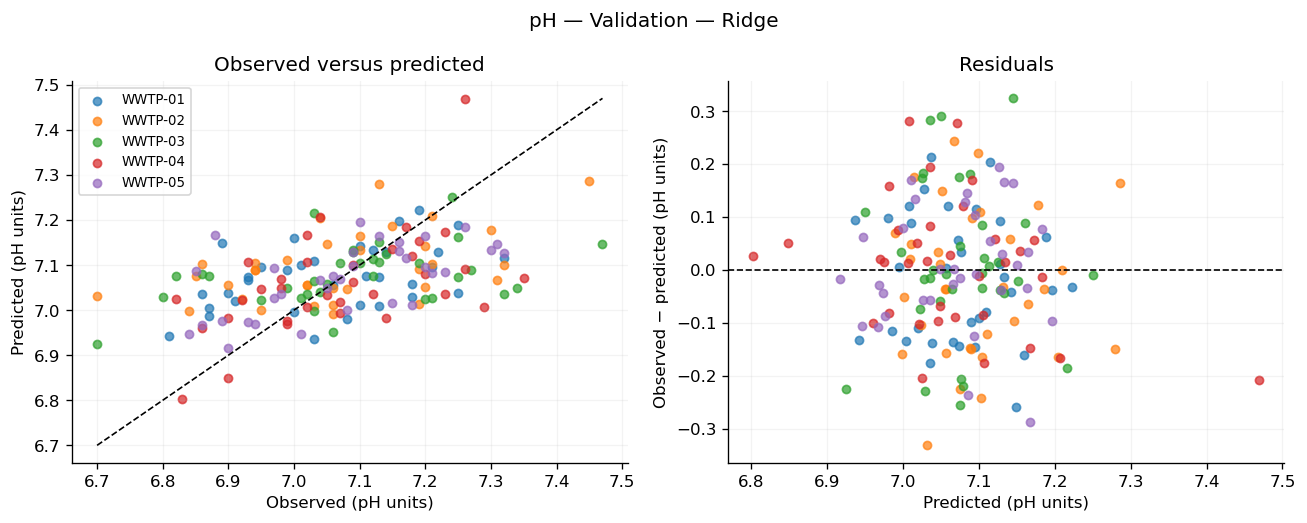

In [1203]:
display(plant_summary(ph_validation_errors).round(4))
plot_diagnostics(ph_validation_errors,'pH','pH units',ph_best_name,
                 'Validation','ph_validation_diagnostics')

### 9.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1204]:
ph_development = pd.concat([ph_train,ph_validation]).sort_values(['observation_date','plant_id'])

assert set(ph_development.index).isdisjoint(ph_test.index)

assert ph_development.observation_date.max() < ph_test.observation_date.min()

ph_final_pipeline = make_pipeline(MODELS[ph_best_name]).fit(
    ph_development[FEATURES],ph_development[ph_target])

ph_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    ph_development[FEATURES],ph_development[ph_target])

print('Final selected algorithm:',ph_best_name)

print('Development observations:',len(ph_development),'| test observations:',len(ph_test))

print('Last fitting date:',ph_development.observation_date.max().date())

print('First test date:',ph_test.observation_date.min().date())

Final selected algorithm: Ridge
Development observations: 679 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 9.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1205]:
ph_test_pred = ph_final_pipeline.predict(ph_test[FEATURES])
ph_baseline_pred = ph_mean_baseline.predict(ph_test[FEATURES])
ph_test_predictions = error_frame(ph_test,ph_test[ph_target],ph_test_pred)
ph_test_predictions['mean_baseline'] = ph_baseline_pred

ph_test_metrics = pd.DataFrame([
    {'Target':'pH','Unit':'pH units','Model':ph_best_name,
      **metrics(ph_test[ph_target],ph_test_pred)},
    {'Target':'pH','Unit':'pH units','Model':'Mean baseline',
      **metrics(ph_test[ph_target],ph_baseline_pred)}])

ph_mae_reduction = 100*(1-ph_test_metrics.loc[0,'MAE']/ph_test_metrics.loc[1,'MAE'])

display(ph_test_predictions.head(10).round(4))



,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,7.31,7.1728,0.1372,0.1372,7.0585
681,WQ-0682,2024-05-16,WWTP-02,7.19,7.1918,-0.0018,0.0018,7.0585
682,WQ-0683,2024-05-16,WWTP-03,6.94,6.9523,-0.0123,0.0123,7.0585
683,WQ-0684,2024-05-16,WWTP-04,7.03,6.9804,0.0496,0.0496,7.0585
684,WQ-0685,2024-05-16,WWTP-05,7.05,7.0593,-0.0093,0.0093,7.0585
685,WQ-0686,2024-05-17,WWTP-01,7.10,7.1342,-0.0342,0.0342,7.0585
686,WQ-0687,2024-05-17,WWTP-02,6.72,7.0699,-0.3499,0.3499,7.0585
687,WQ-0688,2024-05-17,WWTP-03,7.15,6.9887,0.1613,0.1613,7.0585
688,WQ-0689,2024-05-17,WWTP-04,7.29,7.0782,0.2118,0.2118,7.0585
689,WQ-0690,2024-05-17,WWTP-05,7.21,7.0812,0.1288,0.1288,7.0585


In [1206]:
display(ph_test_metrics.round(4))
print('Test MAE:',round(ph_test_metrics.loc[0,'MAE'],4),'pH units')
print('MAE reduction relative to the fitted mean:',round(ph_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,pH,pH units,Ridge,0.1075,0.0177,0.1331,0.1453,0.9237,0.9245
1,pH,pH units,Mean baseline,0.1168,0.0212,0.1454,-0.0204,1.0041,1.0101


Test MAE: 0.1075 pH units
MAE reduction relative to the fitted mean: 8.01 %
R² describes relative squared error, not percentage accuracy.


### 9.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

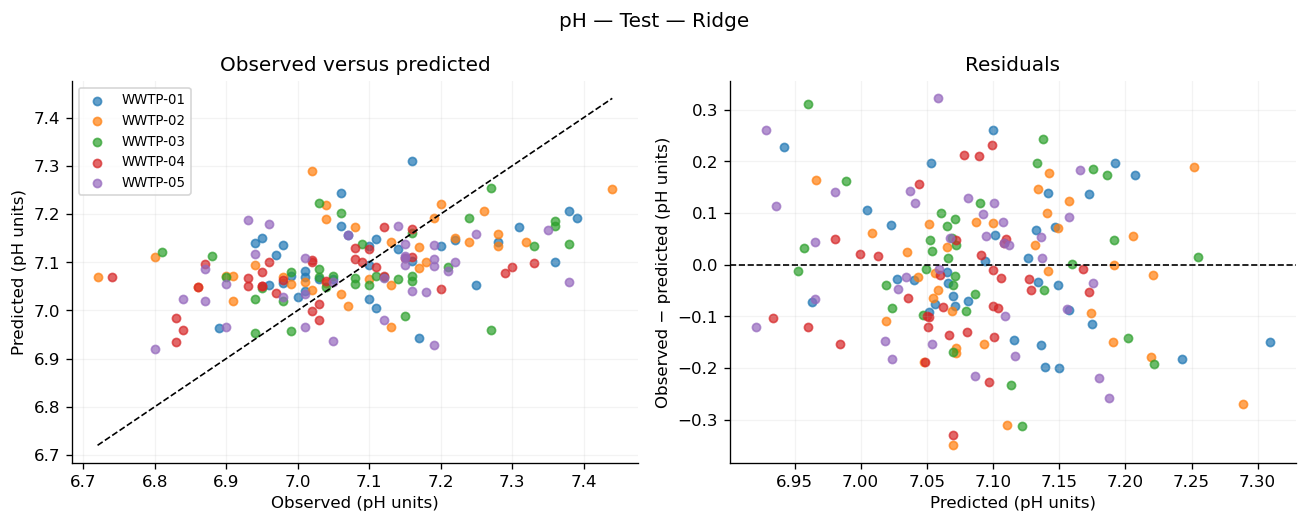

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.1060,-0.0041
1,WWTP-02,34,0.1128,-0.0292
2,WWTP-03,34,0.1021,0.0111
3,WWTP-04,34,0.1004,-0.0383
4,WWTP-05,34,0.1161,0.0076


In [1207]:
plot_diagnostics(ph_test_predictions,'pH','pH units',ph_best_name,
                 'Test','ph_test_diagnostics')
display(plant_summary(ph_test_predictions).round(4))

### 9.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved pH pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1208]:
save_target_results('ph','pH','pH units',ph_target,
    ph_comparison,ph_best_name,ph_validation_ranking,
    ph_train,ph_validation,ph_development,ph_test,
    ph_final_pipeline,ph_mean_baseline,ph_validation_errors,
    ph_test_predictions,ph_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/ph
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 10 Lithium prediction

**Target:** `effluent_lithium_ug_l`. **Unit:** µg/L. This section contains the complete Lithium experiment in the same order as the original notebook. All figures and tables below concern Lithium; the test period is reserved until the algorithm is selected.

### 10.1 Prepare the Lithium data

**Why this step?** We predict Lithium, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1209]:
li_target = 'effluent_lithium_ug_l'
li_known = data[li_target].notna()
li_frame = data.loc[li_known].copy()
li_X = li_frame[FEATURES].copy()
li_y = li_frame[li_target].copy()
li_dates = li_frame['observation_date'].copy()
assert li_X.index.equals(li_y.index)
print('Missing target rows excluded:', int((~li_known).sum()))
print('X shape:', li_X.shape, '| y shape:', li_y.shape)
display(li_frame[['record_id','observation_date','plant_id']+NUM[:3]+[li_target]].head())

Missing target rows excluded: 0
X shape: (850, 17) | y shape: (850,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_lithium_ug_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,32.45
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,34.84
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,28.57
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,45.46
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,50.52


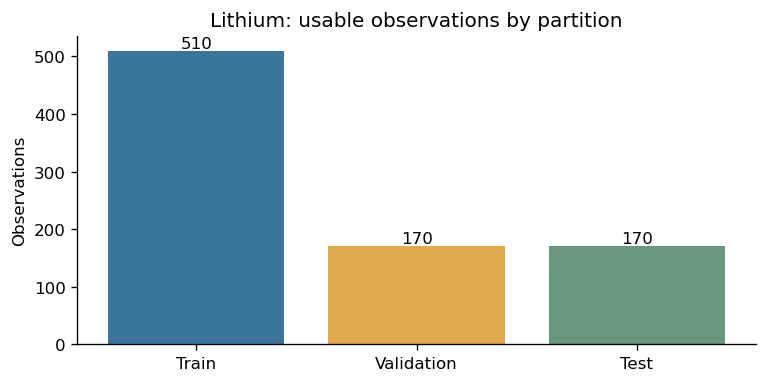

In [1210]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(li_split_summary['Split'], li_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Lithium: usable observations by partition',ylabel='Observations')
for i,n in enumerate(li_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'li_split_counts')

### 10.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

In [1211]:
li_train_mask = li_dates < VALID_START
li_validation_mask = li_dates.between(VALID_START, TEST_START, inclusive='left')
li_test_mask = li_dates >= TEST_START
li_train = li_frame.loc[li_train_mask].copy()
li_validation = li_frame.loc[li_validation_mask].copy()
li_test = li_frame.loc[li_test_mask].copy()
assert len(li_train)+len(li_validation)+len(li_test)==len(li_frame)
assert li_train.observation_date.max() < li_validation.observation_date.min()
assert li_validation.observation_date.max() < li_test.observation_date.min()
li_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',li_train),('Validation',li_validation),('Test',li_test)]])
display(li_split_summary)


,Split,Rows,First date,Last date
0,Train,510,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


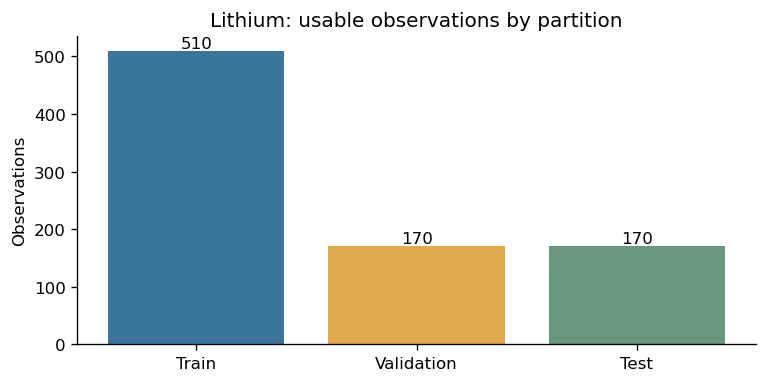

In [1212]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(li_split_summary['Split'], li_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Lithium: usable observations by partition',ylabel='Observations')
for i,n in enumerate(li_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'li_split_counts')

### 10.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1213]:
display(li_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1214]:
li_comparison = compare_candidates('Lithium',
    li_train[FEATURES], li_train[li_target],
    li_validation[FEATURES], li_validation[li_target])
display(li_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Lithium,Mean baseline,Train,9.5209,138.0193,11.7482,0.0000,1.0000,1.0000
1,Lithium,Mean baseline,Validation,9.8774,144.8616,12.0358,-0.0041,1.0133,1.0020
2,Lithium,Linear Regression,Train,1.7454,4.8505,2.2024,0.9649,0.1833,0.1875
3,Lithium,Linear Regression,Validation,1.7461,4.5531,2.1338,0.9684,0.1791,0.1776
4,Lithium,Ridge,Train,1.7450,4.8536,2.2031,0.9648,0.1833,0.1875
5,Lithium,Ridge,Validation,1.7429,4.5388,2.1304,0.9685,0.1788,0.1774
6,Lithium,Lasso,Train,1.7639,5.0214,2.2409,0.9636,0.1853,0.1907
7,Lithium,Lasso,Validation,1.7544,4.6814,2.1636,0.9676,0.1800,0.1801
8,Lithium,Decision Tree,Train,1.1265,2.1282,1.4588,0.9846,0.1183,0.1242
9,Lithium,Decision Tree,Validation,2.2440,8.0702,2.8408,0.9441,0.2302,0.2365


### 10.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

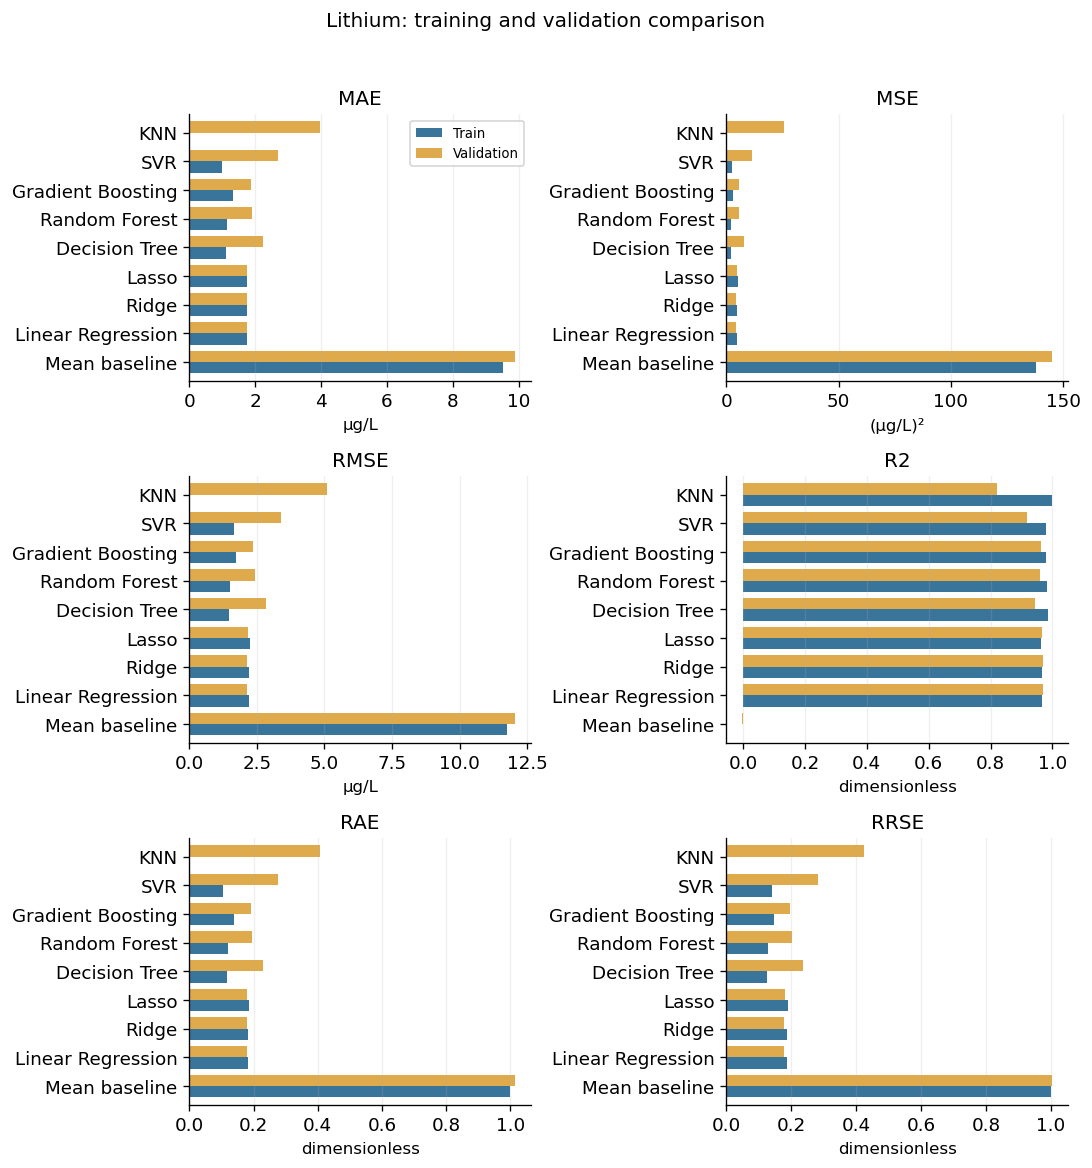

In [1215]:
plot_comparison(li_comparison['metrics'],'Lithium','µg/L','comparison_lithium')

### 10.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1216]:
li_validation_ranking = (li_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
li_best_name = li_validation_ranking.loc[0,'Model']
li_best_training_pipeline = li_comparison['fitted'][li_best_name]
display(li_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Ridge,1.7429
1,Linear Regression,1.7461
2,Lasso,1.7544
3,Gradient Boosting,1.8800
4,Random Forest,1.9167
5,Decision Tree,2.2440
6,SVR,2.6823
7,KNN,3.9599
8,Mean baseline,9.8774


In [1217]:
print('Selected algorithm:',li_best_name)
print('Validation MAE gap to runner-up:',
      float(li_validation_ranking.loc[1,'MAE']-li_validation_ranking.loc[0,'MAE']),'µg/L')
li_mae_gaps=li_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
li_mae_gaps['Validation minus train']=li_mae_gaps.Validation-li_mae_gaps.Train
display(li_mae_gaps.round(4))

Selected algorithm: Ridge
Validation MAE gap to runner-up: 0.0032046570556116816 µg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,1.1265,2.2440,1.1176
Gradient Boosting,1.3338,1.8800,0.5462
KNN,0.0000,3.9599,3.9599
Lasso,1.7639,1.7544,-0.0095
Linear Regression,1.7454,1.7461,0.0006
Mean baseline,9.5209,9.8774,0.3565
Random Forest,1.1489,1.9167,0.7679
Ridge,1.7450,1.7429,-0.0021
SVR,0.9865,2.6823,1.6958


### 10.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1218]:
li_validation_pred = li_comparison['predictions'][li_best_name]['Validation']
li_validation_errors = error_frame(li_validation,li_validation[li_target],li_validation_pred)
display(li_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,42.45,37.5223,4.9277,4.9277
511,WQ-0512,2024-04-12,WWTP-02,43.29,44.2710,-0.9810,0.9810
512,WQ-0513,2024-04-12,WWTP-03,29.13,31.9361,-2.8061,2.8061
513,WQ-0514,2024-04-12,WWTP-04,55.75,56.3257,-0.5757,0.5757
514,WQ-0515,2024-04-12,WWTP-05,34.21,38.8541,-4.6441,4.6441
515,WQ-0516,2024-04-13,WWTP-01,31.27,30.6211,0.6489,0.6489
516,WQ-0517,2024-04-13,WWTP-02,39.76,42.0178,-2.2578,2.2578
517,WQ-0518,2024-04-13,WWTP-03,27.15,25.7785,1.3715,1.3715
518,WQ-0519,2024-04-13,WWTP-04,58.67,60.3943,-1.7243,1.7243
519,WQ-0520,2024-04-13,WWTP-05,51.95,55.2891,-3.3391,3.3391


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,1.6373,0.2112
1,WWTP-02,34,1.6515,-0.1582
2,WWTP-03,34,1.4826,0.0874
3,WWTP-04,34,2.1314,0.0366
4,WWTP-05,34,1.8116,-0.6483


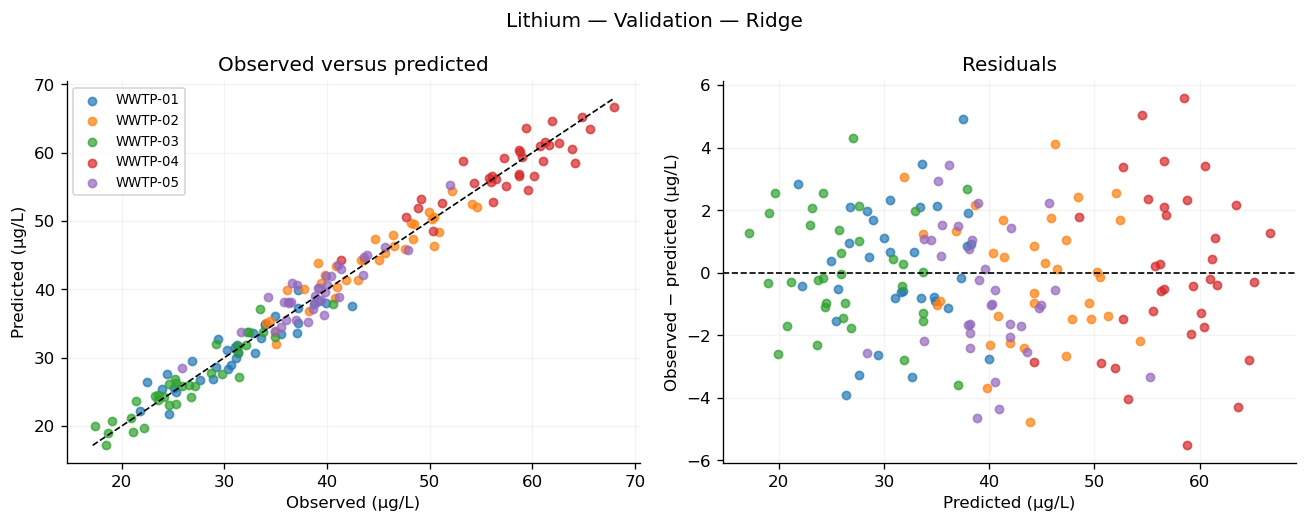

In [1219]:
display(plant_summary(li_validation_errors).round(4))
plot_diagnostics(li_validation_errors,'Lithium','µg/L',li_best_name,
                 'Validation','li_validation_diagnostics')

### 10.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1220]:
li_development = pd.concat([li_train,li_validation]).sort_values(['observation_date','plant_id'])
assert set(li_development.index).isdisjoint(li_test.index)
assert li_development.observation_date.max() < li_test.observation_date.min()
li_final_pipeline = make_pipeline(MODELS[li_best_name]).fit(
    li_development[FEATURES],li_development[li_target])
li_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    li_development[FEATURES],li_development[li_target])

print('Final selected algorithm:',li_best_name)

print('Development observations:',len(li_development),'| test observations:',len(li_test))

print('Last fitting date:',li_development.observation_date.max().date())

print('First test date:',li_test.observation_date.min().date())

Final selected algorithm: Ridge
Development observations: 680 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 10.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1221]:
li_test_pred = li_final_pipeline.predict(li_test[FEATURES])
li_baseline_pred = li_mean_baseline.predict(li_test[FEATURES])
li_test_predictions = error_frame(li_test,li_test[li_target],li_test_pred)
li_test_predictions['mean_baseline'] = li_baseline_pred
li_test_metrics = pd.DataFrame([
    {'Target':'Lithium','Unit':'µg/L','Model':li_best_name,
      **metrics(li_test[li_target],li_test_pred)},
    {'Target':'Lithium','Unit':'µg/L','Model':'Mean baseline',
      **metrics(li_test[li_target],li_baseline_pred)}])
li_mae_reduction = 100*(1-li_test_metrics.loc[0,'MAE']/li_test_metrics.loc[1,'MAE'])
display(li_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,26.30,25.2471,1.0529,1.0529,40.3305
681,WQ-0682,2024-05-16,WWTP-02,39.02,38.1003,0.9197,0.9197,40.3305
682,WQ-0683,2024-05-16,WWTP-03,26.90,26.1111,0.7889,0.7889,40.3305
683,WQ-0684,2024-05-16,WWTP-04,62.08,62.7278,-0.6478,0.6478,40.3305
684,WQ-0685,2024-05-16,WWTP-05,37.56,40.9884,-3.4284,3.4284,40.3305
685,WQ-0686,2024-05-17,WWTP-01,30.57,32.7245,-2.1545,2.1545,40.3305
686,WQ-0687,2024-05-17,WWTP-02,46.80,51.1043,-4.3043,4.3043,40.3305
687,WQ-0688,2024-05-17,WWTP-03,33.71,35.5489,-1.8389,1.8389,40.3305
688,WQ-0689,2024-05-17,WWTP-04,53.71,52.2500,1.4600,1.4600,40.3305
689,WQ-0690,2024-05-17,WWTP-05,39.37,41.8984,-2.5284,2.5284,40.3305


In [1222]:
display(li_test_metrics.round(4))
print('Test MAE:',round(li_test_metrics.loc[0,'MAE'],4),'µg/L')
print('MAE reduction relative to the fitted mean:',round(li_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Lithium,µg/L,Ridge,2.0003,7.1580,2.6754,0.9481,0.2123,0.2277
1,Lithium,µg/L,Mean baseline,9.4009,138.0841,11.7509,-0.0003,0.9976,1.0001


Test MAE: 2.0003 µg/L
MAE reduction relative to the fitted mean: 78.72 %
R² describes relative squared error, not percentage accuracy.


### 10.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

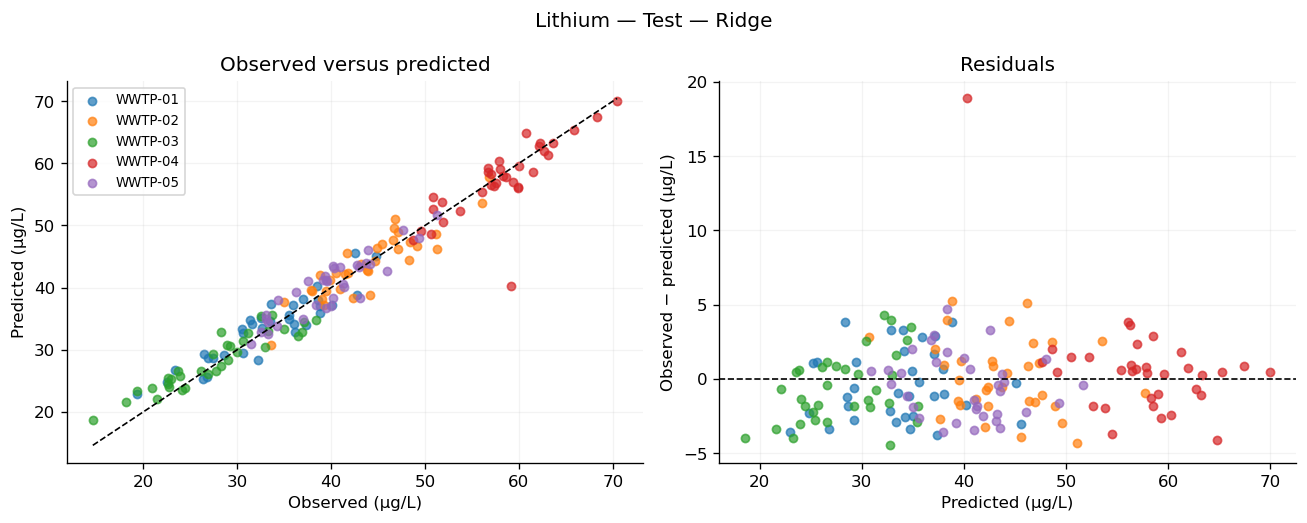

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,2.0800,-0.4247
1,WWTP-02,34,2.0360,0.1474
2,WWTP-03,34,2.0203,-0.6253
3,WWTP-04,34,2.0477,0.7214
4,WWTP-05,34,1.8174,-0.4158


In [1223]:
plot_diagnostics(li_test_predictions,'Lithium','µg/L',li_best_name,
                 'Test','li_test_diagnostics')
display(plant_summary(li_test_predictions).round(4))

### 10.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Lithium pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1224]:
save_target_results('li','Lithium','µg/L',li_target,
    li_comparison,li_best_name,li_validation_ranking,
    li_train,li_validation,li_development,li_test,
    li_final_pipeline,li_mean_baseline,li_validation_errors,
    li_test_predictions,li_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/li
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 11 Cobalt prediction

**Target:** `effluent_cobalt_ug_l`. **Unit:** µg/L. This section contains the complete Cobalt experiment in the same order as the original notebook. All figures and tables below concern Cobalt; the test period is reserved until the algorithm is selected.

### 11.1 Prepare the Cobalt data

**Why this step?** We predict Cobalt, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1225]:
co_target = 'effluent_cobalt_ug_l'
co_known = data[co_target].notna()
co_frame = data.loc[co_known].copy()
co_X = co_frame[FEATURES].copy()
co_y = co_frame[co_target].copy()
co_dates = co_frame['observation_date'].copy()
assert co_X.index.equals(co_y.index)
print('Missing target rows excluded:', int((~co_known).sum()))
print('X shape:', co_X.shape, '| y shape:', co_y.shape)
display(co_frame[['record_id','observation_date','plant_id']+NUM[:3]+[co_target]].head())

Missing target rows excluded: 6
X shape: (844, 17) | y shape: (844,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_cobalt_ug_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,4.73
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,4.98
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,2.64
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,9.08
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,6.42


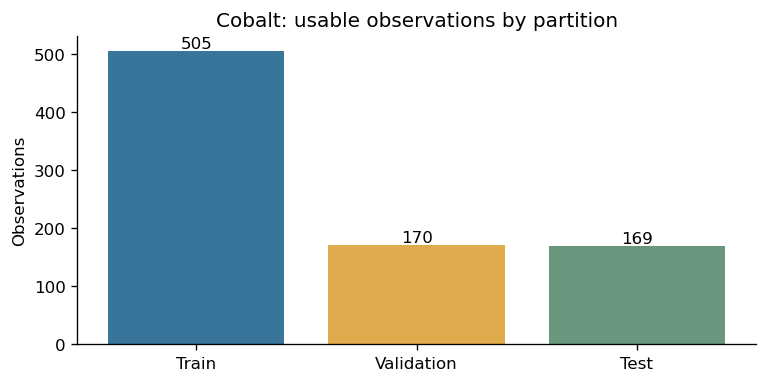

In [1226]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(co_split_summary['Split'], co_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Cobalt: usable observations by partition',ylabel='Observations')
for i,n in enumerate(co_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'co_split_counts')

### 11.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

In [1227]:
co_train_mask = co_dates < VALID_START
co_validation_mask = co_dates.between(VALID_START, TEST_START, inclusive='left')
co_test_mask = co_dates >= TEST_START
co_train = co_frame.loc[co_train_mask].copy()
co_validation = co_frame.loc[co_validation_mask].copy()
co_test = co_frame.loc[co_test_mask].copy()
assert len(co_train)+len(co_validation)+len(co_test)==len(co_frame)
assert co_train.observation_date.max() < co_validation.observation_date.min()
assert co_validation.observation_date.max() < co_test.observation_date.min()
co_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',co_train),('Validation',co_validation),('Test',co_test)]])
display(co_split_summary)


,Split,Rows,First date,Last date
0,Train,505,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,169,2024-05-16,2024-06-18


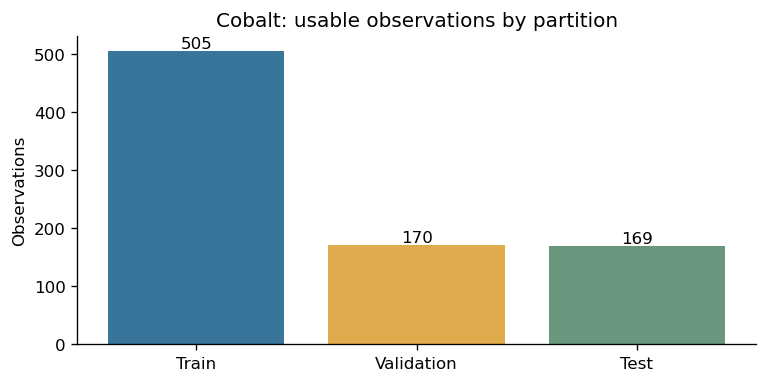

In [1228]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(co_split_summary['Split'], co_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Cobalt: usable observations by partition',ylabel='Observations')
for i,n in enumerate(co_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'co_split_counts')

### 11.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1229]:
display(co_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,0
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1230]:
co_comparison = compare_candidates('Cobalt',
    co_train[FEATURES], co_train[co_target],
    co_validation[FEATURES], co_validation[co_target])
display(co_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Cobalt,Mean baseline,Train,2.1818,7.3319,2.7078,0.0000,1.0000,1.0000
1,Cobalt,Mean baseline,Validation,2.2189,7.4464,2.7288,-0.0000,1.0004,1.0000
2,Cobalt,Linear Regression,Train,0.7956,0.9897,0.9949,0.8650,0.3647,0.3674
3,Cobalt,Linear Regression,Validation,0.8703,1.3022,1.1411,0.8251,0.3923,0.4182
4,Cobalt,Ridge,Train,0.7966,0.9898,0.9949,0.8650,0.3651,0.3674
5,Cobalt,Ridge,Validation,0.8707,1.3009,1.1406,0.8253,0.3925,0.4180
6,Cobalt,Lasso,Train,0.8242,1.0726,1.0357,0.8537,0.3778,0.3825
7,Cobalt,Lasso,Validation,0.8722,1.2783,1.1306,0.8283,0.3932,0.4143
8,Cobalt,Decision Tree,Train,0.4939,0.3982,0.6310,0.9457,0.2264,0.2331
9,Cobalt,Decision Tree,Validation,1.0617,1.8031,1.3428,0.7578,0.4787,0.4921


### 11.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

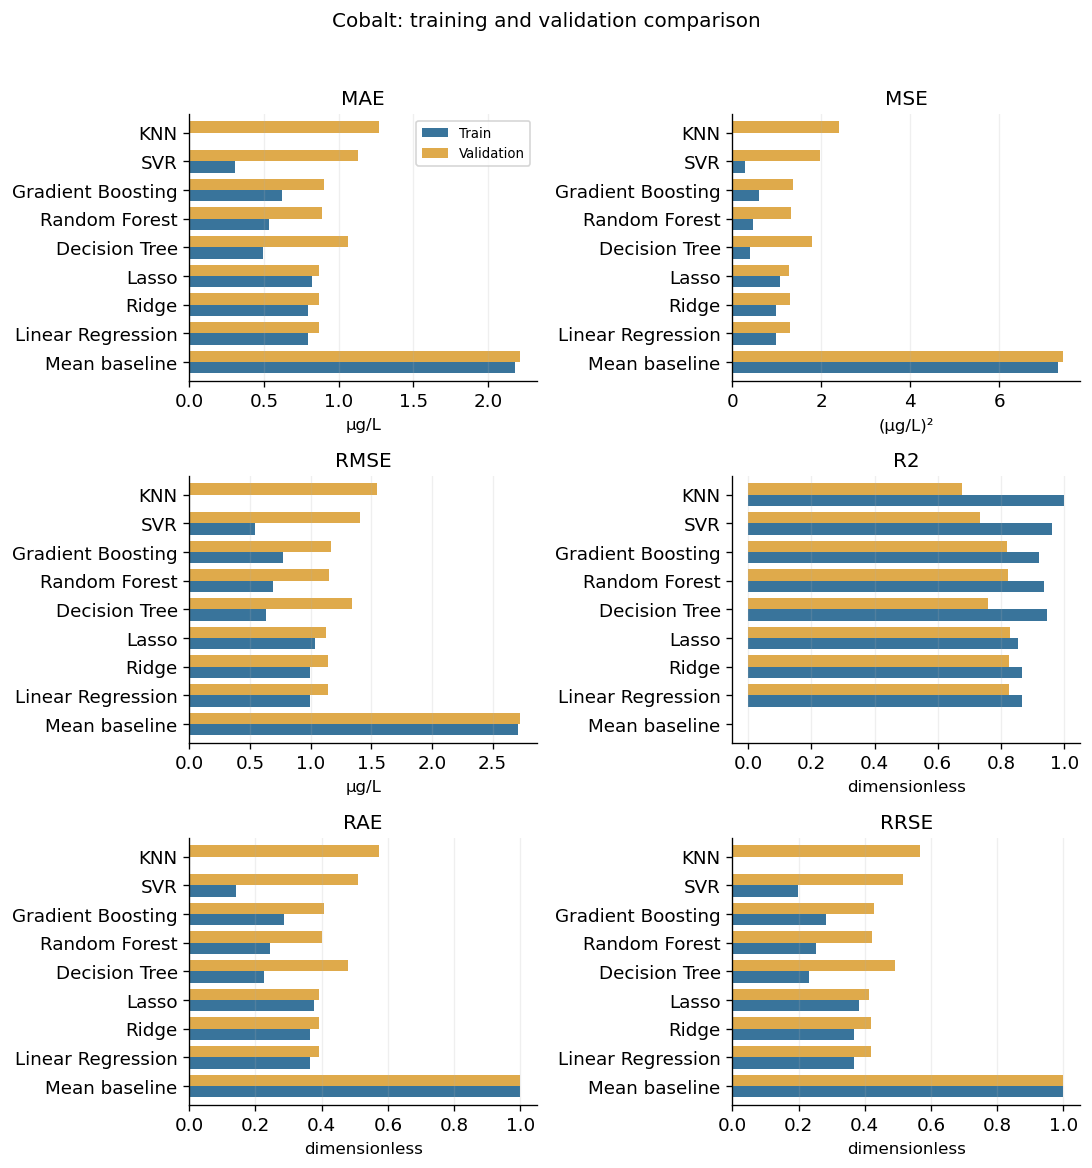

In [1231]:
plot_comparison(co_comparison['metrics'],'Cobalt','µg/L','comparison_cobalt')

### 11.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1232]:
co_validation_ranking = (co_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
co_best_name = co_validation_ranking.loc[0,'Model']
co_best_training_pipeline = co_comparison['fitted'][co_best_name]
display(co_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Linear Regression,0.8703
1,Ridge,0.8707
2,Lasso,0.8722
3,Random Forest,0.8878
4,Gradient Boosting,0.8997
5,Decision Tree,1.0617
6,SVR,1.1329
7,KNN,1.2687
8,Mean baseline,2.2189


In [1233]:
print('Selected algorithm:',co_best_name)

print('Validation MAE gap to runner-up:',
      float(co_validation_ranking.loc[1,'MAE']-co_validation_ranking.loc[0,'MAE']),'µg/L')

co_mae_gaps=co_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
co_mae_gaps['Validation minus train']=co_mae_gaps.Validation-co_mae_gaps.Train

display(co_mae_gaps.round(4))

Selected algorithm: Linear Regression
Validation MAE gap to runner-up: 0.00045959747800317086 µg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,0.4939,1.0617,0.5679
Gradient Boosting,0.6213,0.8997,0.2784
KNN,0.0000,1.2687,1.2687
Lasso,0.8242,0.8722,0.0480
Linear Regression,0.7956,0.8703,0.0746
Mean baseline,2.1818,2.2189,0.0371
Random Forest,0.5335,0.8878,0.3543
Ridge,0.7966,0.8707,0.0741
SVR,0.3077,1.1329,0.8252


### 11.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1234]:
co_validation_pred = co_comparison['predictions'][co_best_name]['Validation']
co_validation_errors = error_frame(co_validation,co_validation[co_target],co_validation_pred)
display(co_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,6.31,5.5844,0.7256,0.7256
511,WQ-0512,2024-04-12,WWTP-02,4.87,5.3313,-0.4613,0.4613
512,WQ-0513,2024-04-12,WWTP-03,4.49,3.9686,0.5214,0.5214
513,WQ-0514,2024-04-12,WWTP-04,9.95,7.1886,2.7614,2.7614
514,WQ-0515,2024-04-12,WWTP-05,1.59,3.2700,-1.6800,1.6800
515,WQ-0516,2024-04-13,WWTP-01,1.82,2.2018,-0.3818,0.3818
516,WQ-0517,2024-04-13,WWTP-02,3.21,3.3820,-0.1720,0.1720
517,WQ-0518,2024-04-13,WWTP-03,3.23,2.8508,0.3792,0.3792
518,WQ-0519,2024-04-13,WWTP-04,9.93,4.7308,5.1992,5.1992
519,WQ-0520,2024-04-13,WWTP-05,6.21,5.5111,0.6989,0.6989


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.7262,-0.1822
1,WWTP-02,34,0.8848,0.3036
2,WWTP-03,34,0.7127,0.1028
3,WWTP-04,34,1.1428,0.1994
4,WWTP-05,34,0.8849,-0.1220


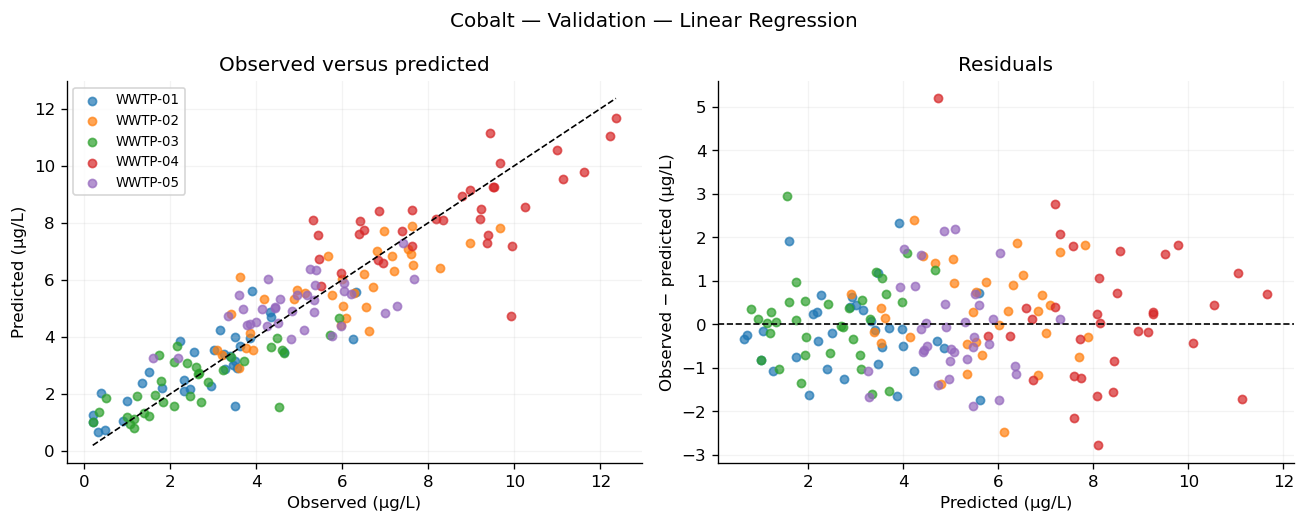

In [1235]:
display(plant_summary(co_validation_errors).round(4))
plot_diagnostics(co_validation_errors,'Cobalt','µg/L',co_best_name,
                 'Validation','co_validation_diagnostics')

### 11.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1236]:
co_development = pd.concat([co_train,co_validation]).sort_values(['observation_date','plant_id'])

assert set(co_development.index).isdisjoint(co_test.index)

assert co_development.observation_date.max() < co_test.observation_date.min()

co_final_pipeline = make_pipeline(MODELS[co_best_name]).fit(
    co_development[FEATURES],co_development[co_target])
co_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    co_development[FEATURES],co_development[co_target])

print('Final selected algorithm:',co_best_name)

print('Development observations:',len(co_development),'| test observations:',len(co_test))

print('Last fitting date:',co_development.observation_date.max().date())

print('First test date:',co_test.observation_date.min().date())

Final selected algorithm: Linear Regression
Development observations: 675 | test observations: 169
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 11.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1237]:
co_test_pred = co_final_pipeline.predict(co_test[FEATURES])
co_baseline_pred = co_mean_baseline.predict(co_test[FEATURES])
co_test_predictions = error_frame(co_test,co_test[co_target],co_test_pred)
co_test_predictions['mean_baseline'] = co_baseline_pred
co_test_metrics = pd.DataFrame([
    {'Target':'Cobalt','Unit':'µg/L','Model':co_best_name,
      **metrics(co_test[co_target],co_test_pred)},
    {'Target':'Cobalt','Unit':'µg/L','Model':'Mean baseline',
      **metrics(co_test[co_target],co_baseline_pred)}])
co_mae_reduction = 100*(1-co_test_metrics.loc[0,'MAE']/co_test_metrics.loc[1,'MAE'])
display(co_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,1.86,2.6727,-0.8127,0.8127,4.9308
681,WQ-0682,2024-05-16,WWTP-02,6.19,4.8362,1.3538,1.3538,4.9308
682,WQ-0683,2024-05-16,WWTP-03,0.85,1.9023,-1.0523,1.0523,4.9308
683,WQ-0684,2024-05-16,WWTP-04,8.43,8.4703,-0.0403,0.0403,4.9308
684,WQ-0685,2024-05-16,WWTP-05,6.81,5.6469,1.1631,1.1631,4.9308
685,WQ-0686,2024-05-17,WWTP-01,2.79,2.7962,-0.0062,0.0062,4.9308
686,WQ-0687,2024-05-17,WWTP-02,2.26,3.1282,-0.8682,0.8682,4.9308
687,WQ-0688,2024-05-17,WWTP-03,4.02,3.0346,0.9854,0.9854,4.9308
688,WQ-0689,2024-05-17,WWTP-04,6.50,8.3311,-1.8311,1.8311,4.9308
689,WQ-0690,2024-05-17,WWTP-05,5.18,4.5452,0.6348,0.6348,4.9308


In [1238]:
display(co_test_metrics.round(4))
print('Test MAE:',round(co_test_metrics.loc[0,'MAE'],4),'µg/L')
print('MAE reduction relative to the fitted mean:',round(co_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Cobalt,µg/L,Linear Regression,0.9147,1.2562,1.1208,0.8240,0.4141,0.4195
1,Cobalt,µg/L,Mean baseline,2.2142,7.1468,2.6734,-0.0012,1.0023,1.0006


Test MAE: 0.9147 µg/L
MAE reduction relative to the fitted mean: 58.69 %
R² describes relative squared error, not percentage accuracy.


### 11.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

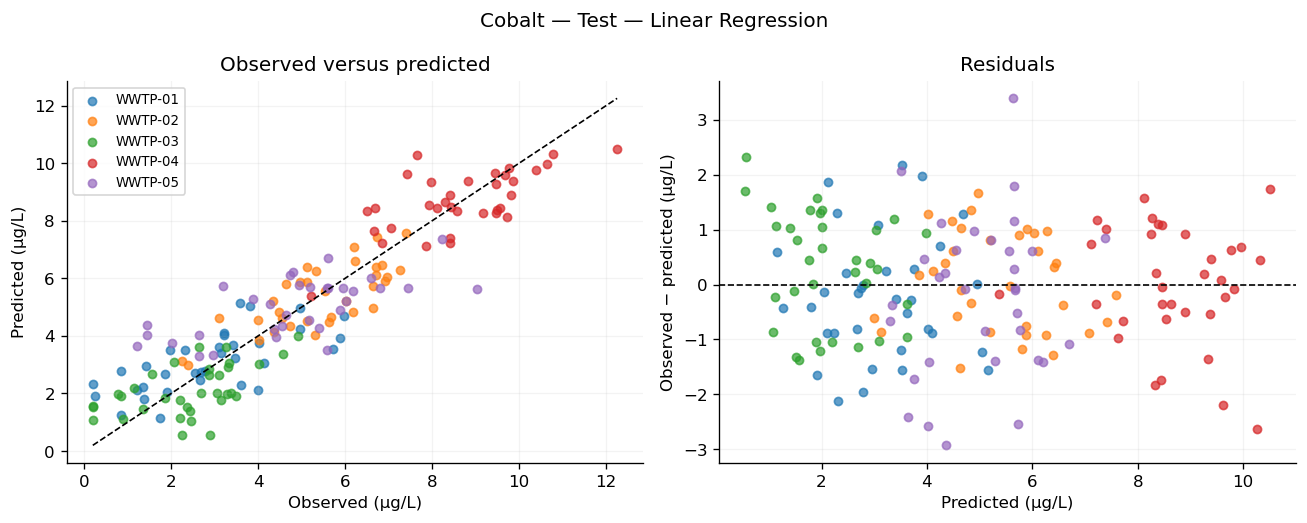

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,0.9123,-0.2220
1,WWTP-02,34,0.7629,0.0536
2,WWTP-03,34,0.9218,0.2926
3,WWTP-04,34,0.8474,-0.0114
4,WWTP-05,33,1.1355,-0.2176


In [1239]:
plot_diagnostics(co_test_predictions,'Cobalt','µg/L',co_best_name,
                 'Test','co_test_diagnostics')
display(plant_summary(co_test_predictions).round(4))

### 11.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Cobalt pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1240]:
save_target_results('co','Cobalt','µg/L',co_target,
    co_comparison,co_best_name,co_validation_ranking,
    co_train,co_validation,co_development,co_test,
    co_final_pipeline,co_mean_baseline,co_validation_errors,
    co_test_predictions,co_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/co
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 12 Nickel prediction

**Target:** `effluent_nickel_ug_l`. **Unit:** µg/L. This section contains the complete Nickel experiment in the same order as the original notebook. All figures and tables below concern Nickel; the test period is reserved until the algorithm is selected.

### 12.1 Prepare the Nickel data

**Why this step?** We predict Nickel, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1241]:
ni_target = 'effluent_nickel_ug_l'
ni_known = data[ni_target].notna()
ni_frame = data.loc[ni_known].copy()
ni_X = ni_frame[FEATURES].copy()
ni_y = ni_frame[ni_target].copy()
ni_dates = ni_frame['observation_date'].copy()
assert ni_X.index.equals(ni_y.index)

print('Missing target rows excluded:', int((~ni_known).sum()))

print('X shape:', ni_X.shape, '| y shape:', ni_y.shape)

display(ni_frame[['record_id','observation_date','plant_id']+NUM[:3]+[ni_target]].head())

Missing target rows excluded: 5
X shape: (845, 17) | y shape: (845,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_nickel_ug_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,17.19
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,14.54
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,6.27
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,29.38
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,22.70


### 12.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

In [1242]:
ni_train_mask = ni_dates < VALID_START
ni_validation_mask = ni_dates.between(VALID_START, TEST_START, inclusive='left')
ni_test_mask = ni_dates >= TEST_START
ni_train = ni_frame.loc[ni_train_mask].copy()
ni_validation = ni_frame.loc[ni_validation_mask].copy()
ni_test = ni_frame.loc[ni_test_mask].copy()
assert len(ni_train)+len(ni_validation)+len(ni_test)==len(ni_frame)
assert ni_train.observation_date.max() < ni_validation.observation_date.min()
assert ni_validation.observation_date.max() < ni_test.observation_date.min()
ni_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',ni_train),('Validation',ni_validation),('Test',ni_test)]])
display(ni_split_summary)


,Split,Rows,First date,Last date
0,Train,506,2024-01-01,2024-04-11
1,Validation,169,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


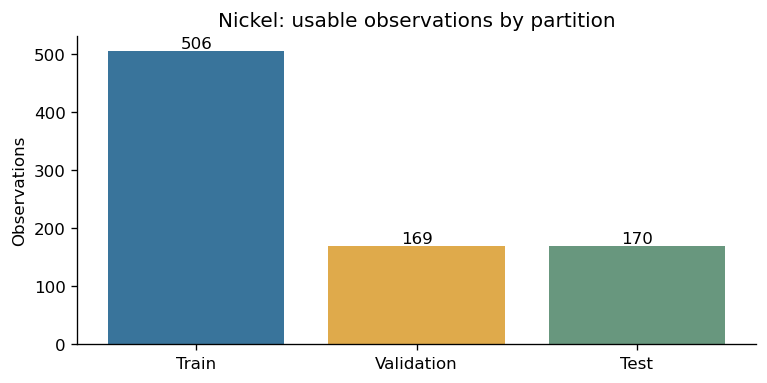

In [1243]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(ni_split_summary['Split'], ni_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Nickel: usable observations by partition',ylabel='Observations')
for i,n in enumerate(ni_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'ni_split_counts')

### 12.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1244]:
display(ni_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1245]:
ni_comparison = compare_candidates('Nickel',
    ni_train[FEATURES], ni_train[ni_target],
    ni_validation[FEATURES], ni_validation[ni_target])
display(ni_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Nickel,Mean baseline,Train,6.8293,70.0803,8.3714,0.0000,1.0000,1.0000
1,Nickel,Mean baseline,Validation,6.9338,72.5144,8.5155,-0.0006,0.9982,1.0003
2,Nickel,Linear Regression,Train,1.6291,4.1405,2.0348,0.9409,0.2386,0.2431
3,Nickel,Linear Regression,Validation,1.7945,5.0564,2.2486,0.9302,0.2583,0.2641
4,Nickel,Ridge,Train,1.6300,4.1418,2.0352,0.9409,0.2387,0.2431
5,Nickel,Ridge,Validation,1.7926,5.0454,2.2462,0.9304,0.2581,0.2639
6,Nickel,Lasso,Train,1.6601,4.2656,2.0653,0.9391,0.2431,0.2467
7,Nickel,Lasso,Validation,1.7901,4.9900,2.2338,0.9311,0.2577,0.2624
8,Nickel,Decision Tree,Train,1.0400,1.7159,1.3099,0.9755,0.1523,0.1565
9,Nickel,Decision Tree,Validation,2.2786,8.0388,2.8353,0.8891,0.3280,0.3331


### 12.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

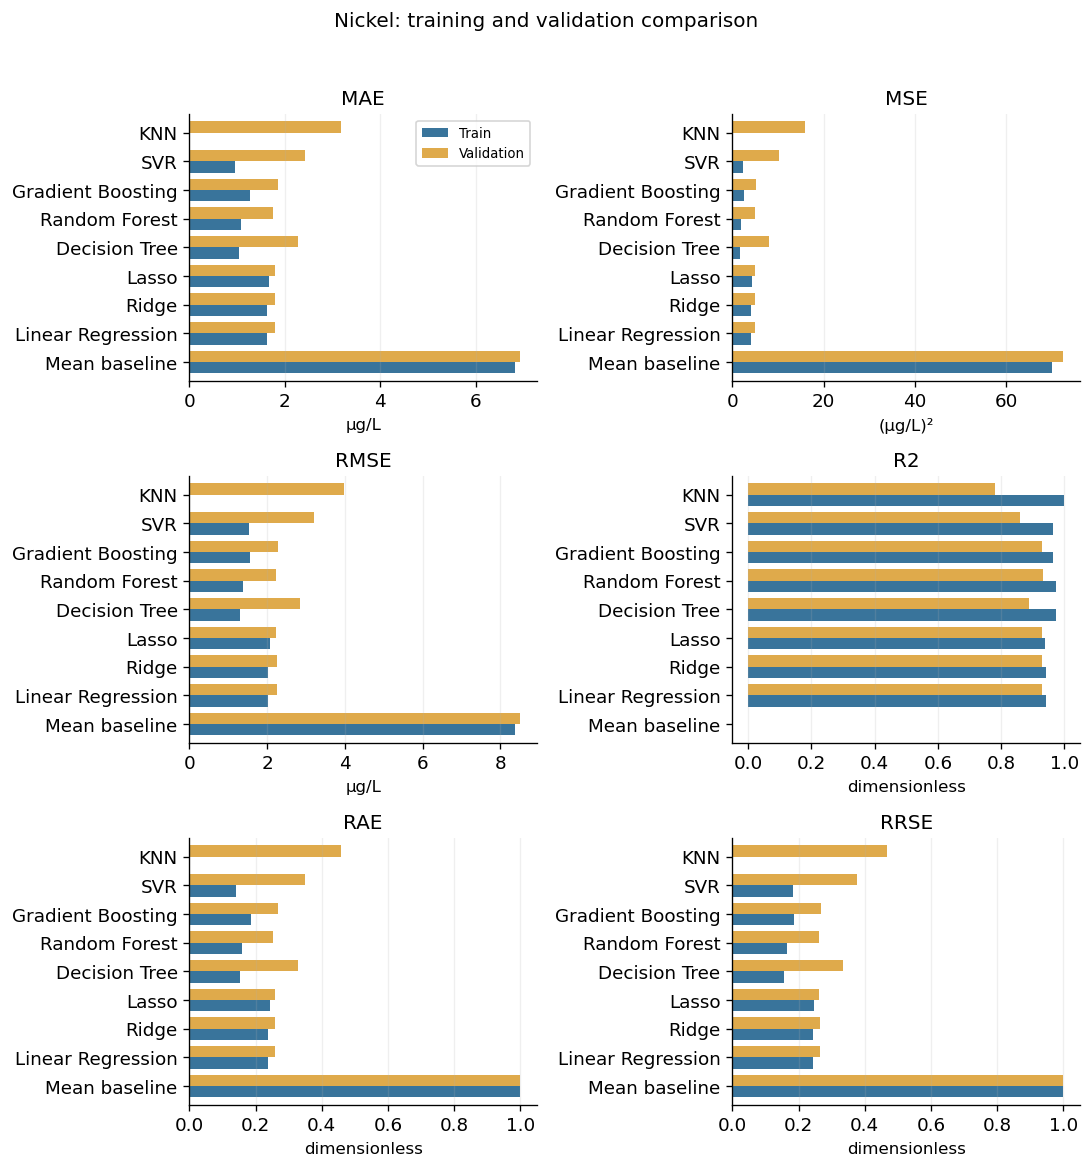

In [1246]:
plot_comparison(ni_comparison['metrics'],'Nickel','µg/L','comparison_nickel')

### 12.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1247]:
ni_validation_ranking = (ni_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
ni_best_name = ni_validation_ranking.loc[0,'Model']
ni_best_training_pipeline = ni_comparison['fitted'][ni_best_name]
display(ni_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Random Forest,1.7616
1,Lasso,1.7901
2,Ridge,1.7926
3,Linear Regression,1.7945
4,Gradient Boosting,1.8674
5,Decision Tree,2.2786
6,SVR,2.4249
7,KNN,3.1815
8,Mean baseline,6.9338


In [1248]:
print('Selected algorithm:',ni_best_name)
print('Validation MAE gap to runner-up:',
      float(ni_validation_ranking.loc[1,'MAE']-ni_validation_ranking.loc[0,'MAE']),'µg/L')
ni_mae_gaps=ni_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
ni_mae_gaps['Validation minus train']=ni_mae_gaps.Validation-ni_mae_gaps.Train
display(ni_mae_gaps.round(4))

Selected algorithm: Random Forest
Validation MAE gap to runner-up: 0.02843640775352041 µg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,1.0400,2.2786,1.2386
Gradient Boosting,1.2737,1.8674,0.5937
KNN,0.0000,3.1815,3.1815
Lasso,1.6601,1.7901,0.1299
Linear Regression,1.6291,1.7945,0.1653
Mean baseline,6.8293,6.9338,0.1046
Random Forest,1.0843,1.7616,0.6774
Ridge,1.6300,1.7926,0.1626
SVR,0.9633,2.4249,1.4617


### 12.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1249]:
ni_validation_pred = ni_comparison['predictions'][ni_best_name]['Validation']
ni_validation_errors = error_frame(ni_validation,ni_validation[ni_target],ni_validation_pred)
display(ni_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,7.39,5.8845,1.5055,1.5055
511,WQ-0512,2024-04-12,WWTP-02,20.42,16.6260,3.7940,3.7940
512,WQ-0513,2024-04-12,WWTP-03,6.40,6.5966,-0.1966,0.1966
513,WQ-0514,2024-04-12,WWTP-04,36.04,35.5039,0.5361,0.5361
514,WQ-0515,2024-04-12,WWTP-05,15.06,16.5374,-1.4774,1.4774
515,WQ-0516,2024-04-13,WWTP-01,18.92,14.6364,4.2836,4.2836
516,WQ-0517,2024-04-13,WWTP-02,14.14,16.5624,-2.4224,2.4224
517,WQ-0518,2024-04-13,WWTP-03,7.01,9.3545,-2.3445,2.3445
518,WQ-0519,2024-04-13,WWTP-04,29.60,28.2846,1.3154,1.3154
519,WQ-0520,2024-04-13,WWTP-05,17.23,16.6507,0.5793,0.5793


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,1.8585,0.3066
1,WWTP-02,34,1.7218,0.1874
2,WWTP-03,34,1.7789,-0.6989
3,WWTP-04,34,1.6251,0.0281
4,WWTP-05,33,1.8258,-0.9035


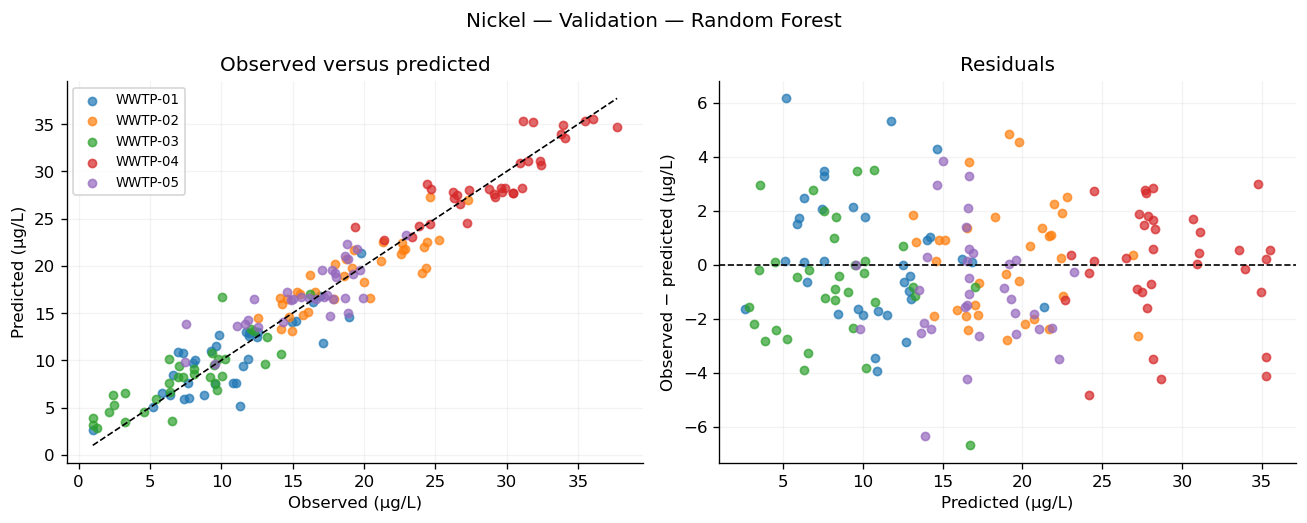

In [1250]:
display(plant_summary(ni_validation_errors).round(4))
plot_diagnostics(ni_validation_errors,'Nickel','µg/L',ni_best_name,
                 'Validation','ni_validation_diagnostics')

### 12.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1251]:
ni_development = pd.concat([ni_train,ni_validation]).sort_values(['observation_date','plant_id'])
assert set(ni_development.index).isdisjoint(ni_test.index)
assert ni_development.observation_date.max() < ni_test.observation_date.min()
ni_final_pipeline = make_pipeline(MODELS[ni_best_name]).fit(
    ni_development[FEATURES],ni_development[ni_target])
ni_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    ni_development[FEATURES],ni_development[ni_target])
print('Final selected algorithm:',ni_best_name)
print('Development observations:',len(ni_development),'| test observations:',len(ni_test))
print('Last fitting date:',ni_development.observation_date.max().date())
print('First test date:',ni_test.observation_date.min().date())

Final selected algorithm: Random Forest
Development observations: 675 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 12.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1252]:
ni_test_pred = ni_final_pipeline.predict(ni_test[FEATURES])
ni_baseline_pred = ni_mean_baseline.predict(ni_test[FEATURES])
ni_test_predictions = error_frame(ni_test,ni_test[ni_target],ni_test_pred)
ni_test_predictions['mean_baseline'] = ni_baseline_pred
ni_test_metrics = pd.DataFrame([
    {'Target':'Nickel','Unit':'µg/L','Model':ni_best_name,
      **metrics(ni_test[ni_target],ni_test_pred)},
    {'Target':'Nickel','Unit':'µg/L','Model':'Mean baseline',
      **metrics(ni_test[ni_target],ni_baseline_pred)}])
ni_mae_reduction = 100*(1-ni_test_metrics.loc[0,'MAE']/ni_test_metrics.loc[1,'MAE'])
display(ni_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,6.74,9.9446,-3.2046,3.2046,16.3779
681,WQ-0682,2024-05-16,WWTP-02,15.19,15.8732,-0.6832,0.6832,16.3779
682,WQ-0683,2024-05-16,WWTP-03,14.25,12.7057,1.5443,1.5443,16.3779
683,WQ-0684,2024-05-16,WWTP-04,25.93,28.4069,-2.4769,2.4769,16.3779
684,WQ-0685,2024-05-16,WWTP-05,15.38,15.7603,-0.3803,0.3803,16.3779
685,WQ-0686,2024-05-17,WWTP-01,12.46,10.2564,2.2036,2.2036,16.3779
686,WQ-0687,2024-05-17,WWTP-02,14.94,14.7454,0.1946,0.1946,16.3779
687,WQ-0688,2024-05-17,WWTP-03,8.52,11.1920,-2.6720,2.6720,16.3779
688,WQ-0689,2024-05-17,WWTP-04,24.70,27.1520,-2.4520,2.4520,16.3779
689,WQ-0690,2024-05-17,WWTP-05,20.99,20.4353,0.5547,0.5547,16.3779


In [1253]:
display(ni_test_metrics.round(4))
print('Test MAE:',round(ni_test_metrics.loc[0,'MAE'],4),'µg/L')
print('MAE reduction relative to the fitted mean:',round(ni_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Nickel,µg/L,Random Forest,1.8775,5.5695,2.360,0.9070,0.2939,0.3050
1,Nickel,µg/L,Mean baseline,6.4305,60.0156,7.747,-0.0025,1.0065,1.0012


Test MAE: 1.8775 µg/L
MAE reduction relative to the fitted mean: 70.8 %
R² describes relative squared error, not percentage accuracy.


### 12.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

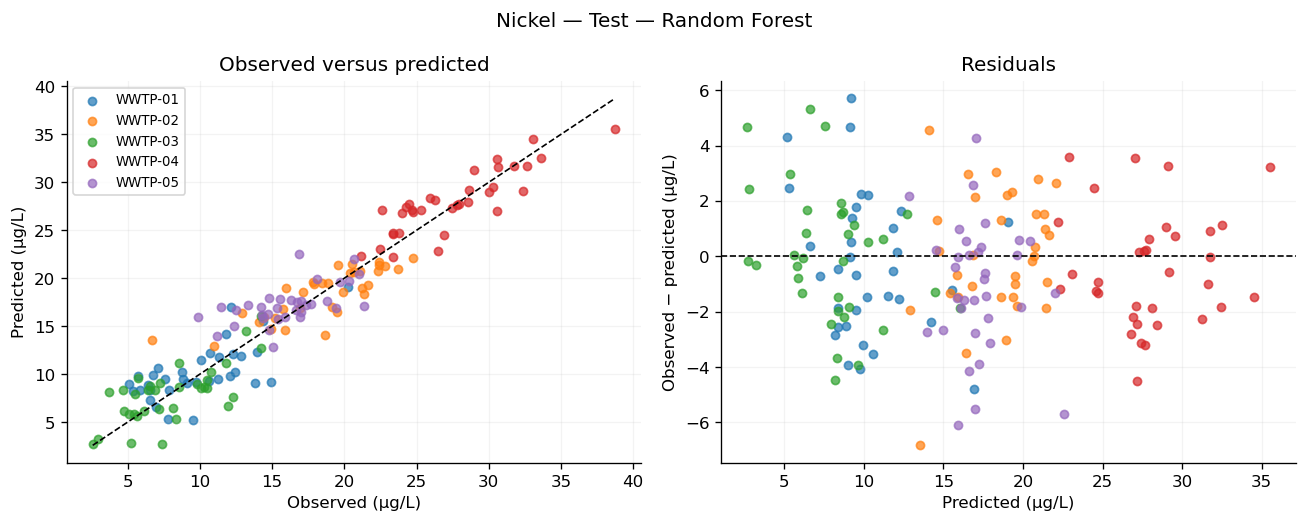

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,2.0954,-0.3514
1,WWTP-02,34,1.7631,0.0460
2,WWTP-03,34,1.8624,0.0412
3,WWTP-04,34,1.7414,-0.4228
4,WWTP-05,34,1.9252,-1.1171


In [1254]:
plot_diagnostics(ni_test_predictions,'Nickel','µg/L',ni_best_name,
                 'Test','ni_test_diagnostics')
display(plant_summary(ni_test_predictions).round(4))

### 12.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Nickel pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1255]:
save_target_results('ni','Nickel','µg/L',ni_target,
    ni_comparison,ni_best_name,ni_validation_ranking,
    ni_train,ni_validation,ni_development,ni_test,
    ni_final_pipeline,ni_mean_baseline,ni_validation_errors,
    ni_test_predictions,ni_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/ni
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 13 Manganese prediction

**Target:** `effluent_manganese_ug_l`. **Unit:** µg/L. This section contains the complete Manganese experiment in the same order as the original notebook. All figures and tables below concern Manganese; the test period is reserved until the algorithm is selected.

### 13.1 Prepare the Manganese data

**Why this step?** We predict Manganese, so only rows missing this target are excluded. Missing values in other outcomes do not affect this task. X contains predictors; y contains the observed target; dates preserve temporal order.

**Output to examine:** Usable and missing target counts, X/y shapes, and a preview of inputs beside the target.

In [1256]:
mn_target = 'effluent_manganese_ug_l'
mn_known = data[mn_target].notna()
mn_frame = data.loc[mn_known].copy()
mn_X = mn_frame[FEATURES].copy()
mn_y = mn_frame[mn_target].copy()
mn_dates = mn_frame['observation_date'].copy()
assert mn_X.index.equals(mn_y.index)
print('Missing target rows excluded:', int((~mn_known).sum()))
print('X shape:', mn_X.shape, '| y shape:', mn_y.shape)
display(mn_frame[['record_id','observation_date','plant_id']+NUM[:3]+[mn_target]].head())

Missing target rows excluded: 0
X shape: (850, 17) | y shape: (850,)


,record_id,observation_date,plant_id,influent_flow_m3_day,influent_temperature_c,influent_ph,effluent_manganese_ug_l
0,WQ-0001,2024-01-01,WWTP-01,14366.0,12.8,7.34,14.01
1,WQ-0002,2024-01-01,WWTP-02,19051.0,11.2,7.38,34.78
2,WQ-0003,2024-01-01,WWTP-03,10440.0,10.6,7.20,10.21
3,WQ-0004,2024-01-01,WWTP-04,19115.0,11.9,6.83,36.47
4,WQ-0005,2024-01-01,WWTP-05,12012.0,13.5,7.21,26.48


### 13.2 Split by observation date

**Why this step?** Earlier dates train the candidates, the middle period selects an algorithm, and the last period evaluates the selected pipeline. All plants on one date stay together. We reuse the same date boundaries for every target.

**Output to examine:** A split summary and blue/gold/green count plot. Verify chronological order and that no usable row is lost.

In [1257]:
mn_train_mask = mn_dates < VALID_START
mn_validation_mask = mn_dates.between(VALID_START, TEST_START, inclusive='left')
mn_test_mask = mn_dates >= TEST_START
mn_train = mn_frame.loc[mn_train_mask].copy()
mn_validation = mn_frame.loc[mn_validation_mask].copy()
mn_test = mn_frame.loc[mn_test_mask].copy()
assert len(mn_train)+len(mn_validation)+len(mn_test)==len(mn_frame)
assert mn_train.observation_date.max() < mn_validation.observation_date.min()
assert mn_validation.observation_date.max() < mn_test.observation_date.min()
mn_split_summary = pd.DataFrame([
    {'Split':name,'Rows':len(frame),'First date':frame.observation_date.min().date(),
      'Last date':frame.observation_date.max().date()}
    for name,frame in [('Train',mn_train),('Validation',mn_validation),('Test',mn_test)]])
display(mn_split_summary)


,Split,Rows,First date,Last date
0,Train,510,2024-01-01,2024-04-11
1,Validation,170,2024-04-12,2024-05-15
2,Test,170,2024-05-16,2024-06-18


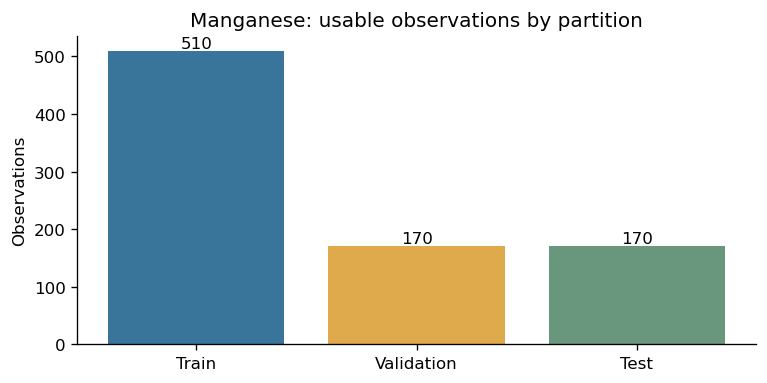

In [1258]:
fig,ax=plt.subplots(figsize=(6.5,3.3))
ax.bar(mn_split_summary['Split'], mn_split_summary['Rows'],
       color=[TRAIN_COLOR,VALIDATION_COLOR,TEST_COLOR])
ax.set(title='Manganese: usable observations by partition',ylabel='Observations')
for i,n in enumerate(mn_split_summary['Rows']):ax.text(i,n,str(n),ha='center',va='bottom')
save_figure(fig,'mn_split_counts')

### 13.3 Preprocess fit and compare candidates

**Why this step?** Imputation and scaling must learn from training data only. Each algorithm receives its own fresh pipeline. We train every candidate once and reuse its predictions for tables and plots.

**Output to examine:** Training predictor missingness and a complete six-metric table for training and validation. The test rows are not passed to comparison.

In [1259]:
display(mn_train[FEATURES].isna().sum().rename('Missing training inputs').rename_axis('Input').reset_index())


,Input,Missing training inputs
0,influent_flow_m3_day,2
1,influent_temperature_c,2
2,influent_ph,0
3,influent_bod_mg_l,1
4,influent_cod_mg_l,1
5,influent_tss_mg_l,0
6,influent_total_nitrogen_mg_l,2
7,influent_total_phosphorus_mg_l,2
8,influent_conductivity_us_cm,3
9,influent_lithium_ug_l,0


In [1260]:
mn_comparison = compare_candidates('Manganese',
    mn_train[FEATURES], mn_train[mn_target],
    mn_validation[FEATURES], mn_validation[mn_target])
display(mn_comparison['metrics'].round(4))

,Target,Model,Split,MAE,MSE,RMSE,R2,RAE,RRSE
0,Manganese,Mean baseline,Train,9.6416,135.8959,11.6574,0.0000,1.0000,1.0000
1,Manganese,Mean baseline,Validation,8.6818,112.0061,10.5833,-0.0002,0.9986,1.0001
2,Manganese,Linear Regression,Train,2.3984,9.2756,3.0456,0.9317,0.2488,0.2613
3,Manganese,Linear Regression,Validation,2.4108,9.4682,3.0770,0.9154,0.2773,0.2908
4,Manganese,Ridge,Train,2.4004,9.2786,3.0461,0.9317,0.2490,0.2613
5,Manganese,Ridge,Validation,2.4122,9.4622,3.0761,0.9155,0.2775,0.2907
6,Manganese,Lasso,Train,2.4243,9.4442,3.0731,0.9305,0.2514,0.2636
7,Manganese,Lasso,Validation,2.3989,9.5199,3.0854,0.9150,0.2759,0.2916
8,Manganese,Decision Tree,Train,1.5175,3.7943,1.9479,0.9721,0.1574,0.1671
9,Manganese,Decision Tree,Validation,3.2214,16.9147,4.1127,0.8490,0.3705,0.3887


### 13.4 Represent the algorithm comparison

**Why this step?** Graphs make training–validation differences and candidate rankings easier to inspect. Separate scales are required because the six metrics have different meanings and units.

**Output to examine:** Six comparison panels. Blue is training and gold is validation. Lower MAE/MSE/RMSE/RAE/RRSE and higher R² are preferable.

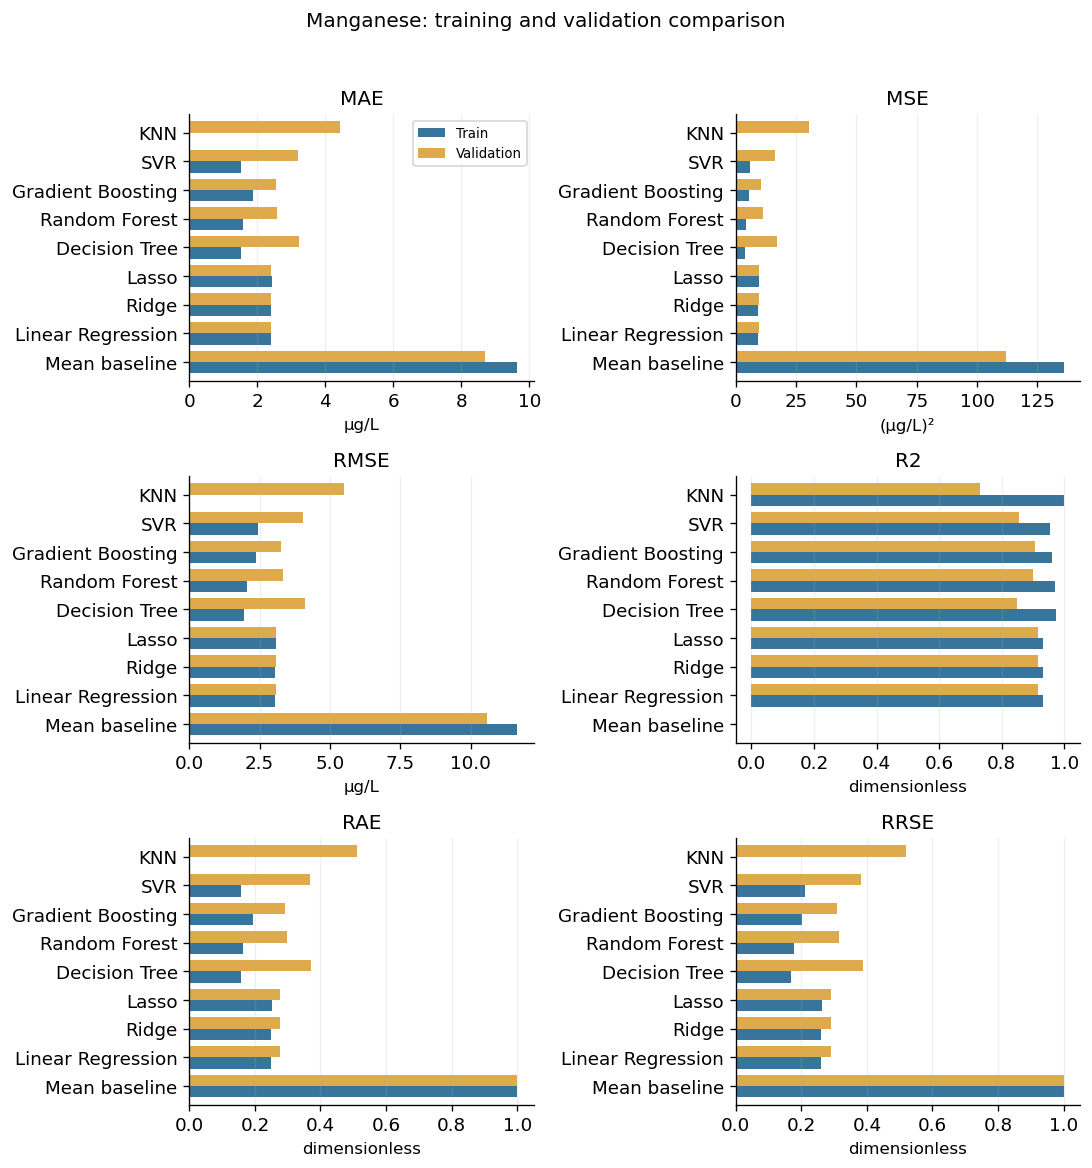

In [1261]:
plot_comparison(mn_comparison['metrics'],'Manganese','µg/L','comparison_manganese')

### 13.5 Select the algorithm using validation MAE

**Why this step?** We apply one declared selection rule instead of choosing whichever metric looks best. The gap to the runner-up helps avoid overstating a close ranking. A training–validation difference is diagnostic, not proof of overfitting.

**Output to examine:** Validation ranking, selected algorithm, runner-up MAE margin, and training–validation MAE gaps.

In [1262]:
mn_validation_ranking = (mn_comparison['metrics']
    .loc[lambda frame:frame.Split.eq('Validation')]
    .sort_values('MAE',kind='stable').reset_index(drop=True))
mn_best_name = mn_validation_ranking.loc[0,'Model']
mn_best_training_pipeline = mn_comparison['fitted'][mn_best_name]
display(mn_validation_ranking[['Model','MAE']].round(4))


,Model,MAE
0,Lasso,2.3989
1,Linear Regression,2.4108
2,Ridge,2.4122
3,Gradient Boosting,2.5459
4,Random Forest,2.5823
5,SVR,3.2062
6,Decision Tree,3.2214
7,KNN,4.4457
8,Mean baseline,8.6818


In [1263]:
print('Selected algorithm:',mn_best_name)
print('Validation MAE gap to runner-up:',
      float(mn_validation_ranking.loc[1,'MAE']-mn_validation_ranking.loc[0,'MAE']),'µg/L')
mn_mae_gaps=mn_comparison['metrics'].pivot(index='Model',columns='Split',values='MAE')
mn_mae_gaps['Validation minus train']=mn_mae_gaps.Validation-mn_mae_gaps.Train
display(mn_mae_gaps.round(4))

Selected algorithm: Lasso
Validation MAE gap to runner-up: 0.011922317819128114 µg/L


Split,Train,Validation,Validation minus train
Model,,,
Decision Tree,1.5175,3.2214,1.7039
Gradient Boosting,1.8722,2.5459,0.6737
KNN,0.0000,4.4457,4.4457
Lasso,2.4243,2.3989,-0.0254
Linear Regression,2.3984,2.4108,0.0124
Mean baseline,9.6416,8.6818,-0.9598
Random Forest,1.5844,2.5823,0.9979
Ridge,2.4004,2.4122,0.0118
SVR,1.5142,3.2062,1.6920


### 13.6 Inspect validation predictions and errors

**Why this step?** The selected training-fitted pipeline has already predicted validation rows. We reuse those predictions to see individual errors, plant differences, and systematic underprediction or overprediction.

**Output to examine:** Prediction preview, plant-level MAE, observed-versus-predicted plot, and residual plot. Positive residuals mean underprediction.

In [1264]:
mn_validation_pred = mn_comparison['predictions'][mn_best_name]['Validation']
mn_validation_errors = error_frame(mn_validation,mn_validation[mn_target],mn_validation_pred)
display(mn_validation_errors.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error
510,WQ-0511,2024-04-12,WWTP-01,21.77,14.5975,7.1725,7.1725
511,WQ-0512,2024-04-12,WWTP-02,24.47,30.3378,-5.8678,5.8678
512,WQ-0513,2024-04-12,WWTP-03,21.00,18.5959,2.4041,2.4041
513,WQ-0514,2024-04-12,WWTP-04,39.35,39.4809,-0.1309,0.1309
514,WQ-0515,2024-04-12,WWTP-05,21.06,23.6767,-2.6167,2.6167
515,WQ-0516,2024-04-13,WWTP-01,14.91,17.0938,-2.1838,2.1838
516,WQ-0517,2024-04-13,WWTP-02,36.33,36.1058,0.2242,0.2242
517,WQ-0518,2024-04-13,WWTP-03,8.60,9.9873,-1.3873,1.3873
518,WQ-0519,2024-04-13,WWTP-04,36.75,39.8635,-3.1135,3.1135
519,WQ-0520,2024-04-13,WWTP-05,27.59,29.8260,-2.2360,2.2360


,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,2.1802,0.4486
1,WWTP-02,34,2.9417,-2.2937
2,WWTP-03,34,2.2127,0.5784
3,WWTP-04,34,1.9908,-0.8697
4,WWTP-05,34,2.6690,-0.2918


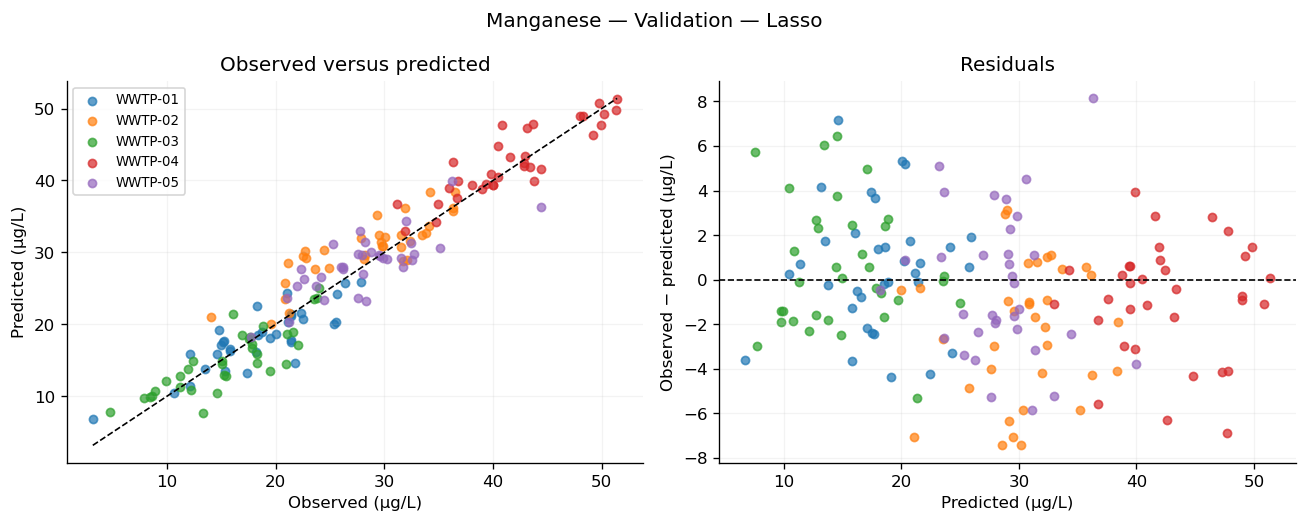

In [1265]:
display(plant_summary(mn_validation_errors).round(4))
plot_diagnostics(mn_validation_errors,'Manganese','µg/L',mn_best_name,
                 'Validation','mn_validation_diagnostics')

### 13.7 Fit the final selected pipeline

**Why this step?** After choosing the algorithm, we combine training and validation rows into development data. A fresh selected pipeline and mean baseline are fitted on those rows. Test outcomes do not determine the selected algorithm.

**Output to examine:** Development and test sample counts, and confirmation that the fitting period precedes testing.

In [1266]:
mn_development = pd.concat([mn_train,mn_validation]).sort_values(['observation_date','plant_id'])
assert set(mn_development.index).isdisjoint(mn_test.index)
assert mn_development.observation_date.max() < mn_test.observation_date.min()
mn_final_pipeline = make_pipeline(MODELS[mn_best_name]).fit(
    mn_development[FEATURES],mn_development[mn_target])
mn_mean_baseline = make_pipeline(MODELS['Mean baseline']).fit(
    mn_development[FEATURES],mn_development[mn_target])
print('Final selected algorithm:',mn_best_name)
print('Development observations:',len(mn_development),'| test observations:',len(mn_test))
print('Last fitting date:',mn_development.observation_date.max().date())
print('First test date:',mn_test.observation_date.min().date())

Final selected algorithm: Lasso
Development observations: 680 | test observations: 170
Last fitting date: 2024-05-15
First test date: 2024-05-16


### 13.8 Predict the test period and report metrics

**Why this step?** The reserved period estimates later-date performance of the previously selected pipeline. Comparing it with the fitted mean baseline shows whether it improves on a simple reference. Predictions are cached once.

**Output to examine:** A prediction preview, all six test metrics, and percentage MAE reduction. R² and MAE reduction must not be described as accuracy.

In [1267]:
mn_test_pred = mn_final_pipeline.predict(mn_test[FEATURES])
mn_baseline_pred = mn_mean_baseline.predict(mn_test[FEATURES])
mn_test_predictions = error_frame(mn_test,mn_test[mn_target],mn_test_pred)
mn_test_predictions['mean_baseline'] = mn_baseline_pred
mn_test_metrics = pd.DataFrame([
    {'Target':'Manganese','Unit':'µg/L','Model':mn_best_name,
      **metrics(mn_test[mn_target],mn_test_pred)},
    {'Target':'Manganese','Unit':'µg/L','Model':'Mean baseline',
      **metrics(mn_test[mn_target],mn_baseline_pred)}])
mn_mae_reduction = 100*(1-mn_test_metrics.loc[0,'MAE']/mn_test_metrics.loc[1,'MAE'])
display(mn_test_predictions.head(10).round(4))


,record_id,observation_date,plant_id,actual,predicted,residual,absolute_error,mean_baseline
680,WQ-0681,2024-05-16,WWTP-01,24.74,24.1863,0.5537,0.5537,26.318
681,WQ-0682,2024-05-16,WWTP-02,27.26,31.2923,-4.0323,4.0323,26.318
682,WQ-0683,2024-05-16,WWTP-03,12.89,14.7136,-1.8236,1.8236,26.318
683,WQ-0684,2024-05-16,WWTP-04,40.93,39.6771,1.2529,1.2529,26.318
684,WQ-0685,2024-05-16,WWTP-05,31.53,30.5980,0.9320,0.9320,26.318
685,WQ-0686,2024-05-17,WWTP-01,19.98,16.7363,3.2437,3.2437,26.318
686,WQ-0687,2024-05-17,WWTP-02,30.52,28.6245,1.8955,1.8955,26.318
687,WQ-0688,2024-05-17,WWTP-03,17.57,18.9344,-1.3644,1.3644,26.318
688,WQ-0689,2024-05-17,WWTP-04,38.23,32.7412,5.4888,5.4888,26.318
689,WQ-0690,2024-05-17,WWTP-05,17.52,22.5839,-5.0639,5.0639,26.318


In [1268]:
display(mn_test_metrics.round(4))
print('Test MAE:',round(mn_test_metrics.loc[0,'MAE'],4),'µg/L')
print('MAE reduction relative to the fitted mean:',round(mn_mae_reduction,2),'%')
print('R² describes relative squared error, not percentage accuracy.')

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,Manganese,µg/L,Lasso,2.490,9.9093,3.1479,0.9178,0.2729,0.2867
1,Manganese,µg/L,Mean baseline,9.131,120.5893,10.9813,-0.0004,1.0006,1.0002


Test MAE: 2.49 µg/L
MAE reduction relative to the fitted mean: 72.73 %
R² describes relative squared error, not percentage accuracy.


### 13.9 Represent test predictions and plant errors

**Why this step?** A summary score can hide high individual errors and plant-specific bias. These graphs use test predictions from the preceding cell and do not train another model.

**Output to examine:** Test scatter/residual plots and plant-level sample counts, MAE, and mean residual. Plant colors match the validation plots and report panels.

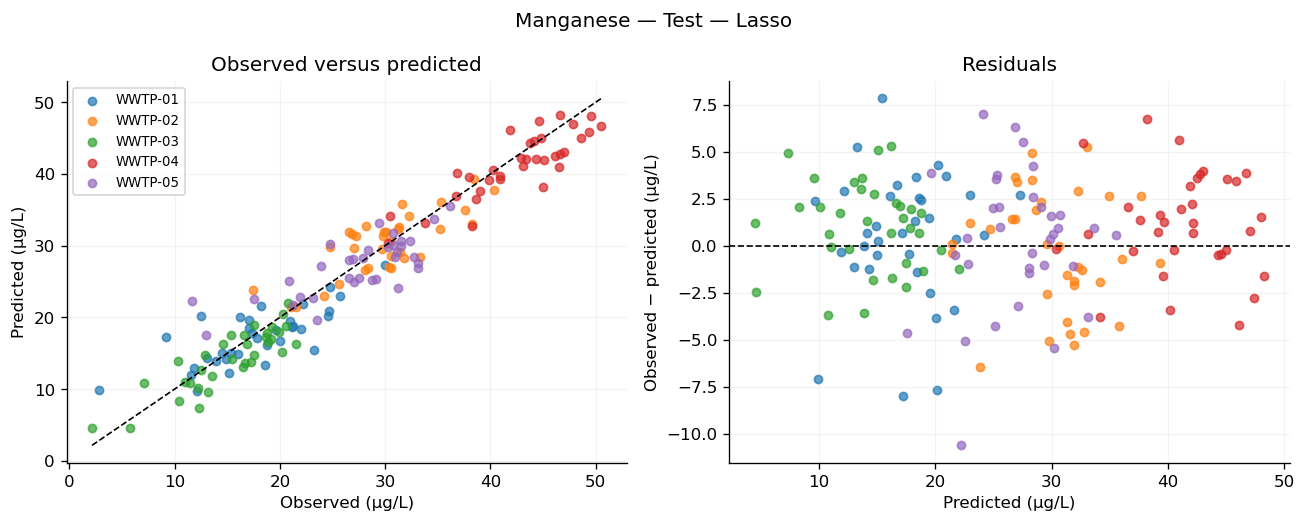

,plant_id,n,MAE,Mean_residual
0,WWTP-01,34,2.6592,0.4520
1,WWTP-02,34,2.5655,-0.3079
2,WWTP-03,34,2.1238,0.9804
3,WWTP-04,34,2.3158,1.1862
4,WWTP-05,34,2.7857,0.2193


In [1269]:
plot_diagnostics(mn_test_predictions,'Manganese','µg/L',mn_best_name,
                 'Test','mn_test_diagnostics')
display(plant_summary(mn_test_predictions).round(4))

### 13.10 Save this experiment

**Why this step?** Saving preprocessing with the estimator preserves the complete prediction procedure. Metric and prediction files make the reported results traceable without repeating training.

**Output to examine:** The saved Manganese pipeline, tables, and output folder. The state is retained for combined report figures and supplementary analysis.

In [1270]:
save_target_results('mn','Manganese','µg/L',mn_target,
    mn_comparison,mn_best_name,mn_validation_ranking,
    mn_train,mn_validation,mn_development,mn_test,
    mn_final_pipeline,mn_mean_baseline,mn_validation_errors,
    mn_test_predictions,mn_test_metrics)

Saved: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs/mn
Files: selected_pipeline.joblib, test_errors_by_plant.csv, test_metrics.csv, test_predictions.csv, train_validation_metrics.csv, validation_predictions.csv, validation_ranking.csv


## 14 Combine primary results and compute validation importance

All ten separate experiments are now complete. This section combines their existing outputs for the report. It does not fit the primary candidates again. Permutation importance uses each selected **training-fitted** pipeline on validation data, rather than a development-fitted model on rows it has already seen. The shuffle standard deviation is not a confidence interval.

In [1271]:
comparisons, tests, predictions, importances, selections, timing = [], [], [], [], [], []
primary_fitted={}


In [1272]:
for label,column,unit in TARGETS:
    result=results[label]
    comparisons.extend(result['comparison']['metrics'].to_dict('records'))
    tests.extend(result['test_metrics'].to_dict('records'))
    ranking=result['ranking']
    selections.append({'Target':label,'Selected':result['selected'],
        'Validation MAE':ranking.loc[0,'MAE'],'Runner up':ranking.loc[1,'Model'],
        'MAE gap':ranking.loc[1,'MAE']-ranking.loc[0,'MAE']})
    frame=result['test_predictions'].copy()
    frame['Target'],frame['Unit'],frame['Selected']=label,unit,result['selected']
    predictions.append(frame)
    primary_fitted[label]=result['comparison']['fitted'][result['selected']]
    validation=result['validation']
    perm=permutation_importance(primary_fitted[label],validation[FEATURES],validation[column],
        scoring='neg_mean_absolute_error',n_repeats=20,random_state=SEED,n_jobs=1)
    importances.extend({'Target':label,'Feature':feature,'MAE increase':mean,'Shuffle SD':sd}
        for feature,mean,sd in zip(FEATURES,perm.importances_mean,perm.importances_std))
    joblib.dump(result['final'],OUT/'models'/f'{label.lower().replace(" ","_")}.joblib')
    for boundary,fitting,evaluation in [('Validation',result['train'],result['validation']),
                                        ('Test',result['development'],result['test'])]:
        inferred=fitting.observation_date.max()+pd.Timedelta(days=1)
        timing.append({'Target':label,'Boundary':boundary,
            'Last fitting observation':fitting.observation_date.max(),'Inferred last label date':inferred,
            'First evaluation observation':evaluation.observation_date.min(),
            'Strict calendar separation':bool(inferred<evaluation.observation_date.min())})
comparison=save_table(pd.DataFrame(comparisons),'train_validation_metrics')
selection=save_table(pd.DataFrame(selections),'selection')
importance=save_table(pd.DataFrame(importances),'permutation_importance')
save_table(pd.DataFrame(timing),'timing_audit')


,Target,Boundary,Last fitting observation,Inferred last label date,First evaluation observation,Strict calendar separation
0,pH,Validation,2024-04-11,2024-04-12,2024-04-12,False
1,pH,Test,2024-05-15,2024-05-16,2024-05-16,False
2,BOD,Validation,2024-04-11,2024-04-12,2024-04-12,False
3,BOD,Test,2024-05-15,2024-05-16,2024-05-16,False
4,COD,Validation,2024-04-11,2024-04-12,2024-04-12,False
5,COD,Test,2024-05-15,2024-05-16,2024-05-16,False
6,TSS,Validation,2024-04-11,2024-04-12,2024-04-12,False
7,TSS,Test,2024-05-15,2024-05-16,2024-05-16,False
8,Total nitrogen,Validation,2024-04-11,2024-04-12,2024-04-12,False
9,Total nitrogen,Test,2024-05-15,2024-05-16,2024-05-16,False


In [1273]:
display(selection.round(4))


,Target,Selected,Validation MAE,Runner up,MAE gap
0,pH,Ridge,0.1026,Linear Regression,0.0001
1,BOD,SVR,6.0147,Linear Regression,0.0218
2,COD,Linear Regression,10.9075,Ridge,0.0124
3,TSS,Lasso,4.2059,Gradient Boosting,0.0482
4,Total nitrogen,Linear Regression,1.4606,Ridge,0.0008
5,Total phosphorus,Ridge,0.2306,Linear Regression,0.0001
6,Lithium,Ridge,1.7429,Linear Regression,0.0032
7,Cobalt,Linear Regression,0.8703,Ridge,0.0005
8,Nickel,Random Forest,1.7616,Lasso,0.0284
9,Manganese,Lasso,2.3989,Linear Regression,0.0119


In [1274]:
display(pd.DataFrame(tests).round(4))

,Target,Unit,Model,MAE,MSE,RMSE,R2,RAE,RRSE
0,pH,pH units,Ridge,0.1075,0.0177,0.1331,0.1453,0.9237,0.9245
1,pH,pH units,Mean baseline,0.1168,0.0212,0.1454,-0.0204,1.0041,1.0101
2,BOD,mg/L,SVR,5.6671,61.7933,7.8609,0.3948,0.6888,0.7779
3,BOD,mg/L,Mean baseline,8.2257,102.1054,10.1047,-0.0000,0.9997,1.0000
4,COD,mg/L,Linear Regression,10.1650,171.2757,13.0872,0.6711,0.5543,0.5735
5,COD,mg/L,Mean baseline,18.3274,520.8062,22.8212,-0.0000,0.9993,1.0000
6,TSS,mg/L,Lasso,3.9190,24.5139,4.9512,0.4459,0.7453,0.7443
7,TSS,mg/L,Mean baseline,5.3245,44.4862,6.6698,-0.0055,1.0127,1.0027
8,Total nitrogen,mg/L,Linear Regression,1.3781,2.9499,1.7175,0.6826,0.5573,0.5633
9,Total nitrogen,mg/L,Mean baseline,2.4656,9.3009,3.0497,-0.0006,0.9970,1.0003


## 15 Supplementary benchmarks retained from the revised report

This section is separate from the original target-by-target experiment. We compare the selected pipeline with a median constant predictor and a linear model using only the corresponding influent measurement. These checks do not change any primary selection. The existing test results were inspected in earlier work, so these are retrospective analyses, not a new untouched confirmation.

In [1275]:
for frame in predictions:
    label=frame['Target'].iloc[0]
    result=results[label]
    column=result['column'];unit=result['unit'];dev=result['development'];test=result['test']
    corresponding='influent_ph' if column=='effluent_ph' else column.replace('effluent_','influent_')
    single=make_pipeline(LinearRegression(),[corresponding]).fit(dev[[corresponding]],dev[column])
    median=make_pipeline(DummyRegressor(strategy='median')).fit(dev[FEATURES],dev[column])
    frame['single_influent']=single.predict(test[[corresponding]])
    frame['median_baseline']=median.predict(test[FEATURES])
    for name,pred_col in [('Median baseline','median_baseline'),('Single influent linear','single_influent')]:
        tests.append({'Target':label,'Unit':unit,'Model':name,**metrics(frame.actual,frame[pred_col])})
test_metrics=save_table(pd.DataFrame(tests),'test_metrics')
prediction_table=save_table(pd.concat(predictions,ignore_index=True),'test_predictions')


In [1276]:
summary_rows=[]
for label,_,unit in TARGETS:
    target_metrics=test_metrics[test_metrics.Target.eq(label)].set_index('Model')
    name=results[label]['selected'];row=target_metrics.loc[name]
    summary_rows.append({'Target':label,'Selected':name,'Unit':unit,
        **{k:row[k] for k in ['MAE','MSE','RMSE','R2','RAE','RRSE']},
        'Mean MAE':target_metrics.loc['Mean baseline','MAE'],
        'Median MAE':target_metrics.loc['Median baseline','MAE'],
        'Single influent MAE':target_metrics.loc['Single influent linear','MAE'],
        'MAE reduction percent':100*(1-row.MAE/target_metrics.loc['Mean baseline','MAE'])})
summary=save_table(pd.DataFrame(summary_rows),'selected_test_summary')
plant_errors=save_table(prediction_table.groupby(['Target','plant_id']).agg(
    n=('actual','size'),MAE=('absolute_error','mean'),Mean_residual=('residual','mean')).reset_index(),'plant_errors')


In [1277]:
interval_rows=[]
for label,_,unit in TARGETS:
    target_predictions=prediction_table[prediction_table.Target.eq(label)]
    for reference in ['mean_baseline','single_influent']:
        estimate,lo,hi=date_block_interval(target_predictions,reference)
        interval_rows.append({'Target':label,'Reference':reference,'Unit':unit,
            'MAE advantage':estimate,'Lower 95':lo,'Upper 95':hi})
intervals=save_table(pd.DataFrame(interval_rows),'paired_block_bootstrap')
display(summary.round(4))
display(intervals.round(4))
print('Interpretation: the matching-influent linear model has lower test MAE for pH, cobalt, and nickel.')
print('Intervals are exploratory, conditional on fixed fitted models, and use only 34 test dates.')

,Target,Selected,Unit,MAE,MSE,RMSE,R2,RAE,RRSE,Mean MAE,Median MAE,Single influent MAE,MAE reduction percent
0,pH,Ridge,pH units,0.1075,0.0177,0.1331,0.1453,0.9237,0.9245,0.1168,0.1167,0.1061,8.0103
1,BOD,SVR,mg/L,5.6671,61.7933,7.8609,0.3948,0.6888,0.7779,8.2257,7.8226,7.1220,31.1043
2,COD,Linear Regression,mg/L,10.1650,171.2757,13.0872,0.6711,0.5543,0.5735,18.3274,18.0830,12.4805,44.5366
3,TSS,Lasso,mg/L,3.9190,24.5139,4.9512,0.4459,0.7453,0.7443,5.3245,5.1690,4.1458,26.3968
4,Total nitrogen,Linear Regression,mg/L,1.3781,2.9499,1.7175,0.6826,0.5573,0.5633,2.4656,2.4527,1.5508,44.1057
5,Total phosphorus,Ridge,mg/L,0.2390,0.0843,0.2903,0.4992,0.7078,0.7077,0.3382,0.3383,0.2572,29.3280
6,Lithium,Ridge,µg/L,2.0003,7.1580,2.6754,0.9481,0.2123,0.2277,9.4009,9.3522,2.0419,78.7224
7,Cobalt,Linear Regression,µg/L,0.9147,1.2562,1.1208,0.8240,0.4141,0.4195,2.2142,2.2029,0.8999,58.6899
8,Nickel,Random Forest,µg/L,1.8775,5.5695,2.3600,0.9070,0.2939,0.3050,6.4305,6.3641,1.6924,70.8030
9,Manganese,Lasso,µg/L,2.4900,9.9093,3.1479,0.9178,0.2729,0.2867,9.1310,9.2052,2.5075,72.7301


,Target,Reference,Unit,MAE advantage,Lower 95,Upper 95
0,pH,mean_baseline,pH units,0.0094,0.0024,0.0157
1,pH,single_influent,pH units,-0.0014,-0.0062,0.0031
2,BOD,mean_baseline,mg/L,2.5585,1.9980,3.0161
3,BOD,single_influent,mg/L,1.4549,0.8675,1.9835
4,COD,mean_baseline,mg/L,8.1624,6.5597,9.6107
5,COD,single_influent,mg/L,2.3155,1.4176,3.1070
6,TSS,mean_baseline,mg/L,1.4055,0.8393,1.8629
7,TSS,single_influent,mg/L,0.2268,-0.0460,0.4645
8,Total nitrogen,mean_baseline,mg/L,1.0875,0.9160,1.2742
9,Total nitrogen,single_influent,mg/L,0.1726,0.0384,0.3242


Interpretation: the matching-influent linear model has lower test MAE for pH, cobalt, and nickel.
Intervals are exploratory, conditional on fixed fitted models, and use only 34 test dates.


## 16 Supplementary temporal checks

The next code evaluates three expanding windows that lie within the development period, and a separate one-date omission before final test fitting. These checks preserve the revised report analyses. They require separate fits because the fitting dates change; those fits are necessary sensitivity experiments rather than accidental repetition. Primary selections remain fixed. Calendar separation alone cannot establish laboratory-data availability.

In [1278]:
# These are retrospective sensitivity analyses, not a new untouched test evaluation.
# Three expanding windows lie entirely before the original test boundary.
development_dates = dates[dates < TEST_START]
folds = [(68,90),(90,112),(112,136)]
assert len(development_dates) == 136
rolling_rows, gap_rows = [], []
for label, column, unit in TARGETS:
    known = data[data[column].notna()]
    for fold, (start, end) in enumerate(folds, 1):
        boundary = development_dates[start]
        fitting = known[known.observation_date < boundary - pd.Timedelta(days=1)]
        evaluation = known[known.observation_date.isin(development_dates[start:end])]
        assert fitting.observation_date.max()+pd.Timedelta(days=1) < evaluation.observation_date.min()
        for name, estimator in MODELS.items():
            pipe=make_pipeline(estimator).fit(fitting[FEATURES],fitting[column])
            rolling_rows.append({'Target':label,'Fold':fold,'Model':name,'Train n':len(fitting),'Evaluation n':len(evaluation),
                 'Evaluation start':evaluation.observation_date.min(),'Evaluation end':evaluation.observation_date.max(),
                 'MAE':mean_absolute_error(evaluation[column],pipe.predict(evaluation[FEATURES]))})
    # Hold the primary selected algorithm fixed, omit one boundary date, refit once.
    train,val,dev,test = target_frames(column,gap_days=1)
    name=selection.set_index('Target').loc[label,'Selected']
    pipe=make_pipeline(MODELS[name]).fit(dev[FEATURES],dev[column])
    gap_rows.append({'Target':label,'Selected':name,'Development n':len(dev),'Test n':len(test),
                     **metrics(test[column],pipe.predict(test[FEATURES]))})
rolling = save_table(pd.DataFrame(rolling_rows),'rolling_validation')
rolling_summary = save_table(rolling.groupby(['Target','Model']).MAE.agg(['mean','std']).reset_index(), 'rolling_summary')
gap = save_table(pd.DataFrame(gap_rows),'one_day_gap_sensitivity')
show_table(gap[['Target','Selected','MAE','R2']])

          Target          Selected     MAE     R2
              pH             Ridge  0.1078 0.1419
             BOD               SVR  5.6988 0.3918
             COD Linear Regression 10.1376 0.6721
             TSS             Lasso  3.9181 0.4460
  Total nitrogen Linear Regression  1.3805 0.6820
Total phosphorus             Ridge  0.2390 0.4995
         Lithium             Ridge  2.0014 0.9482
          Cobalt Linear Regression  0.9137 0.8243
          Nickel     Random Forest  1.8988 0.9063
       Manganese             Lasso  2.4858 0.9180


## 17 Locate every figure used in the report

The report figures below come from the same cached metrics and predictions as the individual target sections. No primary models are refitted here. Combined panels make it easier to compare targets in the written report. Individual target diagnostic plots remain available above.

| Report figure | Meaning |
|---|---|
| 1 | Recorded seasons and target split counts, shown in Section 2.6 |
| 2 | BOD six-metric comparison, shown in Section 4.4 |
| 3 | Six quality test prediction panels |
| 4 | Four mineral test prediction panels |
| 5 | Test MAE reduction relative to the fitted mean |
| 6 | Quality test residual panels |
| 7 | Mineral test residual panels |
| 8 | Quality validation permutation importance |
| 9 | Mineral validation permutation importance |
| A1 | Target histograms, shown in Section 2.6 |
| B1 and B2 | Complete validation MAE comparisons |

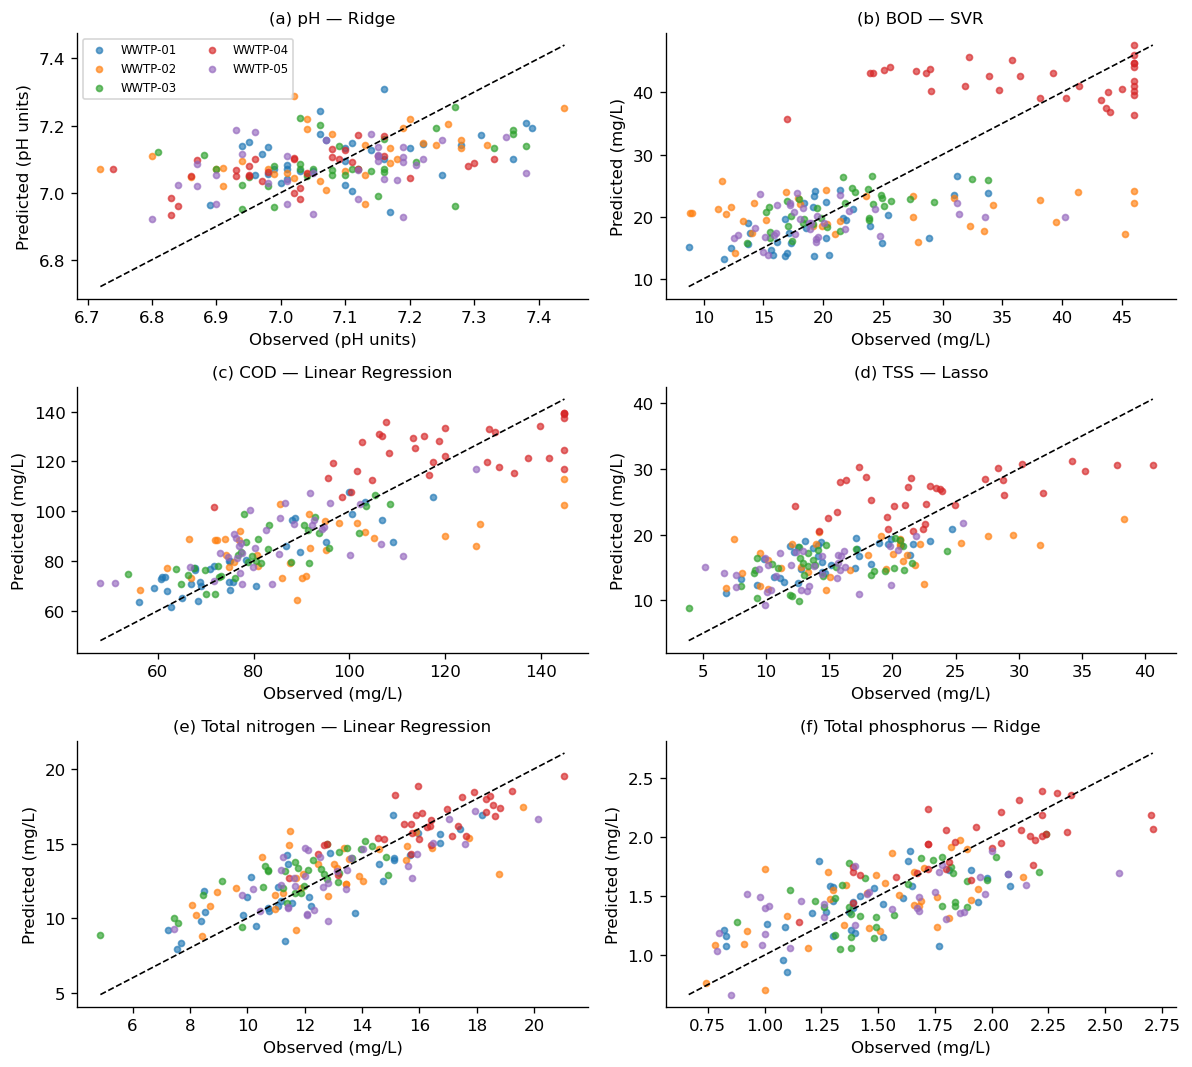

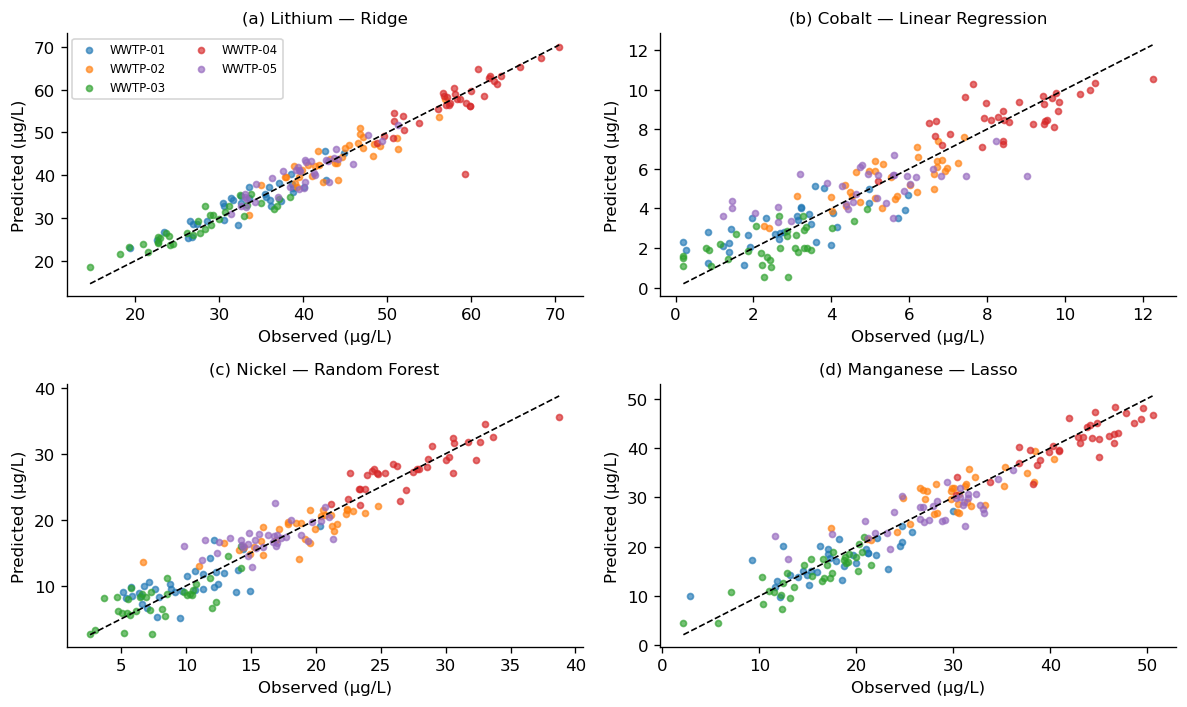

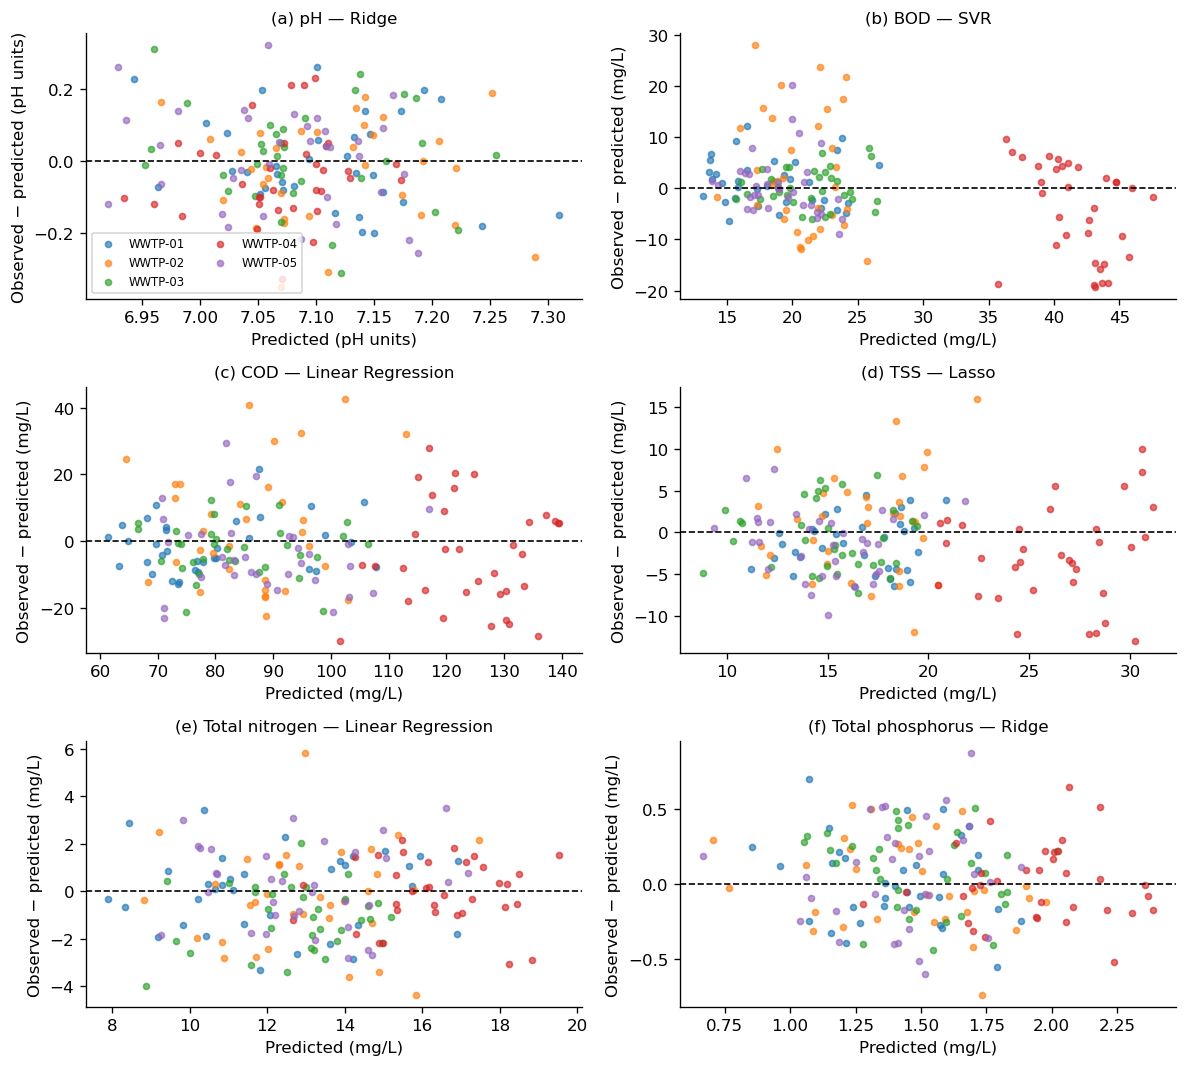

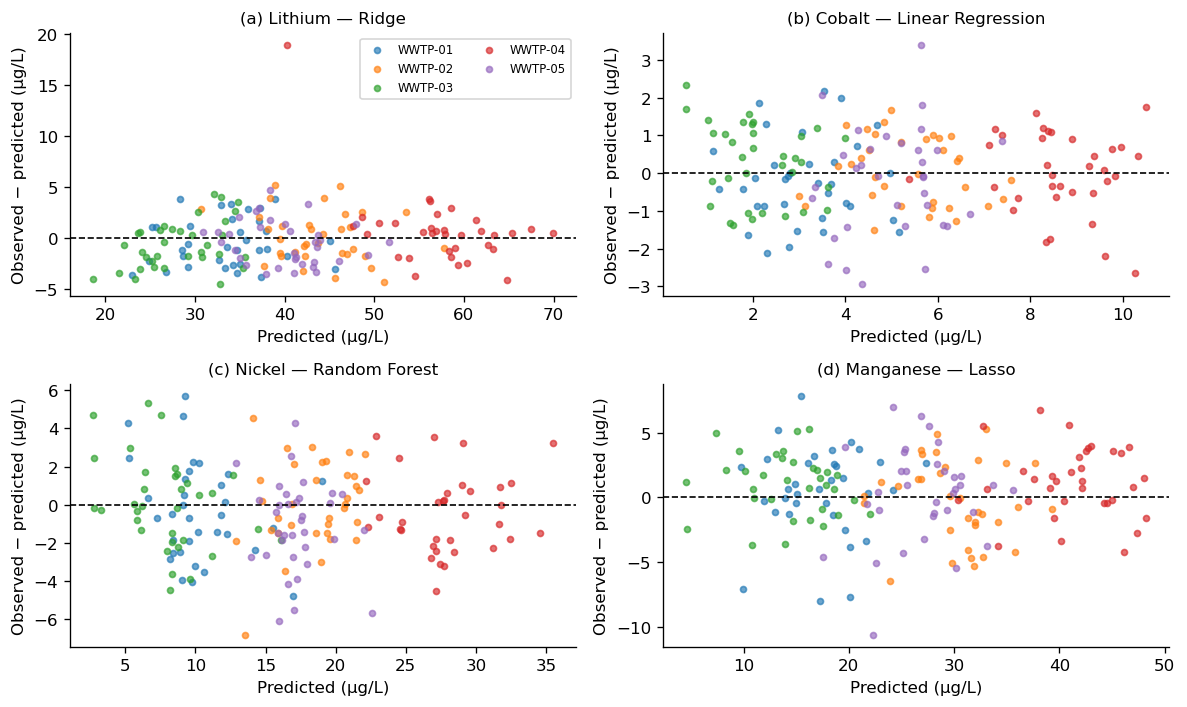

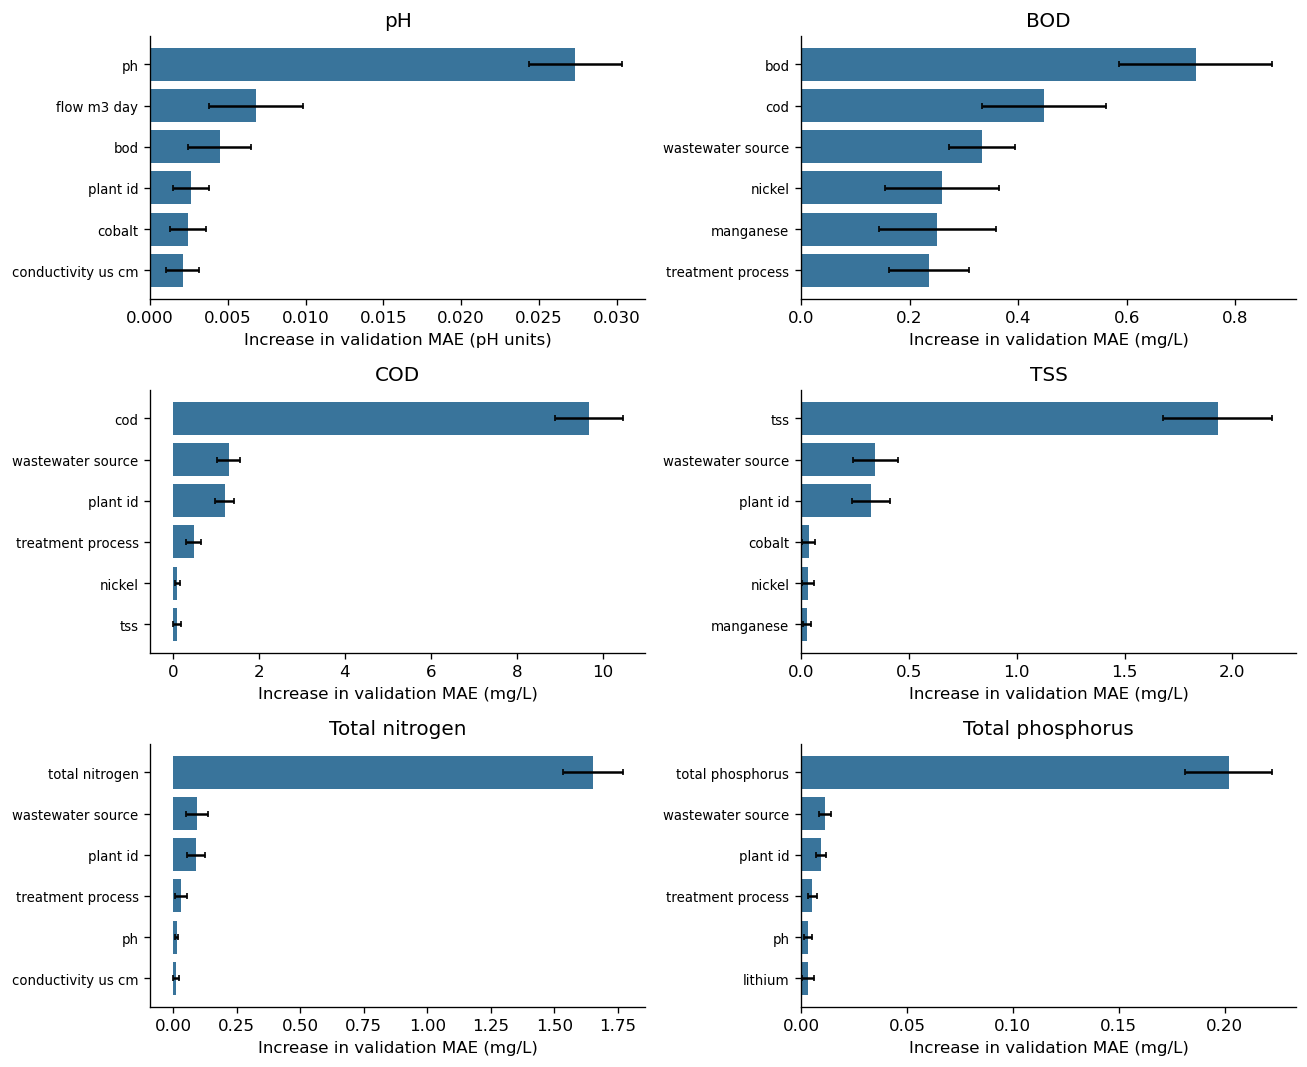

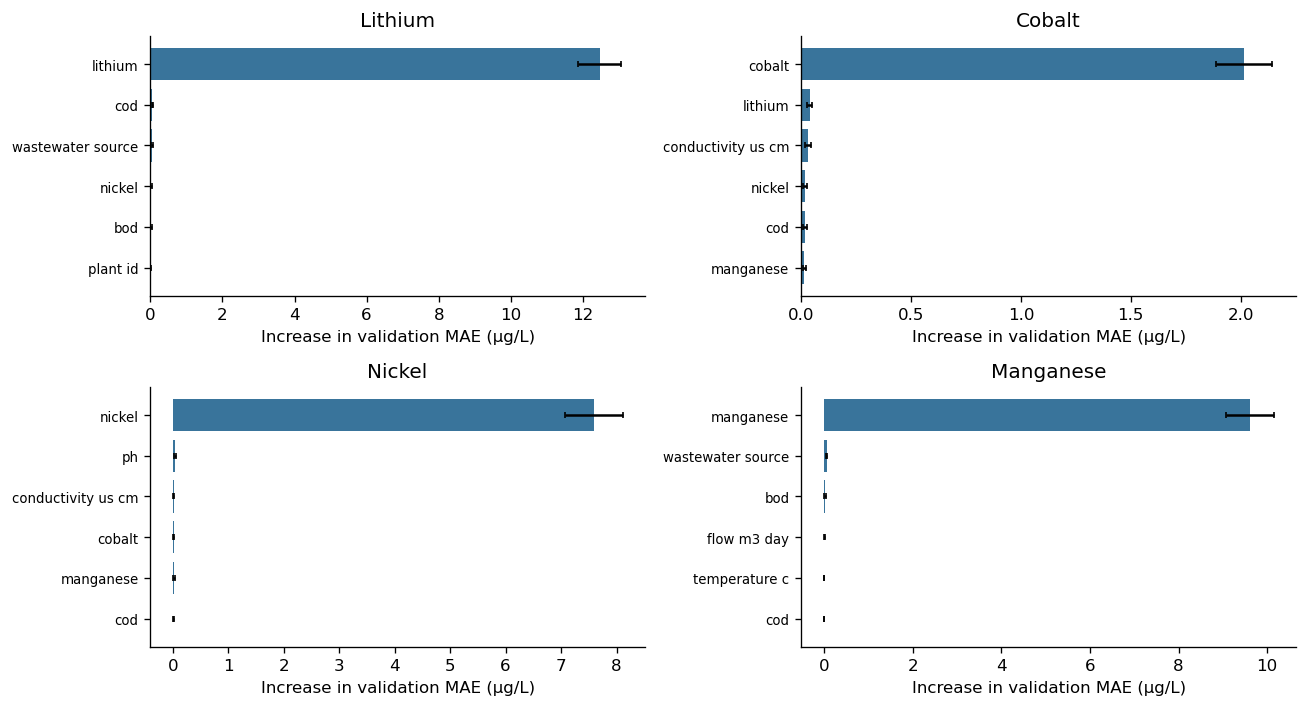

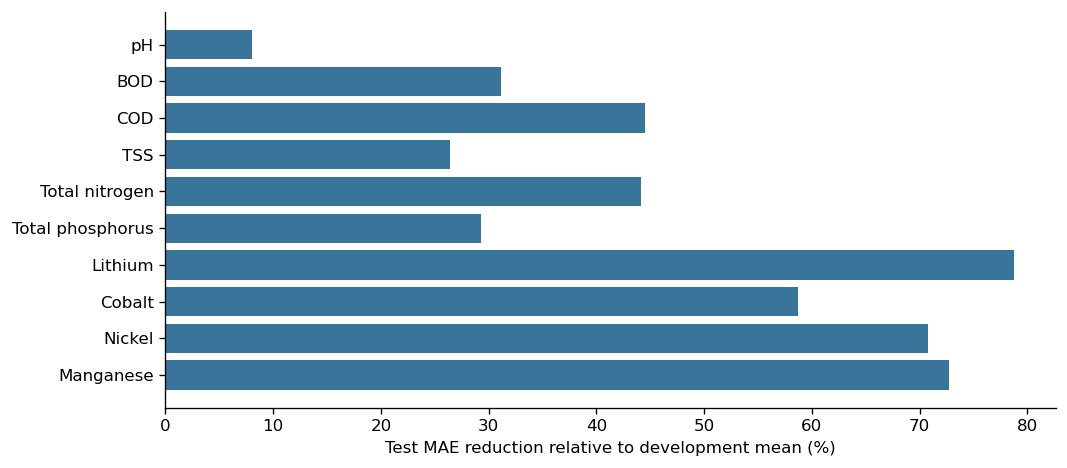

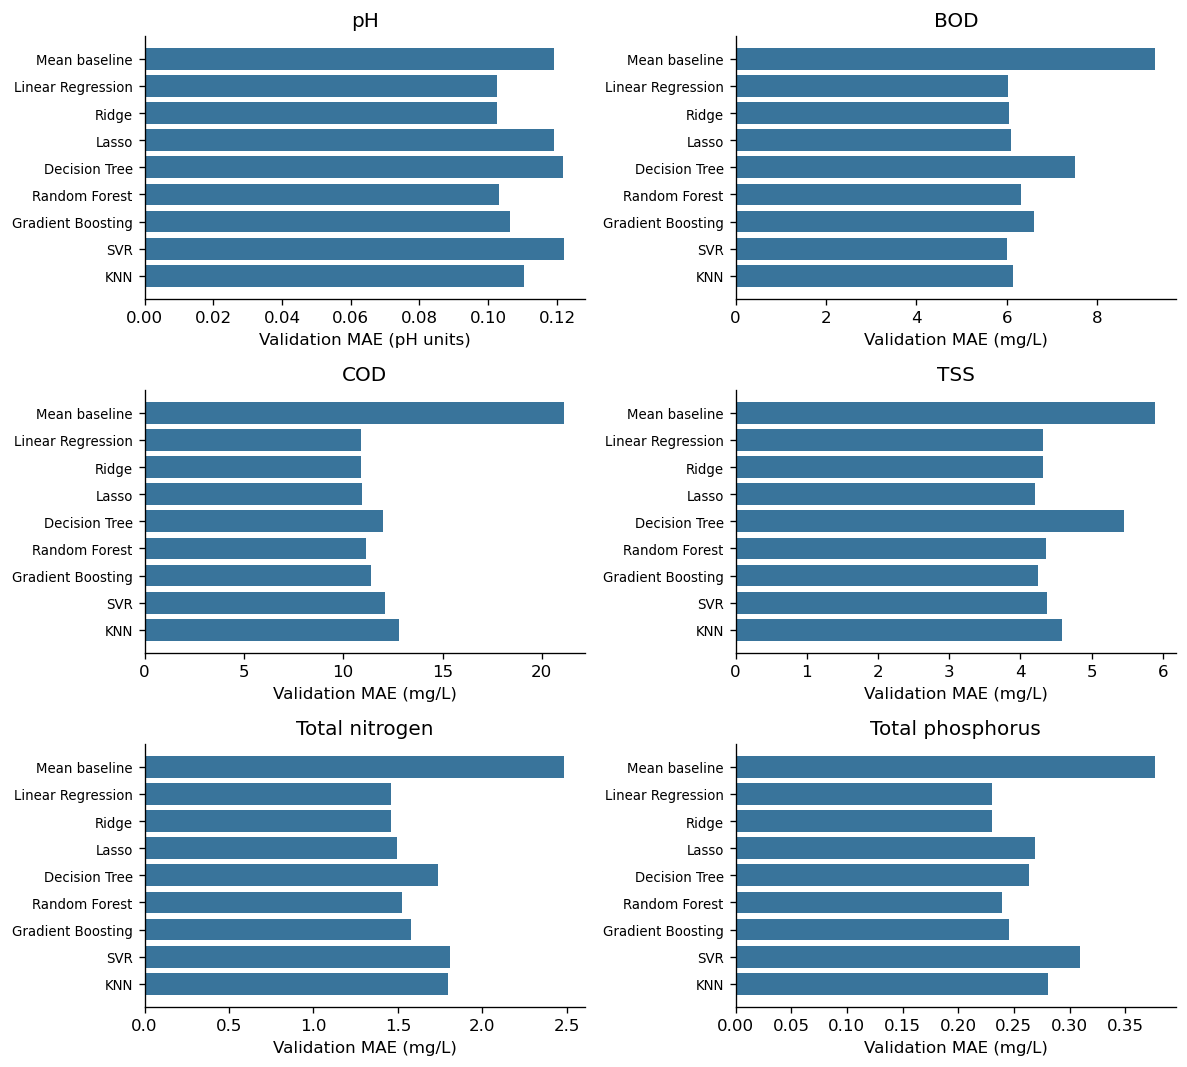

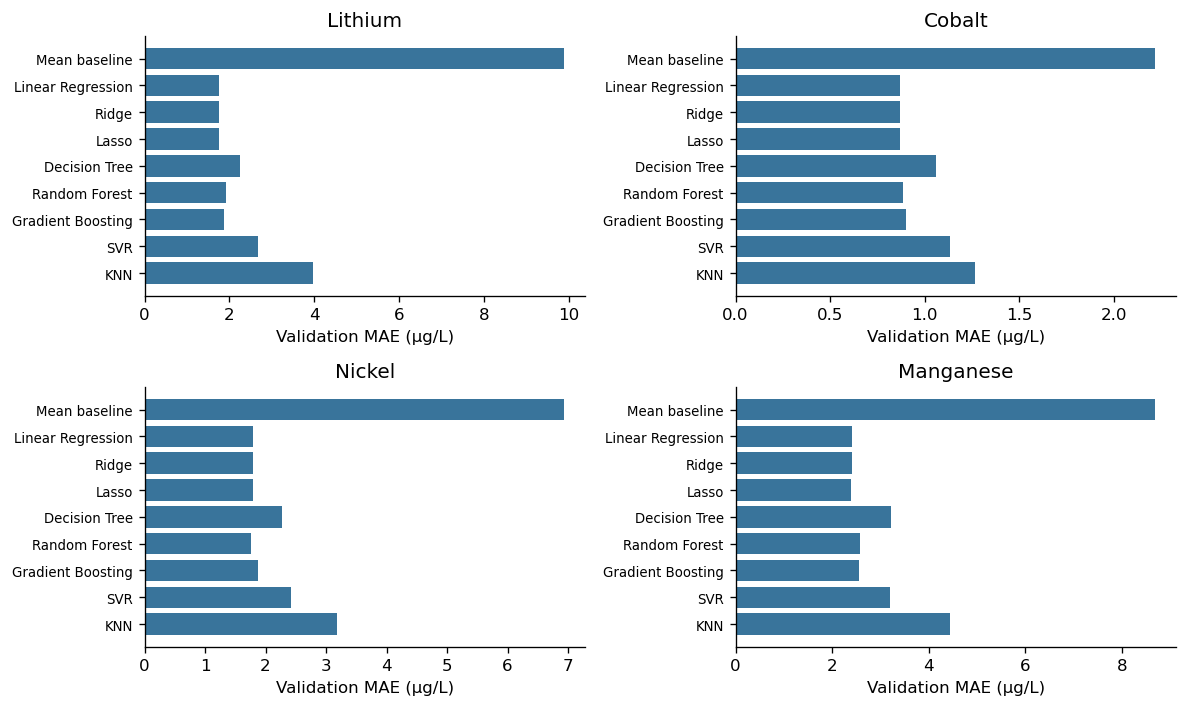

In [1279]:
def prediction_panels(target_list, name, residual=False):
    fig,axes=plt.subplots(int(np.ceil(len(target_list)/2)),2,figsize=(10,3*int(np.ceil(len(target_list)/2))))
    for i,(ax,(label,_,unit)) in enumerate(zip(np.ravel(axes),target_list)):
        p=prediction_table[prediction_table.Target.eq(label)]
        for plant,g in p.groupby('plant_id'):
            ax.scatter(g.predicted if residual else g.actual, g.residual if residual else g.predicted,
                       s=13,alpha=.65,label=plant,color=PLANT_COLORS[plant])
        if residual:
            ax.axhline(0,color='black',lw=1,ls='--')
            ax.set(xlabel=f'Predicted ({unit})',ylabel=f'Observed − predicted ({unit})')
        else:
            low=min(p.actual.min(),p.predicted.min()); high=max(p.actual.max(),p.predicted.max())
            ax.plot([low,high],[low,high],color='black',lw=1,ls='--')
            ax.set(xlabel=f'Observed ({unit})',ylabel=f'Predicted ({unit})')
        ax.set_title(f'({chr(97+i)}) {label} — {p.Selected.iloc[0]}',fontsize=10)
        if i == 0: ax.legend(fontsize=7,ncol=2)
    for ax in np.ravel(axes)[len(target_list):]: ax.set_visible(False)
    save_figure(fig,name)

prediction_panels(TARGETS[:6],'figure_04_quality_predictions')
prediction_panels(TARGETS[6:],'figure_05_mineral_predictions')
prediction_panels(TARGETS[:6],'figure_06_quality_residuals',True)
prediction_panels(TARGETS[6:],'figure_07_mineral_residuals',True)
for group,target_list in [('quality',TARGETS[:6]),('minerals',TARGETS[6:])]:
    fig,axes=plt.subplots(int(np.ceil(len(target_list)/2)),2,figsize=(11,3*int(np.ceil(len(target_list)/2))))
    for ax,(label,_,unit) in zip(np.ravel(axes),target_list):
        top=importance[importance.Target.eq(label)].nlargest(6,'MAE increase').sort_values('MAE increase')
        names=top.Feature.str.replace('influent_','').str.replace('_mg_l','').str.replace('_ug_l','').str.replace('_',' ')
        ax.barh(names,top['MAE increase'],xerr=top['Shuffle SD'],color='#39749b',capsize=2)
        ax.set(title=label,xlabel=f'Increase in validation MAE ({unit})')
        ax.tick_params(axis='y',labelsize=8)
    save_figure(fig,'importance_'+group)
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(summary.Target.iloc[::-1],summary['MAE reduction percent'].iloc[::-1],color='#39749b')
ax.set(xlabel='Test MAE reduction relative to development mean (%)')
save_figure(fig,'figure_08_baseline_reduction')
for group,target_list in [('quality',TARGETS[:6]),('minerals',TARGETS[6:])]:
    fig,axes=plt.subplots(int(np.ceil(len(target_list)/2)),2,figsize=(10,3*int(np.ceil(len(target_list)/2))))
    for ax,(label,_,unit) in zip(np.ravel(axes),target_list):
        c=comparison[comparison.Target.eq(label)&comparison.Split.eq('Validation')].set_index('Model').reindex(list(MODELS))
        ax.barh(c.index[::-1],c.MAE.iloc[::-1],color='#39749b')
        ax.set(title=label,xlabel=f'Validation MAE ({unit})')
        ax.tick_params(axis='y',labelsize=8)
    save_figure(fig,'validation_'+group)

## 18 Reproducibility and final checks

We record the exact workbook checksum, versions, settings, and seed. The assertions reconcile the combined tables with cached predictions and target-specific test counts. The report uses the same primary errors and selected algorithms. A successful run does not establish validity on real plants or a new prospective test sample.

In [1280]:
versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','matplotlib','joblib','openpyxl']}
manifest={'dataset_file':DATA_PATH.name,'dataset_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'python':platform.python_version(),'packages':versions,'seed':SEED,'audit':audit,
    'validation_start':str(VALID_START.date()),'test_start':str(TEST_START.date()),
    'features':FEATURES,'targets':TARGETS,'model_settings':{k:repr(v) for k,v in MODELS.items()},
    'primary_protocol':'60/20/20 dates; validation MAE selection; train plus validation refit; no primary gap',
    'supplementary_protocol':'single influent and median benchmarks; 3 expanding windows with one date gap; fixed-algorithm one date gap test sensitivity',
    'bootstrap':{'replicates':2000,'block_days':7,'method':'paired circular moving blocks of dates retaining all plants'},
    'test_status':'Previously inspected in the original notebook; no independent prospective confirmation.'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
assert len(comparison)==10*9*2 and len(test_metrics)==10*4
assert len(importance)==10*len(FEATURES)
assert len(rolling)==10*3*9
for label,_,_ in TARGETS:
    p=prediction_table[prediction_table.Target.eq(label)]
    s=summary.set_index('Target').loc[label]
    assert np.isclose(s.MAE,np.abs(p.actual-p.predicted).mean())
    assert len(p)==availability.set_index('Target').loc[label,'Test']
assert not prediction_table[['actual','predicted','mean_baseline','single_influent']].isna().any().any()
print('Completed: 10 targets, 9 primary candidates, 3 development validation windows, 10 saved pipelines.')
print('Outputs:',OUT.resolve())

print('Separate target sections completed:', ', '.join(results))
print('Stepwise outputs:',STEP_OUT.resolve())

Completed: 10 targets, 9 primary candidates, 3 development validation windows, 10 saved pipelines.
Outputs: /Users/snehadeepikavemanapalli/Downloads/research_outputs
Separate target sections completed: BOD, COD, TSS, Total nitrogen, Total phosphorus, pH, Lithium, Cobalt, Nickel, Manganese
Stepwise outputs: /Users/snehadeepikavemanapalli/Downloads/stepwise_outputs


## Reading the outputs for your report

- **Data inspection:** explain sample size, synthetic origin, missingness handling, duplicate checks, and limited seasonal coverage. Avoid inserting every `head()` or `info()` output into the report.
- **Methods:** describe the 17 inputs, chronological partitions, preprocessing, candidate settings, validation-MAE selection, and development refitting. Place the split-count figure after the partition explanation.
- **Quality results:** use the selected-model test table, BOD six-metric example, and the six quality prediction panels. Put the other full comparisons in Appendix B.
- **Mineral results:** use the mineral test table and four mineral prediction panels. Keep units in µg/L.
- **Diagnostics and interpretation:** show plant errors, residuals, and permutation importance after the main prediction results. Explain underprediction and plant differences without claiming causation.
- **Discussion:** explain what the results mean, close rankings, the stronger simple benchmarks, and the limits of synthetic data. Do not repeat all numeric tables in prose.

The revised report already includes the supplementary analyses in Sections 15–16. If you discuss only the original primary experiment with your professor, distinguish those additional checks from the original work.

**References:** the accompanying report cites the supplied workbook; Li et al. (2024), DOI 10.1007/s11783-024-1791-x; Wang et al. (2026), DOI 10.1016/j.watres.2026.125558; Pedregosa et al. (2011), JMLR 12:2825–2830; and official scikit-learn guidance on leakage and permutation importance.
